# Double KO: ATF6 + IRE1 (ERN1), scrna

`Benchmark-DQN.ipynb`의 counts → CP10K → log1p → DEG → VAE → 고정 UMAP → DQN 파이프라인을 사용합니다.
학습용 `adata`에는 **3x_neg_ctrl_pMJ144-2 / ATF6_IRE1_pMJ152**만 조건 순서대로 정렬하여 유지합니다.
IRE1의 공식 gene symbol은 **ERN1**이며 gene 이름을 임의로 바꾸지 않습니다.

- VAE 입력: 기존 설정과 같은 3,000 genes / latent 128D. 필수 유전자는 ATF6, ERN1 및 기존 UPR marker 5개(7개).
- 평가: 학습 DEG 순위의 1,993 non-required + 위 7개로 공통 2,000개 패널을 한 번 고정합니다.
  기존 단일 ATF6 실험의 2,000개 유전자 목록과는 다르지만 다섯 지표 정의는 그대로 사용합니다.
- 5–8번은 두 조건 사이의 초기 진단 경로입니다. **최종 virtual double KO는 14번의 동시 감소 보상 DQN**입니다.
- 사용자 지정 Leiden 제외 셀에서 남긴 세포를 이후 DQN·density·double-KO 평가에 그대로 사용합니다.
  원본 9–11번의 단일 ATF6-zero / TF network 추가 분석은 이번 동시 KO 평가가 아니므로 포함하지 않습니다.
- 비교군: **ATF6_IRE1_pMJ152 / ATF6_only_pMJ145 / IRE1_only_pMJ148**.
  최초 PERK_IRE1 요청은 확인 답변에 따라 ATF6_IRE1로 변경했습니다.
  Single-KO 세포는 VAE·DEG·UMAP·DQN·density 학습에 사용하지 않습니다.
- 동일한 density Gaussian virtual double-KO population을 세 비교에 재사용하며 세 density band를 합칩니다.
- 평가 패널 발현이 모두 0인 세포는 사용자 승인에 따라 평가에서만 제외하고 barcode·조건·사유를 저장합니다.
  학습 세포는 제거하지 않습니다. 실제 데이터에서 double-KO 3개 / IRE1-only 1개가 해당합니다.
- 실제 double-KO 세포는 DEG/VAE/support에 사용되므로 첫 비교는 독립 holdout 평가가 아닙니다.
  CRISPR knockdown과 완전 gene deletion은 다르며 decoder 궤적은 causal KO 검증이 아닙니다.
  Gaussian 샘플은 DQN 경로 주변 확률 표본으로, target 발현을 강제로 0으로 만들지 않습니다.

모든 코드 셀을 위에서 아래로 실행합니다. 결과는 별도 `scDQN_results/double_ko/`에 저장하여 단일 KO 결과를 보존합니다.


In [1]:
from pathlib import Path
from copy import deepcopy
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scanpy as sc
from scipy import sparse
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

DATA_URL = 'https://zenodo.org/records/7041849/files/AdamsonWeissman2016_GSM2406677_10X005.h5ad?download=1'
ROOT = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/RL')
DATA_PATH = ROOT / 'AdamsonWeissman2016_GSM2406677_10X005.h5ad'
sys.path.insert(0, str(ROOT))
from double_ko import joint_decrease, joint_reward, compare_three_conditions, nonzero_evaluation_mask
assert Path(sys.prefix).name == 'scrna', sys.executable
COMPARISON_CONDITIONS = ['ATF6_IRE1_pMJ152', 'ATF6_only_pMJ145', 'IRE1_only_pMJ148']
KO_TARGETS = ['ATF6', 'ERN1']
CONDITIONS = ['3x_neg_ctrl_pMJ144-2', 'ATF6_IRE1_pMJ152']
SEED = 42
EXPECTED_N_GENES, LATENT_DIM = 3000,128
EPOCHS, PATIENCE, BATCH_SIZE = 200, 20, 128
LEARNING_RATE, BETA, KL_WARMUP_EPOCHS = 1e-3, 0.01, 20

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Python: {sys.executable}\nDevice: {DEVICE}')

CONTROL_CONDITION, ATF6_CONDITION = CONDITIONS
KO_TARGET = 'ATF6'
WORKFLOW_VERSION = 'double_ko_deg2993_required7_fixed_umap_v1'
REQUIRED_GENES = ['ATF6', 'ERN1', 'HSPA5', 'HSP90B1', 'HERPUD1', 'PDIA4', 'CALR']
RESULT_BASE = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko')
RESULT_ROOT = RESULT_BASE / WORKFLOW_VERSION
print(f'Workflow: {WORKFLOW_VERSION}; latent DQN with fixed UMAP display')
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
TF_LIST_PATH = RESULT_BASE.parent / 'allTFs_hg38.txt'
if not TF_LIST_PATH.is_file():
    raise FileNotFoundError(f'Missing human TF reference: {TF_LIST_PATH}')


Python: /home/Data_Drive_8TB/kykim/.conda/envs/scrna/bin/python
Device: cuda
Workflow: double_ko_deg2993_required7_fixed_umap_v1; latent DQN with fixed UMAP display


## 1. perturbation 두 조건 선택 + counts 정규화 + DEG logFC 2,993개 + 필수 7개

Zenodo 원본을 불러와 `obs['perturbation']`이 `3x_neg_ctrl_pMJ144-2`, `ATF6_IRE1_pMJ152`인 세포만 유지합니다. 추가 QC는 적용하지 않습니다.
원본 `X`의 유한·비음수 정수 counts를 확인하고 `layers['counts']`에 보존합니다. 전체 유전자 기준 `normalize_total(1e4)` → `log1p` 후 두 조건에서 모두 미발현인 유전자는 제외하고, ATF6를 group, control을 reference로 Wilcoxon DEG(BH 보정, tie correction)를 계산합니다. Scanpy의 `logfoldchanges`는 평균 log 발현에서 근사한 log2 fold change입니다.
유한한 log2 fold change 내림차순(절댓값 아님), 동률은 유전자명 오름차순으로 정확히 3,000개를 선택합니다. p-value cutoff는 적용하지 않으므로 모두 통계적으로 유의한 DEG라는 뜻은 아닙니다. 전체 순위는 `deg_results`, 선택 목록은 `selected_degs`이며 logFC/padj/순위를 `adata.var`에도 보존합니다.
최종 `adata.X`는 logFC 순서의 3,000개 유전자 log-normalized 발현이며, `layers['counts']`에는 같은 순서의 원시 counts가 남습니다. 세포 수와 순서는 유지하며 이 입력으로 2~4번을 진행합니다. 전체 세포 라벨 기반 선택이므로 조건 분리는 탐색적으로 해석합니다.


필수 7개는 순수 logFC 상위 3,000개에 없지만 후속 ATF6 KO에 필요해 승인된 정책에 따라 포함합니다. 전체 순위·필수 여부·선택 목록은 CSV에 저장합니다.

In [2]:
if not DATA_PATH.exists():
    download_path = DATA_PATH.with_suffix('.h5ad.part')
    with requests.get(DATA_URL, stream=True, timeout=120) as response:
        response.raise_for_status()
        with download_path.open('wb') as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    download_path.replace(DATA_PATH)

adata = sc.read_h5ad(DATA_PATH)
print(f'Downloaded input: {adata.n_obs:,} cells x {adata.n_vars:,} genes')
if 'perturbation' not in adata.obs:
    raise ValueError('Missing obs column: perturbation')
adata = adata[adata.obs['perturbation'].isin(CONDITIONS)].copy()
condition_order = pd.Categorical(adata.obs['perturbation'], categories=CONDITIONS, ordered=True)
adata = adata[np.argsort(condition_order.codes, kind='stable')].copy()
if not adata.obs_names.is_unique or not adata.var_names.is_unique:
    raise ValueError('Cell barcodes and gene symbols must be unique.')
condition_counts = adata.obs['perturbation'].value_counts()
if any(condition_counts.get(label, 0) < 2 for label in CONDITIONS):
    raise ValueError('At least two cells from each requested perturbation are required.')
input_n_cells = adata.n_obs
input_cell_names = adata.obs_names.copy()
if adata.n_vars < EXPECTED_N_GENES:
    raise ValueError(f'At least {EXPECTED_N_GENES} genes are required for DEG selection.')
values = adata.X.data if sparse.issparse(adata.X) else np.asarray(adata.X)
if not np.isfinite(values).all() or (values < 0).any():
    raise ValueError('Counts must be finite and nonnegative.')
if not np.allclose(values, np.rint(values), rtol=0, atol=1e-6):
    raise ValueError('The downloaded X must contain raw integer counts.')
if (np.asarray(adata.X.sum(axis=1)).ravel() <= 0).any():
    raise ValueError('Zero-library cells must be resolved before normalization.')
adata.layers['counts'] = adata.X.copy()
adata.uns.pop('log1p', None)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.filter_genes(adata, min_cells=1)
sc.tl.rank_genes_groups(
    adata, groupby='perturbation', groups=[ATF6_CONDITION],
    reference=CONTROL_CONDITION, method='wilcoxon', corr_method='benjamini-hochberg',
    tie_correct=True, use_raw=False, n_genes=adata.n_vars, key_added='deg_atf6_vs_control',
)
deg_results = sc.get.rank_genes_groups_df(adata, group=ATF6_CONDITION, key='deg_atf6_vs_control')
finite_logfc = np.isfinite(deg_results['logfoldchanges'].to_numpy())
if not finite_logfc.all():
    print(f'Excluded {(~finite_logfc).sum()} genes with non-finite log2 fold change.')
deg_results = deg_results.loc[finite_logfc].sort_values(
    ['logfoldchanges', 'names'], ascending=[False, True], kind='stable',
).reset_index(drop=True)
if len(deg_results) < EXPECTED_N_GENES:
    raise ValueError(f'Only {len(deg_results)} expressed genes have finite DEG log2 fold change.')
missing_required = sorted(set(REQUIRED_GENES) - set(deg_results['names']))
if missing_required:
    raise ValueError(f'Required genes lack finite DEG results: {missing_required}')
deg_results['deg_global_rank'] = np.arange(1, len(deg_results) + 1)
deg_results['required_gene'] = deg_results['names'].isin(REQUIRED_GENES)
ranked_degs = deg_results.loc[~deg_results['required_gene']].head(EXPECTED_N_GENES - len(REQUIRED_GENES))
selected_degs = pd.concat([ranked_degs, deg_results.loc[deg_results['required_gene']]]).sort_values(
    ['logfoldchanges', 'names'], ascending=[False, True], kind='stable',
).reset_index(drop=True)
if len(selected_degs) != EXPECTED_N_GENES:
    raise ValueError('Expected exactly 2993 DEG-ranked genes plus 7 required genes.')
if not selected_degs['names'].is_unique or not selected_degs['logfoldchanges'].is_monotonic_decreasing:
    raise ValueError('Selected DEG names must be unique and log2 fold changes must be descending.')
adata = adata[:, selected_degs['names'].tolist()].copy()
adata.var['deg_selected'] = True
adata.var['deg_rank'] = np.arange(1, EXPECTED_N_GENES + 1)
adata.var['deg_global_rank'] = selected_degs['deg_global_rank'].to_numpy()
adata.var['required_gene'] = selected_degs['required_gene'].to_numpy()
adata.var['deg_log2fc'] = selected_degs['logfoldchanges'].to_numpy()
adata.var['deg_padj'] = selected_degs['pvals_adj'].to_numpy()
adata.uns['deg_selection'] = {
    'group': ATF6_CONDITION, 'reference': CONTROL_CONDITION,
    'method': 'wilcoxon', 'ranking': 'signed log2FC descending: top 2993 non-required plus 7 required',
    'required_genes': REQUIRED_GENES, 'n_ranked_nonrequired': len(ranked_degs),
    'n_genes': EXPECTED_N_GENES, 'pvalue_filter_applied': False,
}
input_gene_names = adata.var_names.copy()
assert adata.obs_names.equals(input_cell_names)
assert adata.shape == (input_n_cells, EXPECTED_N_GENES)
display(condition_counts.reindex(CONDITIONS).rename('cells').to_frame())
display(selected_degs.head(20))
display(selected_degs.loc[selected_degs['required_gene']])
deg_results.to_csv(RESULT_ROOT / 'deg_all_genes.csv', index=False)
selected_degs.to_csv(RESULT_ROOT / 'selected_genes.csv', index=False)
print(f'Preprocessed: {adata.n_obs:,} cells x {adata.n_vars:,} DEG-ranked genes')
print(f'Contrast: {ATF6_CONDITION} vs {CONTROL_CONDITION}; signed log2FC descending')
print(f'Selected log2FC range: {selected_degs.logfoldchanges.min():.4f} to {selected_degs.logfoldchanges.max():.4f}')
print(f'Selected genes with BH padj < 0.05: {(selected_degs.pvals_adj < 0.05).sum()}/{EXPECTED_N_GENES}; no p-value cutoff applied')
print('X: log-normalized expression; layers["counts"]: raw counts')
del values


Downloaded input: 15,006 cells x 32,738 genes


,cells
perturbation,
3x_neg_ctrl_pMJ144-2,1650
ATF6_IRE1_pMJ152,1449


,names,scores,logfoldchanges,pvals,pvals_adj,deg_global_rank,required_gene
0,MTRNR2L4,1.848879,21.481596,0.064475,0.335708,1,False
1,AC004540.5,2.615977,20.581612,0.008897,0.096905,2,False
2,FCER2,2.387664,20.561504,0.016956,0.148601,3,False
3,RP11-65L3.4,2.615977,20.551516,0.008897,0.096905,4,False
4,RP11-54A4.2,2.387664,20.425295,0.016956,0.148601,5,False
5,FAM212B-AS1,2.615977,20.404968,0.008897,0.096905,6,False
6,C8orf31,2.615977,20.382545,0.008897,0.096905,7,False
7,CTB-186G2.1,2.387664,20.378815,0.016956,0.148601,8,False
8,RP11-299H22.1,1.848879,20.162115,0.064475,0.335708,9,False
9,LINC00514,2.135247,20.161179,0.032741,0.226031,10,False


,names,scores,logfoldchanges,pvals,pvals_adj,deg_global_rank,required_gene
2993,CALR,-17.711454,-0.514962,3.421158e-70,3.182938e-67,15341,True
2994,PDIA4,-22.705837,-1.171907,3.922928e-114,8.668200e-111,16063,True
2995,HSP90B1,-28.700609,-1.193068,3.749022e-181,6.627146e-177,16081,True
2996,HERPUD1,-22.753029,-1.564726,1.339269e-114,3.382038e-111,16263,True
2997,HSPA5,-25.799442,-1.694389,8.995997e-147,3.975556e-143,16319,True
2998,ERN1,-9.868101,-1.778751,5.723782e-23,1.744471e-20,16345,True
2999,ATF6,-25.680595,-2.916803,1.925726e-145,6.808211e-142,16468,True


Preprocessed: 3,099 cells x 3,000 DEG-ranked genes
Contrast: ATF6_IRE1_pMJ152 vs 3x_neg_ctrl_pMJ144-2; signed log2FC descending
Selected log2FC range: -2.9168 to 21.4816
Selected genes with BH padj < 0.05: 119/3000; no p-value cutoff applied
X: log-normalized expression; layers["counts"]: raw counts


## 2. Perturbation 조건 확인 + 세포 × DEG logFC 2,993개 + 필수 7개 유전자 입력

1번에서 선정한 DEG logFC 2,993개 + 필수 7개의 log-normalized 발현을 재정규화나 추가 유전자 선택 없이 사용합니다. 두 조건을 `obs['perturbation']`으로 구분하고 train/validation을 perturbation으로 층화합니다. 세포 순서와 유전자 logFC 순위를 유지하며 원시 counts는 입력하지 않습니다. DEG 선택에는 전체 세포 라벨이 사용되므로 이 분할은 독립적인 feature-selection 검증이 아닙니다.


In [3]:
if set(adata.obs['perturbation'].astype(str)) != set(CONDITIONS):
    raise ValueError('Run section 1 first: only the two requested perturbations are allowed.')
if adata.shape != (input_n_cells, EXPECTED_N_GENES):
    raise ValueError(f'Expected {input_n_cells} cells x {EXPECTED_N_GENES} DEG-ranked genes from section 1.')
if not adata.obs_names.equals(input_cell_names) or not adata.var_names.equals(input_gene_names):
    raise ValueError('Cell or DEG gene order changed after preprocessing.')
if 'deg_selected' not in adata.var or not adata.var['deg_selected'].all():
    raise ValueError('All VAE input genes must be selected by DEG log2 fold change in section 1.')
if not adata.var_names.equals(pd.Index(selected_degs['names'])):
    raise ValueError('VAE input genes must match the DEG ranking exactly.')

condition_counts = adata.obs['perturbation'].value_counts()

if any(condition_counts.get(label, 0) < 2 for label in CONDITIONS):
    raise ValueError('At least two cells from each requested perturbation are required.')

X = adata.X
X = (X.toarray() if sparse.issparse(X) else np.asarray(X)).astype(np.float32)

if not np.isfinite(X).all() or X.shape != (adata.n_obs, adata.n_vars):
    raise ValueError('Unexpected VAE input shape or non-finite expression values.')

display(condition_counts[condition_counts > 0].rename('cells').to_frame())

print(f'VAE input: {X.shape[0]:,} cells x {X.shape[1]:,} DEG-ranked genes (log-normalized)')

train_ids, val_ids = train_test_split(
    np.arange(len(X)),
    test_size=0.15,
    random_state=SEED,
    stratify=adata.obs['perturbation'].astype(str).to_numpy(),
)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X[train_ids])),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

val_tensor = torch.from_numpy(X[val_ids]).to(DEVICE)

print(f'Train cells: {len(train_ids):,}; validation cells: {len(val_ids):,}')
assert adata.obs_names.equals(input_cell_names)
assert adata.var_names.equals(input_gene_names)
assert X.shape == (input_n_cells, EXPECTED_N_GENES)


,cells
perturbation,
3x_neg_ctrl_pMJ144-2,1650
ATF6_IRE1_pMJ152,1449


VAE input: 3,099 cells x 3,000 DEG-ranked genes (log-normalized)
Train cells: 2,634; validation cells: 465


## 3. VAE 학습 + Z space 인코딩

Encoder는 `3000 → 256 → 128 → (mu, logvar)`, latent dimension은 `LATENT_DIM=128`입니다. Reconstruction MSE + beta KL, KL warmup, validation early stopping을 유지합니다. DEG logFC 2,993개 + 필수 7개 입력으로 새로 학습하며 기존 모델은 재사용하지 않습니다.
Perturbation은 DEG 유전자 선택, 데이터 분할, 시각화에 사용하지만 VAE의 입력/loss에는 별도 라벨로 넣지 않습니다.


Epoch   1: validation=0.0096, KL=0.3324
Epoch  20: validation=0.0033, KL=0.0118
Epoch  40: validation=0.0027, KL=0.0130
Epoch  60: validation=0.0026, KL=0.0125
Epoch  80: validation=0.0025, KL=0.0129
Epoch 100: validation=0.0025, KL=0.0132
Epoch 120: validation=0.0025, KL=0.0134
Early stopping at epoch 138


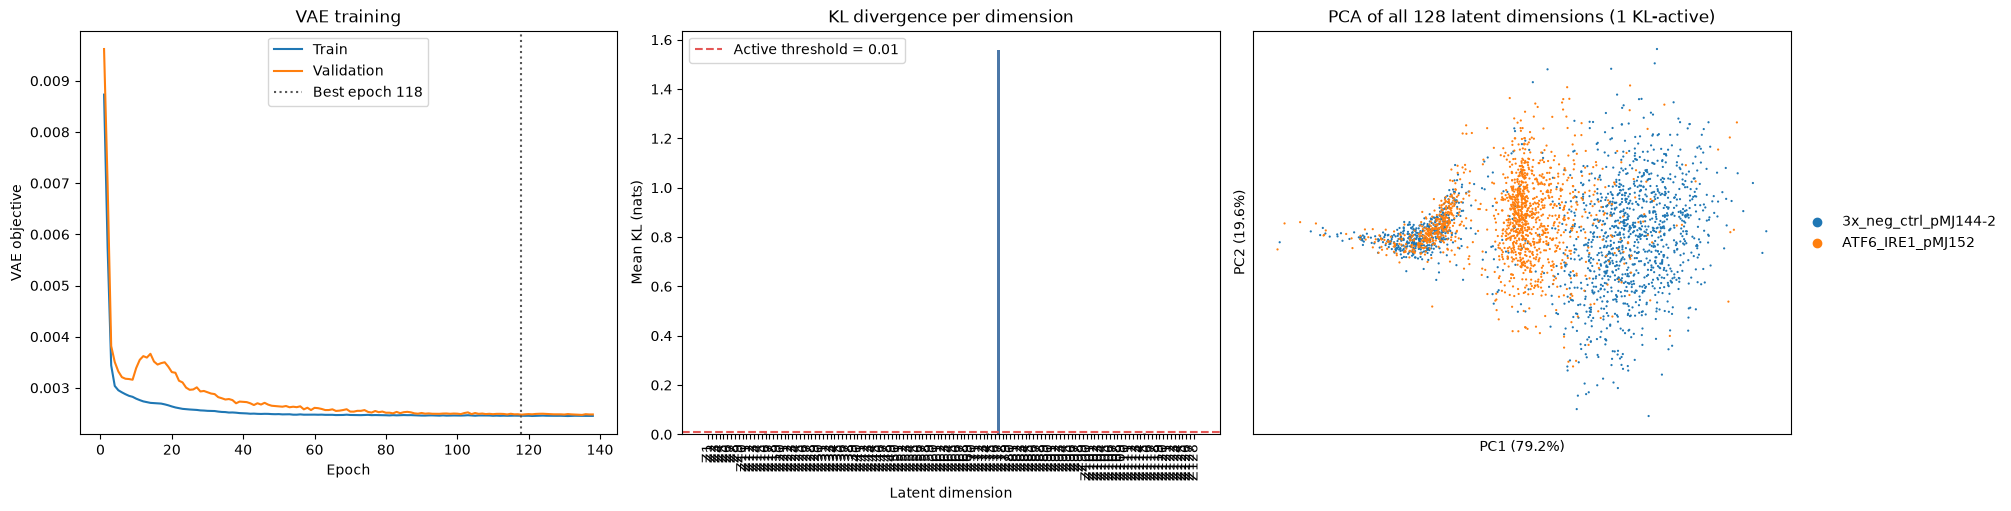

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
latent_dimension,Z1,Z2,Z3,Z4,Z5,Z6,Z7,Z8,Z9,Z10,...,Z119,Z120,Z121,Z122,Z123,Z124,Z125,Z126,Z127,Z128
KL_nats,0.000302,0.000551,0.000257,0.001546,0.002439,0.000562,0.002649,0.000467,0.001306,0.002229,...,0.000532,0.001311,0.001445,0.00081,0.001584,0.000245,0.001057,0.001337,0.000635,0.002976
std,0.023512,0.032549,0.021329,0.054978,0.068176,0.032346,0.072087,0.029694,0.050225,0.066498,...,0.031076,0.0503,0.052782,0.039394,0.055486,0.020702,0.045512,0.050603,0.034586,0.076318


Completed: 3,099 input cells -> 3,099 selected cells
3,000 total genes -> 128D Z space
Best epoch: 118; validation loss: 0.0025
Total KL: 1.6918 nats/cell
Active dimensions (KL > 0.01): 1/128
Active dimensions: ['Z77']
Inactive dimensions: 127/128
PCA input: all 128 posterior-mean dimensions; active count is diagnostic only
PCA cumulative explained variance: 98.8%


Epoch  60: validation=0.0026, KL=0.0125


Epoch  80: validation=0.0025, KL=0.0129


Epoch 100: validation=0.0025, KL=0.0132


Epoch 120: validation=0.0025, KL=0.0134


Early stopping at epoch 138


,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
latent_dimension,Z1,Z2,Z3,Z4,Z5,Z6,Z7,Z8,Z9,Z10,...,Z119,Z120,Z121,Z122,Z123,Z124,Z125,Z126,Z127,Z128
KL_nats,0.000302,0.000551,0.000257,0.001546,0.002439,0.000562,0.002649,0.000467,0.001306,0.002229,...,0.000532,0.001311,0.001445,0.00081,0.001584,0.000245,0.001057,0.001337,0.000635,0.002976
std,0.023512,0.032549,0.021329,0.054978,0.068176,0.032346,0.072087,0.029694,0.050225,0.066498,...,0.031076,0.0503,0.052782,0.039394,0.055486,0.020702,0.045512,0.050603,0.034586,0.076318


Completed: 3,099 input cells -> 3,099 selected cells
3,000 total genes -> 128D Z space
Best epoch: 118; validation loss: 0.0025
Total KL: 1.6918 nats/cell
Active dimensions (KL > 0.01): 1/128
Active dimensions: ['Z77']
Inactive dimensions: 127/128
PCA input: all 128 posterior-mean dimensions; active count is diagnostic only
PCA cumulative explained variance: 98.8%


In [4]:
class ExpressionVAE(nn.Module):
    def __init__(self, n_genes: int, latent_dim: int):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_genes, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU())
        self.mu = nn.Linear(128, latent_dim)
        self.logvar = nn.Linear(128, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 128), nn.ReLU(),
                                     nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, n_genes))

    def encode(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        hidden = self.encoder(x)
        return self.mu(hidden), self.logvar(hidden).clamp(-10, 10)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar) if self.training else mu
        return self.decoder(z), mu, logvar


def vae_loss(x, reconstruction, mu, logvar, beta):
    reconstruction_loss = (reconstruction - x).square().mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).mean()
    return reconstruction_loss + beta * kl, reconstruction_loss, kl


vae = ExpressionVAE(X.shape[1], LATENT_DIM).to(DEVICE)
optimizer = torch.optim.Adam(vae.parameters(), lr=LEARNING_RATE)
history, best_val, stale, best_weights, best_epoch = [], float('inf'), 0, None, None

for epoch in range(1, EPOCHS + 1):
    vae.train()
    training_sum = training_reconstruction = training_kl = 0.0
    epoch_beta = BETA * min(1.0, epoch / KL_WARMUP_EPOCHS)

    for (batch,) in train_loader:
        batch = batch.to(DEVICE)
        loss, batch_reconstruction, batch_kl = vae_loss(batch, *vae(batch), epoch_beta)

        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite VAE training loss.')

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(vae.parameters(), 5.0)
        optimizer.step()

        training_sum += loss.item() * len(batch)
        training_reconstruction += batch_reconstruction.item() * len(batch)
        training_kl += batch_kl.item() * len(batch)

    vae.eval()

    with torch.no_grad():
        validation, reconstruction_loss, kl = vae_loss(val_tensor, *vae(val_tensor), BETA)

    if not torch.isfinite(validation):
        raise FloatingPointError('Non-finite VAE validation loss.')

    history.append({
        'epoch': epoch,
        'beta': epoch_beta,
        'train_loss': training_sum / len(train_ids),
        'train_reconstruction': training_reconstruction / len(train_ids),
        'train_kl': training_kl / len(train_ids),
        'val_loss': validation.item(),
        'val_reconstruction': reconstruction_loss.item(),
        'val_kl': kl.item()
    })

    if validation.item() < best_val - 1e-5:
        best_val, stale, best_weights, best_epoch = validation.item(), 0, deepcopy(vae.state_dict()), epoch
    else:
        stale += 1

    if epoch == 1 or epoch % 20 == 0:
        print(f'Epoch {epoch:3d}: validation={validation.item():.4f}, KL={kl.item():.4f}')

    if epoch >= KL_WARMUP_EPOCHS and stale >= PATIENCE:
        print(f'Early stopping at epoch {epoch}')
        break

if best_weights is None:
    raise RuntimeError('No valid VAE checkpoint was produced.')

vae.load_state_dict(best_weights)
vae.eval()

with torch.no_grad():
    Z_space = np.concatenate([
        vae.encode(torch.from_numpy(X[start:start + BATCH_SIZE]).to(DEVICE))[0].cpu().numpy()
        for start in range(0, len(X), BATCH_SIZE)
    ])

if Z_space.shape != (adata.n_obs, LATENT_DIM) or not np.isfinite(Z_space).all():
    raise ValueError('Unexpected Z space shape or non-finite latent coordinates.')

adata.obsm['X_z'] = Z_space
training_history = pd.DataFrame(history)

with torch.no_grad():
    kl_per_dimension = np.concatenate([
        (-0.5 * (1 + logvar - mu.square() - logvar.exp())).cpu().numpy()
        for mu, logvar in [
            vae.encode(torch.from_numpy(X[start:start + BATCH_SIZE]).to(DEVICE))
            for start in range(0, len(X), BATCH_SIZE)
        ]
    ]).mean(axis=0)

if not np.isfinite(kl_per_dimension).all() or np.any(kl_per_dimension < -1e-6):
    raise ValueError('KL divergence per latent dimension must be finite and non-negative.')

kl_table = pd.DataFrame({
    'latent_dimension': [f'Z{i + 1}' for i in range(LATENT_DIM)],
    'KL_nats': kl_per_dimension,
    'std': Z_space.std(axis=0)
})

kl_threshold = 0.01
active_mask = kl_per_dimension > kl_threshold
active_dimensions = int(active_mask.sum())
inactive_dimensions = LATENT_DIM - active_dimensions

if active_dimensions < 2:
    print(f'Warning: only {active_dimensions} KL-active dimension(s); PCA uses all {LATENT_DIM} posterior-mean dimensions, as does DQN.')

Z_active = Z_space
active_names = kl_table.loc[active_mask, 'latent_dimension'].tolist()

pca = PCA(n_components=2, random_state=SEED)
Z_pca = pca.fit_transform(Z_active)
adata.obsm['X_z_pca'] = Z_pca

fig, axes = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)

axes[0].plot(training_history['epoch'], training_history['train_loss'], label='Train')
axes[0].plot(training_history['epoch'], training_history['val_loss'], label='Validation')
axes[0].axvline(best_epoch, c='#555555', ls=':', label=f'Best epoch {best_epoch}')
axes[0].set(xlabel='Epoch', ylabel='VAE objective', title='VAE training')
axes[0].legend()

axes[1].bar(kl_table['latent_dimension'], kl_table['KL_nats'], color=[
    '#4C78A8' if active else '#BAB0AC' for active in active_mask
])
axes[1].axhline(kl_threshold, c='#E45756', ls='--', label=f'Active threshold = {kl_threshold}')
axes[1].set(xlabel='Latent dimension', ylabel='Mean KL (nats)', title='KL divergence per dimension')
axes[1].tick_params(axis='x', rotation=90)
axes[1].legend()

sc.pl.embedding(
    adata,
    basis='z_pca',
    color='perturbation',
    size=10,
    title=f'PCA of all {LATENT_DIM} latent dimensions ({active_dimensions} KL-active)',
    ax=axes[2],
    show=False
)
axes[2].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[2].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')

plt.show()
display(kl_table.T)

assert set(adata.obs['perturbation'].astype(str)) == set(CONDITIONS)
assert X.shape == (adata.n_obs, adata.n_vars)
assert adata.obsm['X_z'].shape == (adata.n_obs, LATENT_DIM)
assert Z_pca.shape == (adata.n_obs, 2) and np.isfinite(Z_pca).all()
np.testing.assert_allclose(pca.transform(Z_active), Z_pca, rtol=1e-4, atol=1e-4)

print(f'Completed: {input_n_cells:,} input cells -> {adata.n_obs:,} selected cells')
print(f'{adata.n_vars:,} total genes -> {LATENT_DIM}D Z space')
print(f'Best epoch: {best_epoch}; validation loss: {best_val:.4f}')
print(f'Total KL: {kl_per_dimension.sum():.4f} nats/cell')
print(f'Active dimensions (KL > {kl_threshold}): {active_dimensions}/{LATENT_DIM}')
print(f'Active dimensions: {active_names}')
print(f'Inactive dimensions: {inactive_dimensions}/{LATENT_DIM}')
print(f'PCA input: all {Z_active.shape[1]} posterior-mean dimensions; active count is diagnostic only')
print(f'PCA cumulative explained variance: {pca.explained_variance_ratio_.sum():.1%}')

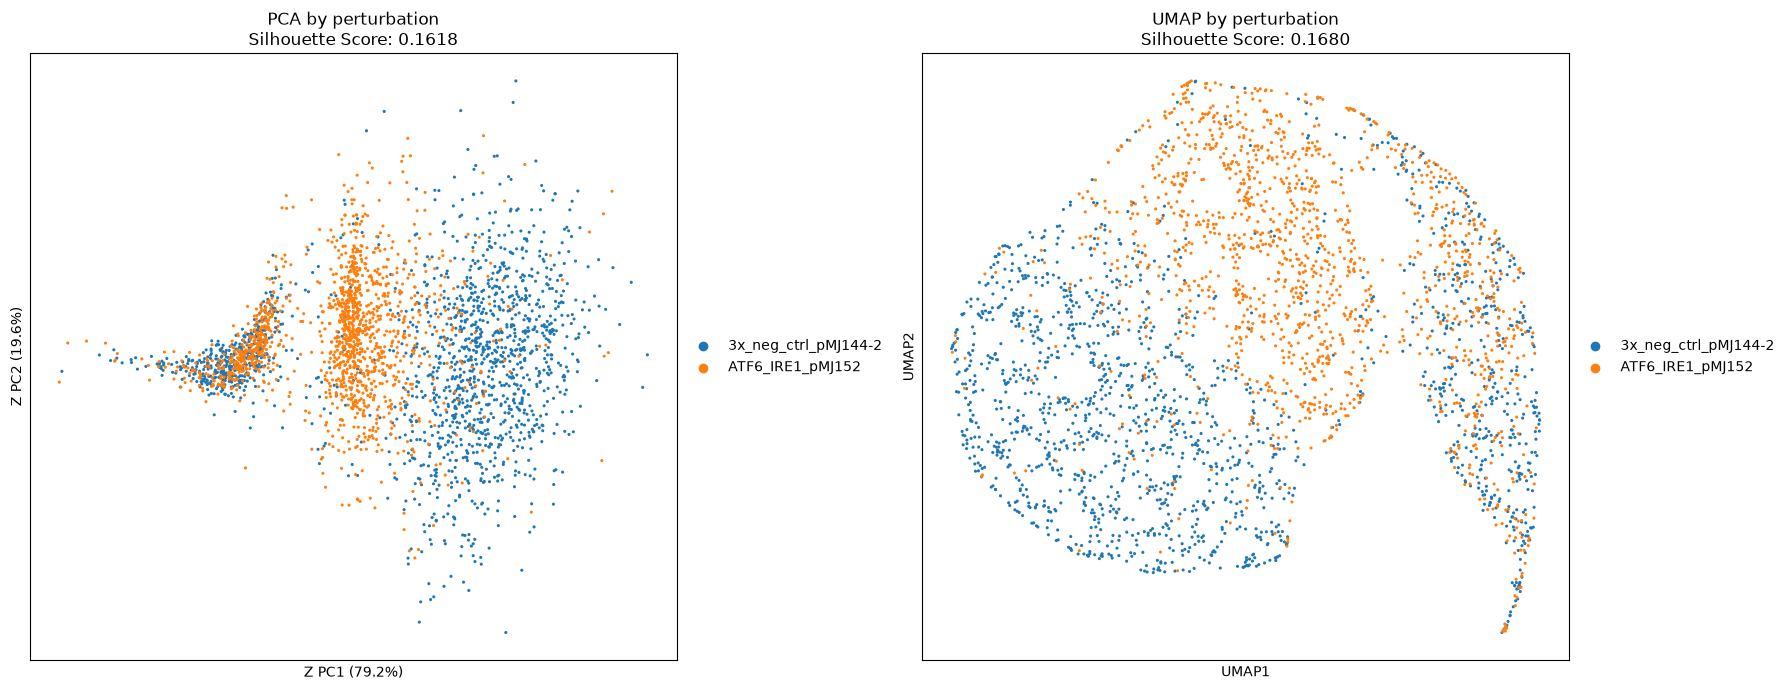

Completed: 3,099 input cells -> 3,099 selected cells
3,000 total genes -> 128D Z space -> 2D PCA and UMAP
PCA cumulative explained variance: 98.8%
PCA silhouette score: 0.1618
UMAP silhouette score: 0.1680
All subsequent trajectories use this fixed UMAP; DQN dynamics remain in latent space.


In [6]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

pca = PCA(n_components=2, random_state=SEED)
Z_pca = pca.fit_transform(Z_space)
adata.obsm['X_z_pca'] = Z_pca

sc.pp.neighbors(adata, use_rep='X_z', n_neighbors=15, random_state=SEED)
from umap import UMAP
import joblib

umap_model = UMAP(
    n_components=2, n_neighbors=15, min_dist=0.5, spread=1.0,
    metric='euclidean', random_state=SEED, transform_seed=SEED, n_jobs=1,
)
Z_umap = umap_model.fit_transform(Z_space).astype(np.float32)
adata.obsm['X_umap'] = Z_umap
adata.uns['umap'] = {'params': {'a': umap_model._a, 'b': umap_model._b}}
UMAP_MODEL_PATH = RESULT_ROOT / 'fixed_umap.joblib'
joblib.dump(umap_model, UMAP_MODEL_PATH)
umap_projection_cache = {
    row.tobytes(): xy.copy()
    for row, xy in zip(np.asarray(Z_space, dtype=np.float32), Z_umap)
}


def project_umap(latent):
    values = np.asarray(latent, dtype=np.float32)
    if values.ndim != 2 or values.shape[1] != LATENT_DIM or not len(values) or not np.isfinite(values).all():
        raise ValueError('UMAP projection requires nonempty finite latent coordinates with LATENT_DIM columns.')
    keys = [row.tobytes() for row in values]
    missing = {key: row for key, row in zip(keys, values) if key not in umap_projection_cache}
    if missing:
        missing_keys = sorted(missing)
        coordinates = umap_model.transform(np.stack([missing[key] for key in missing_keys]))
        if coordinates.shape != (len(missing_keys), 2) or not np.isfinite(coordinates).all():
            raise FloatingPointError('Fixed UMAP produced invalid projected coordinates.')
        umap_projection_cache.update({key: xy.copy() for key, xy in zip(missing_keys, coordinates)})
    return np.stack([umap_projection_cache[key] for key in keys])


np.testing.assert_array_equal(project_umap(Z_space), Z_umap)

y = adata.obs['perturbation'].astype(str).to_numpy()
Z_umap = adata.obsm['X_umap']

silhouette_pca = silhouette_score(Z_pca, y)
silhouette_umap = silhouette_score(Z_umap, y)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sc.pl.embedding(
    adata,
    basis='z_pca',
    color='perturbation',
    size=20,
    title=f'PCA by perturbation\nSilhouette Score: {silhouette_pca:.4f}',
    ax=axes[0],
    show=False,
    legend_loc='right margin'
)

sc.pl.umap(
    adata,
    color='perturbation',
    size=20,
    title=f'UMAP by perturbation\nSilhouette Score: {silhouette_umap:.4f}',
    ax=axes[1],
    show=False,
    legend_loc='right margin'
)

axes[0].set_xlabel(f'Z PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'Z PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[1].set_xlabel('UMAP1')
axes[1].set_ylabel('UMAP2')

plt.tight_layout()
plt.show()

assert set(adata.obs['perturbation'].astype(str)) == set(CONDITIONS)
assert X.shape == (adata.n_obs, adata.n_vars)
assert adata.obsm['X_z'].shape == (adata.n_obs, LATENT_DIM)
assert Z_pca.shape == (adata.n_obs, 2) and np.isfinite(Z_pca).all()
assert Z_umap.shape == (adata.n_obs, 2) and np.isfinite(Z_umap).all()
np.testing.assert_allclose(pca.transform(Z_space), Z_pca, rtol=1e-4, atol=1e-4)

print(f'Completed: {input_n_cells:,} input cells -> {adata.n_obs:,} selected cells')
print(f'{adata.n_vars:,} total genes -> {LATENT_DIM}D Z space -> 2D PCA and UMAP')
print(f'PCA cumulative explained variance: {pca.explained_variance_ratio_.sum():.1%}')
print(f'PCA silhouette score: {silhouette_pca:.4f}')
print(f'UMAP silhouette score: {silhouette_umap:.4f}')
fig.savefig(RESULT_ROOT / 'deg2000_pca_umap.png', dpi=180, bbox_inches='tight')
training_history.to_csv(RESULT_ROOT / 'vae_training.csv', index=False)
adata.write_h5ad(RESULT_ROOT / 'deg2000_latent.h5ad')
print('All subsequent trajectories use this fixed UMAP; DQN dynamics remain in latent space.')

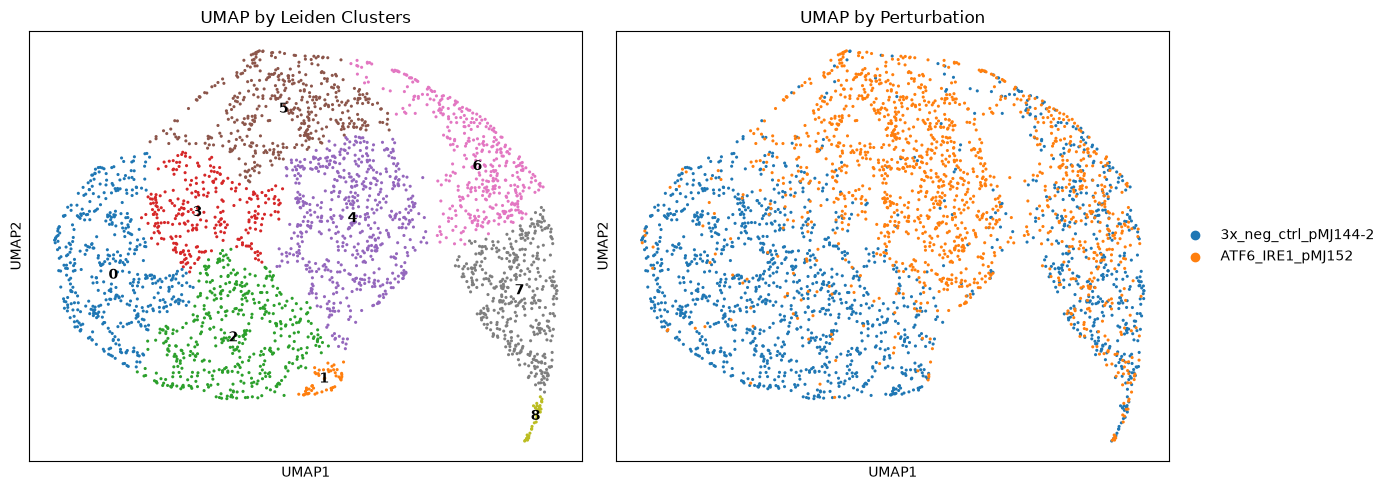

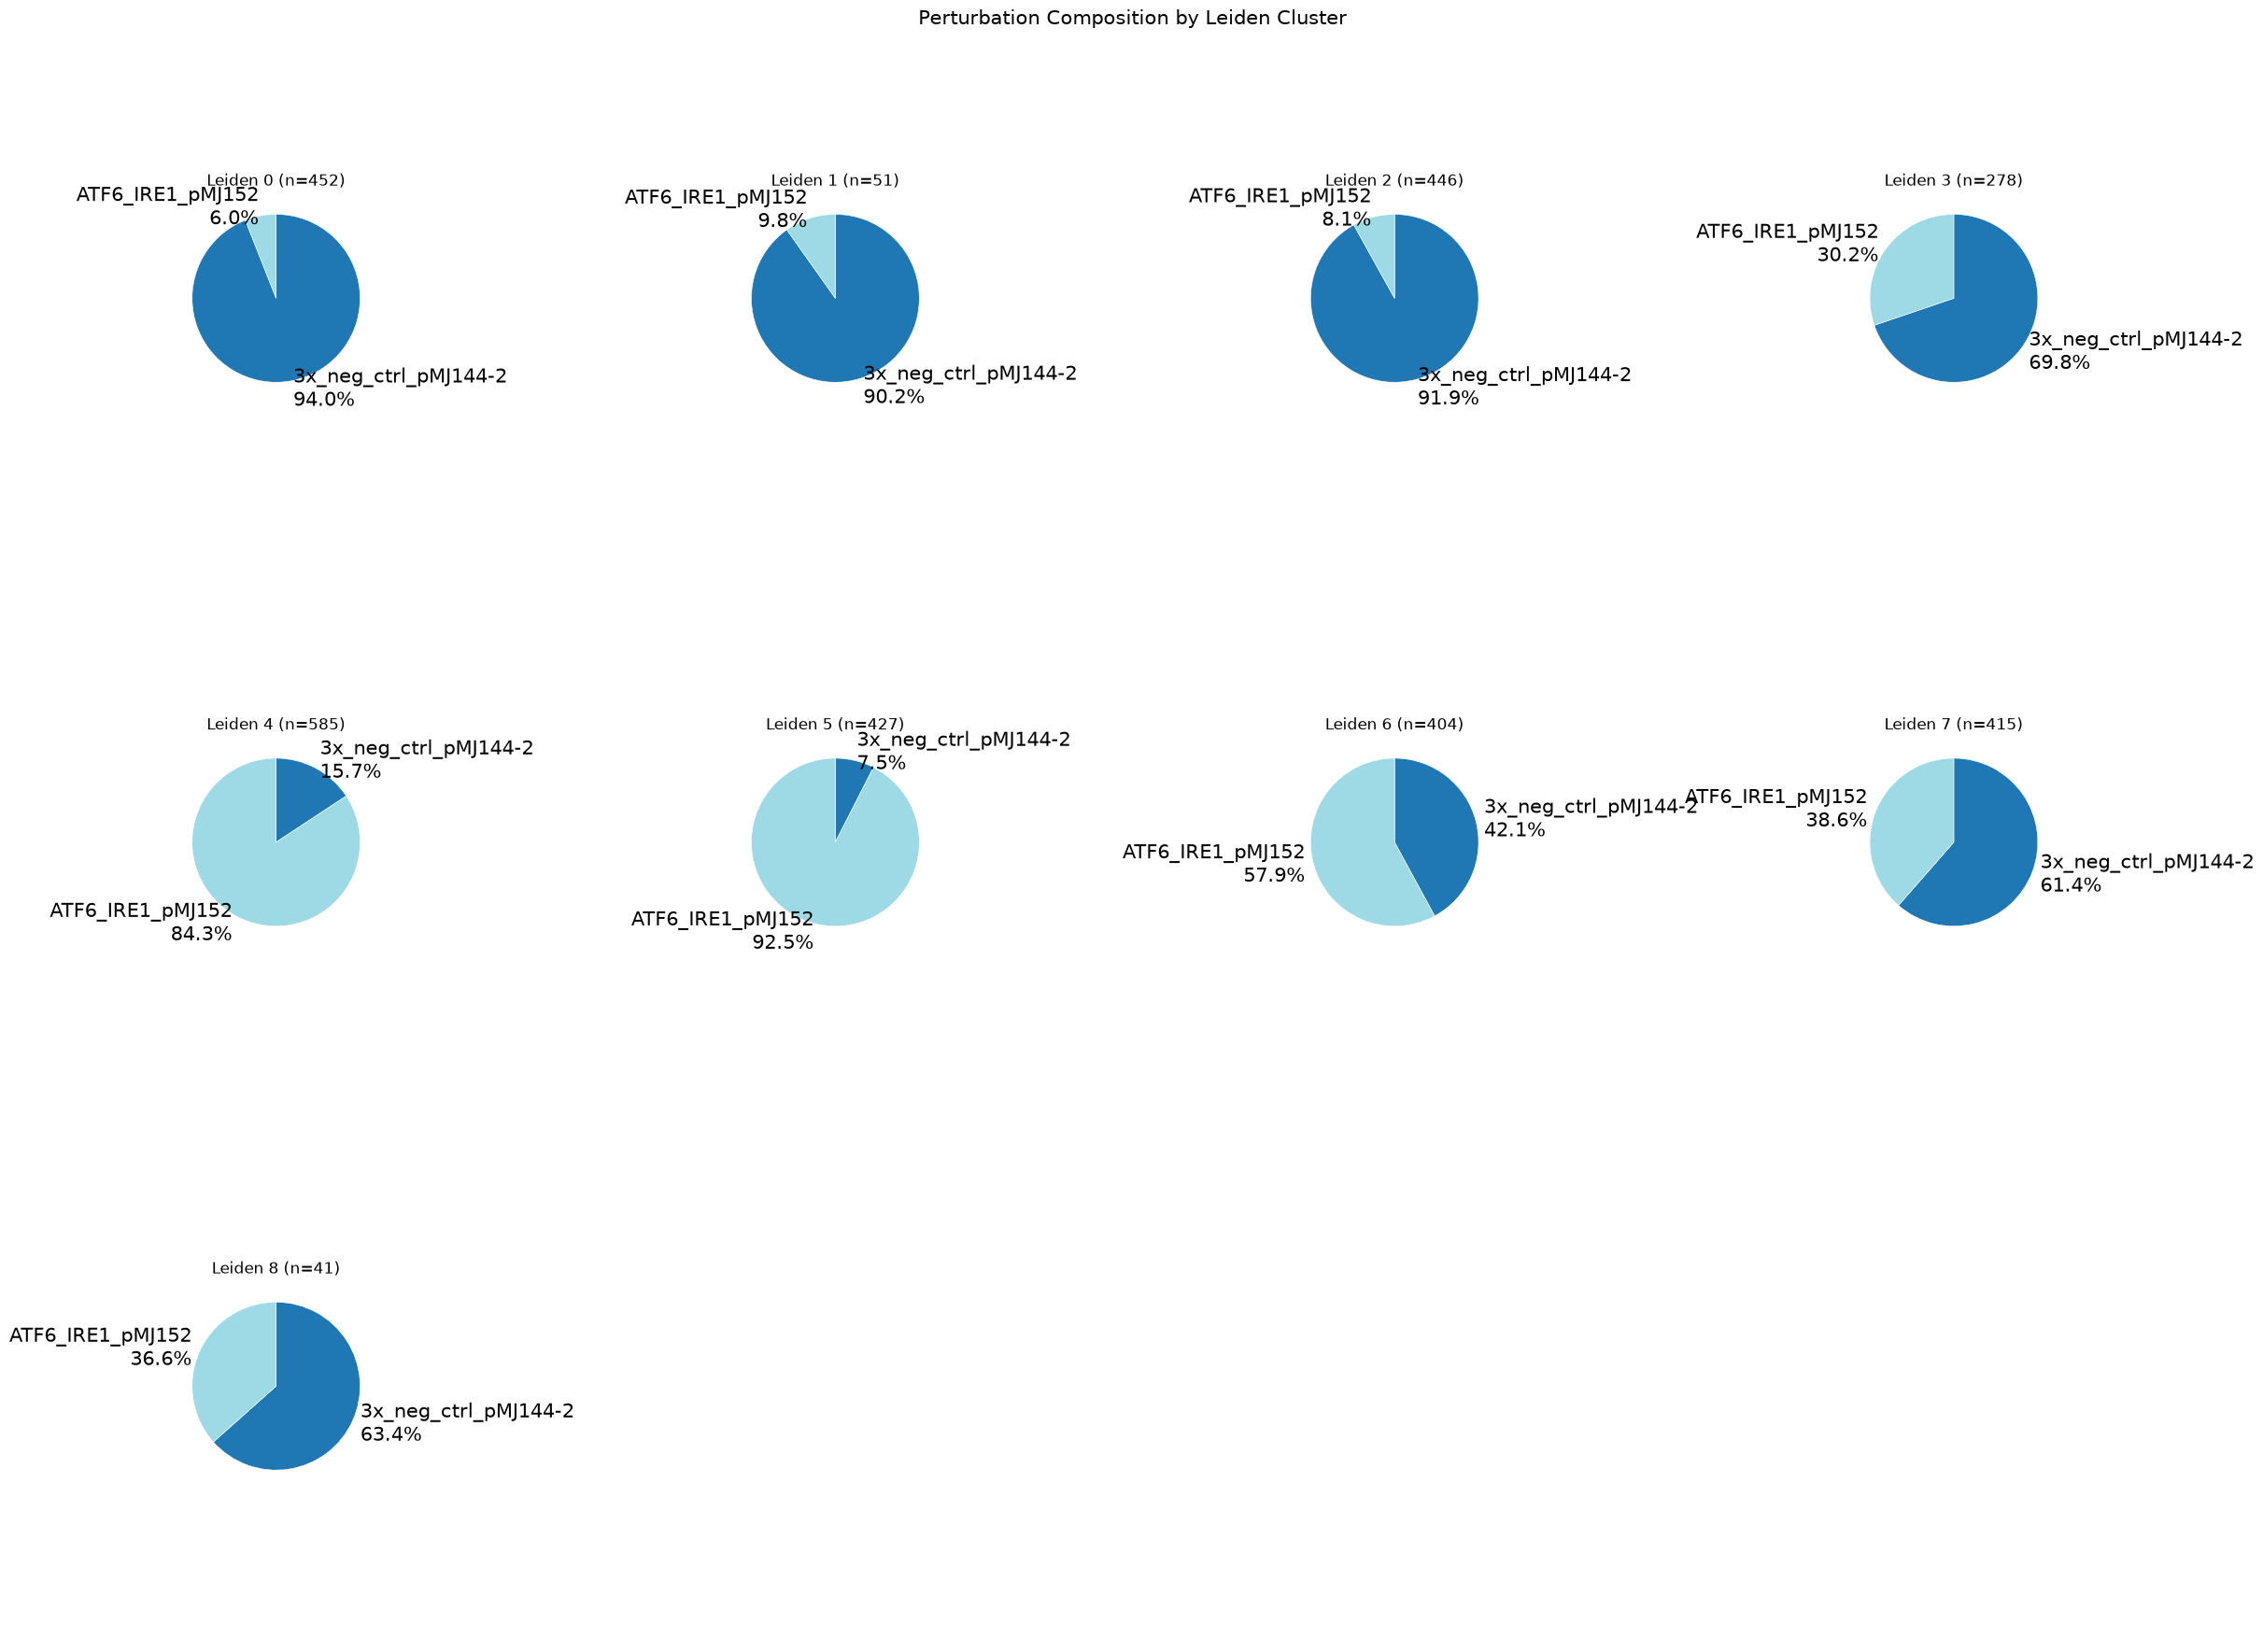

In [7]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

sc.pp.neighbors(
    adata,
    use_rep='X_z',
    n_neighbors=15,
    random_state=SEED
)

sc.tl.leiden(
    adata,
    resolution=0.2,
    key_added='leiden',
    random_state=SEED,
    flavor='igraph',
    n_iterations=2
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc.pl.umap(
    adata,
    color='leiden',
    size=20,
    title='UMAP by Leiden Clusters',
    legend_loc='on data',
    ax=axes[0],
    show=False
)

sc.pl.umap(
    adata,
    color='perturbation',
    size=20,
    title='UMAP by Perturbation',
    ax=axes[1],
    show=False
)

plt.tight_layout()
plt.show()

composition = pd.crosstab(
    adata.obs['leiden'].astype(str),
    adata.obs['perturbation'].astype(str)
)

composition = composition.reindex(
    sorted(composition.index, key=int)
)

n_clusters = len(composition)
n_cols = min(4, n_clusters)
n_rows = math.ceil(n_clusters / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(6 * n_cols, 6 * n_rows),
    squeeze=False
)

axes = axes.flatten()
colors = plt.cm.tab20(np.linspace(0, 1, composition.shape[1]))

for i, cluster in enumerate(composition.index):
    counts = composition.loc[cluster]
    counts = counts[counts > 0]

    axes[i].pie(
        counts,
        labels=[
            f'{group}\n{value / counts.sum() * 100:.1f}%'
            for group, value in counts.items()
        ],
        colors=colors[
            [composition.columns.get_loc(g) for g in counts.index]
        ],
        startangle=90,
        counterclock=False,
        textprops={'fontsize': 15},
        wedgeprops={'edgecolor': 'white', 'linewidth': 0.4}
    )

    axes[i].set_title(f'Leiden {cluster} (n={counts.sum():,})')

for i in range(n_clusters, len(axes)):
    axes[i].axis('off')

fig.suptitle(
    'Perturbation Composition by Leiden Cluster',
    fontsize=15
)

plt.tight_layout()
plt.show()

In [8]:
exclude_leiden = ['6', '7','8']

keep_cells = ~adata.obs['leiden'].astype(str).isin(exclude_leiden)
filtered_adata = adata[keep_cells].copy()
filtered_counts = filtered_adata.obs['perturbation'].astype(str).value_counts()
if any(filtered_counts.get(label, 0) < 2 for label in CONDITIONS):
    raise ValueError('Leiden exclusion must retain at least two cells per perturbation.')
if filtered_adata.n_obs <= 5:
    raise ValueError('Leiden exclusion must retain more than five cells for DQN support neighbors.')

adata = filtered_adata
# AnnData subsets obsm by barcode; independent NumPy arrays must be refreshed too.
X = (adata.X.toarray() if sparse.issparse(adata.X) else np.asarray(adata.X)).astype(np.float32)
Z_space = np.asarray(adata.obsm['X_z'], dtype=np.float32)
Z_active = Z_space
Z_pca = np.asarray(adata.obsm['X_z_pca'], dtype=np.float32)
Z_umap = np.asarray(adata.obsm['X_umap'], dtype=np.float32)
y = adata.obs['perturbation'].astype(str).to_numpy()
np.testing.assert_array_equal(project_umap(Z_space), Z_umap)
adata.write_h5ad(RESULT_ROOT / 'deg2000_latent.h5ad')
print(f'After Leiden exclusion {exclude_leiden}: {adata.n_obs:,} cells; latent/PCA/UMAP rows synchronized.')
display(filtered_counts.rename('cells').to_frame())

After Leiden exclusion ['6', '7', '8']: 2,239 cells; latent/PCA/UMAP rows synchronized.


,cells
perturbation,
3x_neg_ctrl_pMJ144-2,1199
ATF6_IRE1_pMJ152,1040


## 4. 공통 Z space → 고정 UMAP 2차원 + perturbation 색상

128D posterior mean에 UMAP을 한 번 fit하고 모델을 저장합니다. PCA는 왼쪽 진단 그림에만 유지합니다.
이후 DQN 경로·분기·세포별 반응 벡터·영상은 모두 이 모델의 transform 좌표를 사용합니다.
같은 latent 좌표는 최초 projection을 재사용해 그림·CSV·영상 사이의 batch별 UMAP transform 차이를 방지합니다.
UMAP은 비선형 시각화이며 경로의 길이·속도·거리·교차는 실제 동역학이나 생물학적 시간을 뜻하지 않습니다.


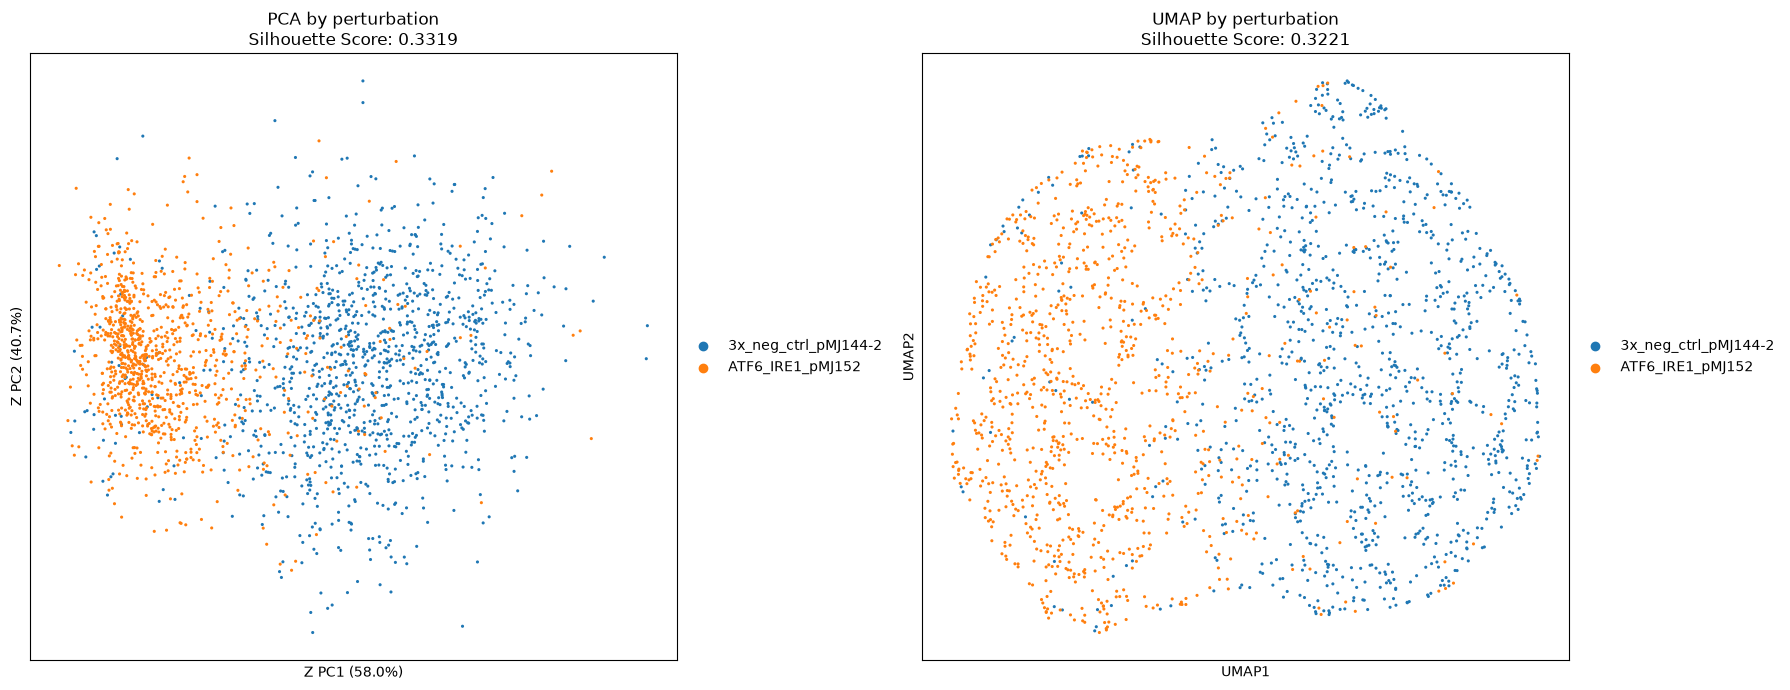

Completed: 3,099 input cells -> 2,239 selected cells
3,000 total genes -> 128D Z space -> 2D PCA and UMAP
PCA cumulative explained variance: 98.6%
PCA silhouette score: 0.3319
UMAP silhouette score: 0.3221
All subsequent trajectories use this fixed UMAP; DQN dynamics remain in latent space.


All subsequent trajectories use this fixed UMAP; DQN dynamics remain in latent space.


In [9]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

pca = PCA(n_components=2, random_state=SEED)
Z_pca = pca.fit_transform(Z_space)
adata.obsm['X_z_pca'] = Z_pca

sc.pp.neighbors(adata, use_rep='X_z', n_neighbors=15, random_state=SEED)
from umap import UMAP
import joblib

umap_model = UMAP(
    n_components=2, n_neighbors=15, min_dist=0.5, spread=1.0,
    metric='euclidean', random_state=SEED, transform_seed=SEED, n_jobs=1,
)
Z_umap = umap_model.fit_transform(Z_space).astype(np.float32)
adata.obsm['X_umap'] = Z_umap
adata.uns['umap'] = {'params': {'a': umap_model._a, 'b': umap_model._b}}
UMAP_MODEL_PATH = RESULT_ROOT / 'fixed_umap.joblib'
joblib.dump(umap_model, UMAP_MODEL_PATH)
umap_projection_cache = {
    row.tobytes(): xy.copy()
    for row, xy in zip(np.asarray(Z_space, dtype=np.float32), Z_umap)
}


def project_umap(latent):
    values = np.asarray(latent, dtype=np.float32)
    if values.ndim != 2 or values.shape[1] != LATENT_DIM or not len(values) or not np.isfinite(values).all():
        raise ValueError('UMAP projection requires nonempty finite latent coordinates with LATENT_DIM columns.')
    keys = [row.tobytes() for row in values]
    missing = {key: row for key, row in zip(keys, values) if key not in umap_projection_cache}
    if missing:
        missing_keys = sorted(missing)
        coordinates = umap_model.transform(np.stack([missing[key] for key in missing_keys]))
        if coordinates.shape != (len(missing_keys), 2) or not np.isfinite(coordinates).all():
            raise FloatingPointError('Fixed UMAP produced invalid projected coordinates.')
        umap_projection_cache.update({key: xy.copy() for key, xy in zip(missing_keys, coordinates)})
    return np.stack([umap_projection_cache[key] for key in keys])


np.testing.assert_array_equal(project_umap(Z_space), Z_umap)

y = adata.obs['perturbation'].astype(str).to_numpy()
Z_umap = adata.obsm['X_umap']

silhouette_pca = silhouette_score(Z_pca, y)
silhouette_umap = silhouette_score(Z_umap, y)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sc.pl.embedding(
    adata,
    basis='z_pca',
    color='perturbation',
    size=20,
    title=f'PCA by perturbation\nSilhouette Score: {silhouette_pca:.4f}',
    ax=axes[0],
    show=False,
    legend_loc='right margin'
)

sc.pl.umap(
    adata,
    color='perturbation',
    size=20,
    title=f'UMAP by perturbation\nSilhouette Score: {silhouette_umap:.4f}',
    ax=axes[1],
    show=False,
    legend_loc='right margin'
)

axes[0].set_xlabel(f'Z PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'Z PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[1].set_xlabel('UMAP1')
axes[1].set_ylabel('UMAP2')

plt.tight_layout()
plt.show()

assert set(adata.obs['perturbation'].astype(str)) == set(CONDITIONS)
assert X.shape == (adata.n_obs, adata.n_vars)
assert adata.obsm['X_z'].shape == (adata.n_obs, LATENT_DIM)
assert Z_pca.shape == (adata.n_obs, 2) and np.isfinite(Z_pca).all()
assert Z_umap.shape == (adata.n_obs, 2) and np.isfinite(Z_umap).all()
np.testing.assert_allclose(pca.transform(Z_space), Z_pca, rtol=1e-4, atol=1e-4)

print(f'Completed: {input_n_cells:,} input cells -> {adata.n_obs:,} selected cells')
print(f'{adata.n_vars:,} total genes -> {LATENT_DIM}D Z space -> 2D PCA and UMAP')
print(f'PCA cumulative explained variance: {pca.explained_variance_ratio_.sum():.1%}')
print(f'PCA silhouette score: {silhouette_pca:.4f}')
print(f'UMAP silhouette score: {silhouette_umap:.4f}')
fig.savefig(RESULT_ROOT / 'deg2000_pca_umap.png', dpi=180, bbox_inches='tight')
training_history.to_csv(RESULT_ROOT / 'vae_training.csv', index=False)
adata.write_h5ad(RESULT_ROOT / 'deg2000_latent.h5ad')
print('All subsequent trajectories use this fixed UMAP; DQN dynamics remain in latent space.')

## 5. 가상 128D latent DQN → 4번의 고정 UMAP에 표시

상태·행동·목표 거리·decoder entropy·지원영역은 128D latent에서 계산합니다.
기존 시작/목표는 조건별 PCA median을 inverse PCA한 latent 좌표로 유지하며, UMAP에서 임의로 이동하지 않습니다.
경로의 각 latent 좌표와 시작/목표를 4번의 고정 UMAP에 transform해 표시합니다.
목표 접근 + feasible NEXT 후보 중 상대적으로 낮은 entropy 보상을 유지합니다.
첫 목표 도착, 거리 수렴 또는 최대 500회 이동에서 종료합니다.

`exclude_leiden` 셀은 남은 세포의 발현·latent·PCA·UMAP 배열과 저장된 AnnData를 함께 갱신합니다. VAE와 고정 PCA/UMAP 모델은 재학습하지 않습니다.
제외 목록을 바꾼 뒤에는 제외 셀 → 5번의 환경·Q 구성·DQN 학습 셀 → 6번 순서로 다시 실행하세요. 이미 제외한 클러스터를 복원하려면 1번부터 데이터를 다시 준비해야 합니다.


In [10]:
from scipy.special import logsumexp
from sklearn.neighbors import NearestNeighbors
import json
import time

REGION_SIZE = 5
RL_MIN_MOVES, RL_MAX_STEPS = 1, 500
RL_PROGRESS_WEIGHT, RL_STEP_COST, RL_GOAL_BONUS = 1.0, 0.03, 1.0
RL_ENTROPY_WEIGHT, RL_REWARD_SCALE, RL_GAMMA = 1.0, 0.1, 0.99
RL_SUPPORT_QUANTILE = 0.95
RL_N_ENVS, RL_VECTOR_STEPS, RL_UPDATES_PER_STEP = 256, 3000, 2
RL_BATCH_SIZE, RL_REPLAY_SIZE, RL_LR, RL_TARGET_SYNC = 1024, 400000, 3e-4, 500
RL_EVAL_EVERY = 250
RL_DISTANCE_PATIENCE = 20
RL_REWARD_VERSION = 'candidate_relative_entropy_distance_convergence_v7'
RL_RESULT_DIR = RESULT_ROOT / 'coordinate_dqn'
RL_RESULT_DIR.mkdir(parents=True, exist_ok=True)
rl_rng = np.random.default_rng(SEED + 100)
torch.manual_seed(SEED + 100)

cell_conditions = adata.obs['perturbation'].astype(str).to_numpy()
control_ids = np.flatnonzero(cell_conditions == '3x_neg_ctrl_pMJ144-2')
atf6_ids = np.flatnonzero(cell_conditions == 'ATF6_IRE1_pMJ152')
pca_median_xy = np.stack([np.median(Z_pca[control_ids], axis=0), np.median(Z_pca[atf6_ids], axis=0)])
z_start, z_goal = pca.inverse_transform(pca_median_xy).astype(np.float32)
np.testing.assert_allclose(pca.transform(np.stack([z_start, z_goal])), pca_median_xy, atol=1e-5)
start_barcode, end_barcode = 'virtual_control_PCA_median', 'virtual_ATF6_condition_PCA_median'
rl_total_distance = float(np.linalg.norm(z_goal - z_start))
if not np.isfinite(rl_total_distance) or rl_total_distance <= 1e-6:
    raise ValueError('Condition medians must define distinct finite latent endpoints.')
RL_STEP_LENGTH = 2 * rl_total_distance / RL_MAX_STEPS
RL_DISTANCE_MIN_DELTA = 0.1 * RL_STEP_LENGTH

rl_decoder = vae.decoder.eval()
Z_tensor = torch.tensor(Z_space, dtype=torch.float32, device=DEVICE)
z_start_t = torch.tensor(z_start, device=DEVICE)
z_goal_t = torch.tensor(z_goal, device=DEVICE)


@torch.no_grad()
def decoded_entropy_t(z: torch.Tensor) -> torch.Tensor:
    parts = []
    for chunk in z.split(4096):
        linear = torch.expm1(rl_decoder(chunk).double().clamp_min(0))
        totals = linear.sum(dim=1, keepdim=True)
        if not torch.isfinite(linear).all() or (totals <= 0).any():
            raise FloatingPointError('Decoder entropy requires finite, nonzero decoded CP10K expression.')
        p = linear / totals
        parts.append(-torch.xlogy(p, p).sum(dim=1).float())
    return torch.cat(parts)


@torch.no_grad()
def support_distance_t(z: torch.Tensor) -> torch.Tensor:
    return torch.cat([torch.cdist(chunk, Z_tensor).topk(REGION_SIZE, largest=False).values[:, -1]
                      for chunk in z.reshape(-1, LATENT_DIM).split(4096)])


observed_decoded_entropy = torch.cat([decoded_entropy_t(Z_tensor[start:start + 1024])
                                      for start in range(0, len(Z_tensor), 1024)]).cpu().numpy()
rl_entropy_scale = float(observed_decoded_entropy.std(ddof=1))
rl_entropy_floor = float(observed_decoded_entropy.min())
with torch.no_grad():
    observed_fifth = torch.cdist(Z_tensor, Z_tensor).topk(REGION_SIZE + 1, largest=False).values[:, -1]
rl_support_radius = float(torch.quantile(observed_fifth, RL_SUPPORT_QUANTILE))
h_start = float(decoded_entropy_t(z_start_t[None])[0])
h_goal = float(decoded_entropy_t(z_goal_t[None])[0])
z_feature_mean = torch.tensor(Z_space.mean(axis=0), device=DEVICE)
z_feature_scale = torch.tensor(Z_space.std(axis=0), device=DEVICE).clamp_min(1e-6)
latent_axes = torch.eye(LATENT_DIM, device=DEVICE)
N_ACTIONS = 2 + 2 * LATENT_DIM
action_names = ['goal', 'away_from_goal'] + [f'{sign}Z{dimension + 1}'
    for sign in ('+', '-') for dimension in range(LATENT_DIM)]


@torch.no_grad()
def candidate_moves(z: torch.Tensor, t: torch.Tensor):
    delta = z_goal_t - z
    distance = delta.norm(dim=1, keepdim=True)
    direction_goal = delta / distance.clamp_min(1e-12)
    goal_length = distance.clamp_max(RL_STEP_LENGTH)
    axis_moves = RL_STEP_LENGTH * torch.cat([latent_axes, -latent_axes])[None].expand(len(z), -1, -1)
    moves = torch.cat([
        torch.where(distance <= RL_STEP_LENGTH, delta, direction_goal * goal_length)[:, None],
        (-direction_goal * RL_STEP_LENGTH)[:, None], axis_moves], dim=1)
    valid = torch.ones(len(z), N_ACTIONS, dtype=torch.bool, device=DEVICE)
    valid[:, :2] = distance > RL_STEP_LENGTH * 1e-4
    return moves, valid


@torch.no_grad()
def action_mask(z: torch.Tensor, t: torch.Tensor):
    moves, valid = candidate_moves(z, t)
    landing = z[:, None] + moves
    support = support_distance_t(landing).reshape(len(z), N_ACTIONS)
    supported = support <= rl_support_radius
    supported[:, 0] = True
    distance_next = (z_goal_t.double() - landing.double()).norm(dim=2)
    remaining = (RL_MAX_STEPS - t - 1)[:, None]
    tolerance = RL_STEP_LENGTH * 1e-4
    # Reserve float32 rounding room for each remaining move, not just the final move.
    reachable = distance_next <= remaining * RL_STEP_LENGTH * (1 - 1e-4) + tolerance
    distance = (z_goal_t - z).norm(dim=1)
    valid &= (remaining >= 0) & (distance > tolerance)[:, None]
    must_finish = (distance <= RL_STEP_LENGTH)[:, None] | (remaining == 0)
    valid &= ~must_finish | (torch.arange(N_ACTIONS, device=DEVICE)[None] == 0)
    return valid & supported & reachable, moves, support


@torch.no_grad()
def candidate_entropies(z, moves, mask):
    if not mask.any(dim=1).all():
        raise RuntimeError('No feasible latent candidate satisfying the required goal deadline.')
    landing = z[:, None] + moves
    snap_goal = (z_goal_t - landing).norm(dim=2) <= RL_STEP_LENGTH * 1e-4
    landing[snap_goal] = z_goal_t
    values = decoded_entropy_t(landing.reshape(-1, LATENT_DIM)).reshape(len(z), N_ACTIONS)
    return values, values.masked_fill(~mask, torch.inf).amin(dim=1), values.masked_fill(~mask, -torch.inf).amax(dim=1)


def relative_entropy_reward(h_next, h_min_candidate, h_max_candidate):
    span = h_max_candidate - h_min_candidate
    score = torch.where(span > 1e-7,
        (h_max_candidate - h_next) / span.clamp_min(1e-7), torch.ones_like(h_next))
    return RL_ENTROPY_WEIGHT * score.clamp(0, 1)


@torch.no_grad()
def state_features(z, h, h_min, t):
    distance = (z_goal_t - z).norm(dim=1, keepdim=True)
    slack = (RL_MAX_STEPS - t.float()[:, None] - distance / RL_STEP_LENGTH) / RL_MAX_STEPS
    return torch.cat([(z - z_feature_mean) / z_feature_scale, (z_goal_t - z) / rl_total_distance,
                      distance / rl_total_distance, ((h - h_start) / rl_entropy_scale)[:, None],
                      ((h_min - h_start) / rl_entropy_scale)[:, None], t.float()[:, None] / RL_MAX_STEPS, slack],
                     dim=1)


def transition_reward_components(distance, distance_next, h_next, h_min_candidate, h_max_candidate, reached):
    progress = RL_PROGRESS_WEIGHT * (distance - distance_next) / RL_STEP_LENGTH
    entropy = relative_entropy_reward(h_next, h_min_candidate, h_max_candidate)
    goal = RL_GOAL_BONUS * reached.float()
    return progress, entropy, goal


@torch.no_grad()
def distance_stop_state(distance_history, distance, t):
    rows = torch.arange(len(distance), device=distance.device)
    size = RL_DISTANCE_PATIENCE + 1
    previous_best = distance_history[(t - 1) % size, rows]
    window_best = distance_history[(t - RL_DISTANCE_PATIENCE) % size, rows].clone()
    best = torch.minimum(previous_best, distance)
    distance_history[t % size, rows] = best
    converged = (t >= RL_DISTANCE_PATIENCE) & (window_best - best <= RL_DISTANCE_MIN_DELTA)
    reached = distance <= RL_STEP_LENGTH * 1e-4
    return reached | converged | (t >= RL_MAX_STEPS)


def distance_stop_status(distance, step):
    if distance <= RL_STEP_LENGTH * 1e-4:
        return f'target_reached_at_step_{step}'
    if step >= RL_MAX_STEPS:
        return f'max_steps_at_step_{step}'
    return f'distance_converged_at_step_{step}'


@torch.no_grad()
def environment_step(z, h_min, t, actions, moves, distance_history):
    distance = (z_goal_t - z).norm(dim=1)
    mask, expected_moves, _ = action_mask(z, t)
    if not mask[torch.arange(len(z), device=DEVICE), actions].all():
        raise ValueError('Chosen latent action violates support, horizon, or mandatory goal arrival.')
    if not torch.allclose(moves, expected_moves):
        raise ValueError('Candidate moves do not match the current virtual latent state.')
    h_candidates, h_min_candidate, h_max_candidate = candidate_entropies(z, moves, mask)
    z_next = z + moves[torch.arange(len(z), device=DEVICE), actions]
    reached = (z_goal_t - z_next).norm(dim=1) <= RL_STEP_LENGTH * 1e-4
    z_next[reached] = z_goal_t
    distance_next = (z_goal_t - z_next).norm(dim=1)
    h_next = h_candidates[torch.arange(len(z), device=DEVICE), actions]
    terminal_goal = distance_next <= RL_STEP_LENGTH * 1e-4
    progress, entropy, goal = transition_reward_components(
        distance, distance_next, h_next, h_min_candidate, h_max_candidate, terminal_goal)
    base = progress + entropy - RL_STEP_COST + goal
    done = distance_stop_state(distance_history, distance_next, t + 1)
    return z_next, h_next, torch.minimum(h_min, h_next), t + 1, base, done


reward_probe_next = torch.tensor([3.5, 3.6, 3.7], device=DEVICE)
reward_probe_entropy = relative_entropy_reward(reward_probe_next,
    torch.full_like(reward_probe_next, 3.5), torch.full_like(reward_probe_next, 3.7))
torch.testing.assert_close(reward_probe_entropy,
    RL_ENTROPY_WEIGHT * torch.tensor([1., 0.5, 0.], device=DEVICE), rtol=1e-5, atol=1e-6)
print(f'Virtual 128D latent: distance D={rl_total_distance:.4f}; step cap L={RL_STEP_LENGTH:.5f}; {N_ACTIONS} actions')
print(f'Decoded Shannon H: start={h_start:.4f}, goal={h_goal:.4f}; reward compares feasible NEXT candidates, not current H.')
print(f'Reward: goal progress + relative low-entropy candidate score - {RL_STEP_COST}; goal bonus={RL_GOAL_BONUS}; {RL_REWARD_VERSION}')
print(f'At most 500 moves; stop at goal or when best distance improves by <= {RL_DISTANCE_MIN_DELTA:.6g} over {RL_DISTANCE_PATIENCE} moves.')

Virtual 128D latent: distance D=1.1396; step cap L=0.00456; 258 actions
Decoded Shannon H: start=4.0187, goal=5.4579; reward compares feasible NEXT candidates, not current H.
Reward: goal progress + relative low-entropy candidate score - 0.03; goal bonus=1.0; candidate_relative_entropy_distance_convergence_v7
At most 500 moves; stop at goal or when best distance improves by <= 0.000455832 over 20 moves.


### 보상: ATF6/IRE1-condition median 접근 + 다음 가상 latent 후보 중 상대적으로 낮은 entropy

`r = (d_current - d_next)/L + (Hmax_next - Hchosen_next)/(Hmax_next - Hmin_next) - 0.03 + 1.0 * [목표 최초 도착]`

- 첫 항은 기존 ATF6/IRE1-condition PCA-median을 inverse PCA한 128D 목표까지의 거리 감소 보상입니다.
- 두 번째 항은 **현재 좌표의 entropy와 비교하지 않습니다.** Support·최대 500회 이내 도착 제약을 만족하는 **다음 가상 128D latent 후보들**의 decoder Shannon entropy를 비교합니다. 가장 낮은 후보는 1, 가장 높은 후보는 0, 사이는 상대적으로 작은 값일수록 큰 보상을 받습니다. 허용 후보가 하나이거나 모두 1e-7 nats 이내로 같으면 모두 1입니다. 가중치는 목표 접근·상대적 낮은 entropy 각각 1입니다.
- 예: 현재 H=3.4이고 허용 다음 후보가 3.5·3.6·3.7이면 entropy 보상은 각각 1·0.5·0입니다. 즉 현재보다 H가 증가해도 그나마 작은 후보를 고르면 보상을 받습니다. 실제 세포의 좌표나 주변 세포 entropy를 선택하는 방식이 아닙니다. 선택 정책은 두 보상의 합을 학습하므로 매번 entropy 최소 후보를 강제로 고르는 탐욕 알고리즘은 아닙니다.
- `H = -sum(p log p)`, `p = expm1(max(decoder(z), 0)) / sum`. 기존 VAE와 PCA는 재학습하지 않습니다. PCA는 생성된 좌표의 시각화에만 사용합니다.
- 목표 보너스 1은 목표 최초 도착 시 지급하고 즉시 종료하여 반복 방문 보너스를 방지합니다. `gamma=0.99`, training reward scale=0.1, step cost=0.03입니다. entropy가 감소해도 다른 항을 합친 총보상이 항상 양수인 것은 아닙니다.
- 각 좌표의 Z1-Z16, PCA 좌표, H와 관찰용 delta H, 허용 후보 H 최소·최대, 접근/상대적 entropy/도착/step-cost 보상을 CSV에 저장합니다. `dqn_candidate_entropy_audit.csv`에는 모든 step의 가상 후보 H, 허용 여부, entropy 보상, 실제 선택 여부를 저장합니다. 학습된 정책은 새 보상으로 재학습합니다.
- 하나의 DQN이 두 보상의 합을 최적화하며, 목표 도착·거리 수렴·최대 500 step 중 먼저 발생한 조건에서 종료한 평가 경로의 할인 누적 합산 보상으로 checkpoint를 선택합니다. 수렴 종료에는 목표 도착 보너스를 주지 않습니다. 모든 step의 entropy 감소는 요구하지 않습니다. PCA에는 종료까지 생성된 경로와 **실제 생성된 step 1–종료 step 중 최소 H 좌표**를 표시합니다. 이는 관측 세포의 최소 entropy나 전체 latent 공간의 전역 최적점이 아닙니다.

In [11]:
class LatentQNetwork(nn.Module):
    def __init__(self, n_features: int, n_actions: int):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(n_features, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(),
                                     nn.Linear(256, n_actions))

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        return self.network(features)


N_STATE_FEATURES = 2 * LATENT_DIM + 5
latent_q = LatentQNetwork(N_STATE_FEATURES, N_ACTIONS).to(DEVICE)
latent_q_target = deepcopy(latent_q).eval()
rl_optimizer = torch.optim.Adam(latent_q.parameters(), lr=RL_LR)


@torch.no_grad()
def masked_greedy(model, features, mask):
    return model(features).masked_fill(~mask, -torch.inf).argmax(dim=1)


@torch.no_grad()
def latent_rollout(model=None, z0=None, max_steps=RL_MAX_STEPS):
    """Greedy rollout (or straight-line baseline when model is None) from the Control PCA-median latent."""
    z = (z_start_t if z0 is None else z0)[None].clone()
    h = decoded_entropy_t(z)
    h_min, t = h.clone(), torch.zeros(1, dtype=torch.long, device=DEVICE)
    path, entropies, actions, q_values, rewards, supports = [z[0].cpu().numpy()], [float(h)], [], [], [], [float(support_distance_t(z)[0])]
    if max_steps != RL_MAX_STEPS:
        raise ValueError('Evaluation must use the same 500-move maximum and distance-convergence rule as training.')
    distance_history = (z_goal_t - z).norm(dim=1).repeat(RL_DISTANCE_PATIENCE + 1, 1)
    status = 'incomplete'
    for _ in range(max_steps):
        mask, moves, support = action_mask(z, t)
        if not mask.any():
            raise RuntimeError(f'No feasible rollout action: t={int(t[0])}, '
                f'distance/L={float((z_goal_t - z).norm() / RL_STEP_LENGTH)}, '
                f'nearest5={float(support_distance_t(z)[0])}')
        if model is None:
            goal_distances = (z_goal_t - (z[:, None] + moves)).norm(dim=2).masked_fill(~mask, torch.inf)
            action = goal_distances.argmin(dim=1)
            q_values.append(np.nan)
        else:
            q = model(state_features(z, h, h_min, t)).masked_fill(~mask, -torch.inf)
            action = q.argmax(dim=1)
            q_values.append(float(q[0, action]))
        z, h, h_min, t, base, done = environment_step(z, h_min, t, action, moves, distance_history)
        path.append(z[0].cpu().numpy()); entropies.append(float(h)); actions.append(int(action))
        rewards.append(float(base)); supports.append(float(support[0, action]))
        if bool(done):
            status = distance_stop_status(float((z_goal_t - z).norm()), int(t[0]))
            break
    rewards = np.asarray(rewards)
    if status == 'incomplete':
        raise RuntimeError('Rollout ended without a termination reason.')
    arrival_steps = np.flatnonzero(np.linalg.norm(np.asarray(path) - z_goal, axis=1) <= RL_STEP_LENGTH * 1e-4)
    if len(arrival_steps) and (len(arrival_steps) != 1 or arrival_steps[0] != len(actions)):
        raise RuntimeError('Rollout contains coordinates after its first goal arrival.')
    return {'path_z': np.asarray(path, dtype=np.float32), 'entropy': np.asarray(entropies),
            'actions': np.asarray(actions, dtype=np.int64), 'chosen_Q': np.asarray(q_values),
            'base_rewards': rewards, 'support_distance': np.asarray(supports), 'status': status,
            'base_return': float(np.sum(rewards * RL_GAMMA ** np.arange(len(rewards))))}


@torch.no_grad()
def reset_environments(count: int):
    # Half from the exact Control median; half from perturbed points on the start-goal segment (exploration starts).
    fraction = torch.rand(count, 1, device=DEVICE) * 0.9
    z = z_start_t + fraction * (z_goal_t - z_start_t) + torch.randn(count, LATENT_DIM, device=DEVICE) * z_feature_scale * 0.5
    keep_start = ((torch.rand(count, device=DEVICE) < 0.5) | (support_distance_t(z) > rl_support_radius)
                  | ((z_goal_t - z).norm(dim=1) > RL_MAX_STEPS * RL_STEP_LENGTH)
                  | ((z_goal_t - z).norm(dim=1) <= RL_STEP_LENGTH * 1e-4))
    z[keep_start] = z_start_t
    h = decoded_entropy_t(z)
    h_min = h.clone()
    return z, h, h_min, torch.zeros(count, dtype=torch.long, device=DEVICE)


replay_features = torch.empty(RL_REPLAY_SIZE, N_STATE_FEATURES, device=DEVICE)
replay_next = torch.empty_like(replay_features)
replay_next_mask = torch.empty(RL_REPLAY_SIZE, N_ACTIONS, dtype=torch.bool, device=DEVICE)
replay_actions = torch.empty(RL_REPLAY_SIZE, dtype=torch.long, device=DEVICE)
replay_rewards = torch.empty(RL_REPLAY_SIZE, device=DEVICE)
replay_done = torch.empty(RL_REPLAY_SIZE, dtype=torch.bool, device=DEVICE)

In [12]:
import time

rl_start_time = time.time()
env_z, env_h, env_h_min, env_t = reset_environments(RL_N_ENVS)
env_distance_history = (z_goal_t - env_z).norm(dim=1).repeat(RL_DISTANCE_PATIENCE + 1, 1)
env_mask, env_moves, _ = action_mask(env_z, env_t)
env_features = state_features(env_z, env_h, env_h_min, env_t)
replay_position, replay_count, rl_updates = 0, 0, 0
rl_history, rl_episodes = [], []
best_rl_step, best_rl_return, best_q_weights = None, -np.inf, None
episode_return = torch.zeros(RL_N_ENVS, device=DEVICE)
for vector_step in range(1, RL_VECTOR_STEPS + 1):
    epsilon = max(0.05, 1.0 - vector_step / (0.6 * RL_VECTOR_STEPS))
    greedy = masked_greedy(latent_q, env_features, env_mask)
    random_actions = torch.multinomial(env_mask.float(), 1).squeeze(1)
    explore = torch.rand(RL_N_ENVS, device=DEVICE) < epsilon
    actions = torch.where(explore, random_actions, greedy)
    env_z, env_h, env_h_min, env_t, base, done = environment_step(env_z, env_h_min, env_t, actions, env_moves, env_distance_history)
    next_features = state_features(env_z, env_h, env_h_min, env_t)
    next_mask, next_moves, _ = action_mask(env_z, env_t)
    slots = (replay_position + torch.arange(RL_N_ENVS, device=DEVICE)) % RL_REPLAY_SIZE
    replay_features[slots], replay_next[slots], replay_next_mask[slots] = env_features, next_features, next_mask
    replay_actions[slots], replay_rewards[slots], replay_done[slots] = actions, RL_REWARD_SCALE * base, done
    replay_position = (replay_position + RL_N_ENVS) % RL_REPLAY_SIZE
    replay_count = min(replay_count + RL_N_ENVS, RL_REPLAY_SIZE)
    episode_return += base
    if done.any():
        for index in torch.nonzero(done).flatten().tolist():
            rl_episodes.append({'vector_step': vector_step, 'moves': int(env_t[index]),
                                'base_return_undiscounted': float(episode_return[index]),
                                'final_distance_to_goal': float((env_z[index] - z_goal_t).norm()),
                                'status': distance_stop_status(float((env_z[index] - z_goal_t).norm()), int(env_t[index]))})
        episode_return[done] = 0
        fresh = reset_environments(int(done.sum()))
        env_z[done], env_h[done], env_h_min[done], env_t[done] = fresh
        env_distance_history[:, done] = (z_goal_t - fresh[0]).norm(dim=1)[None]
        next_mask[done], next_moves[done], _ = action_mask(fresh[0], fresh[3])
        next_features[done] = state_features(*fresh)
    if (~next_mask.any(dim=1)).any():
        failed = ~next_mask.any(dim=1)
        raise RuntimeError(f'No feasible latent action at vector step {vector_step}; '
            f't={env_t[failed].tolist()}, distance/L={((z_goal_t - env_z[failed]).norm(dim=1) / RL_STEP_LENGTH).tolist()}, '
            f'nearest5={support_distance_t(env_z[failed]).tolist()}')
    env_features, env_mask, env_moves = next_features, next_mask, next_moves

    if replay_count >= 8 * RL_BATCH_SIZE:
        for _ in range(RL_UPDATES_PER_STEP):
            batch = torch.randint(replay_count, (RL_BATCH_SIZE,), device=DEVICE)
            prediction = latent_q(replay_features[batch]).gather(1, replay_actions[batch, None]).squeeze(1)
            with torch.no_grad():
                next_action = masked_greedy(latent_q, replay_next[batch], replay_next_mask[batch])
                next_value = latent_q_target(replay_next[batch]).gather(1, next_action[:, None]).squeeze(1)
                expected = replay_rewards[batch] + RL_GAMMA * next_value * (~replay_done[batch]).float()
            loss = nn.functional.smooth_l1_loss(prediction, expected)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite DQN loss.')
            rl_optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(latent_q.parameters(), 5.0)
            rl_optimizer.step()
            rl_updates += 1
            if rl_updates % RL_TARGET_SYNC == 0:
                latent_q_target.load_state_dict(latent_q.state_dict())
    if vector_step % RL_EVAL_EVERY == 0 and rl_updates:
        latent_q.eval()
        evaluation = latent_rollout(latent_q)
        latent_q.train()
        assert 1 <= len(evaluation['actions']) <= RL_MAX_STEPS
        assert evaluation['status'] == distance_stop_status(float(np.linalg.norm(evaluation['path_z'][-1] - z_goal)), len(evaluation['actions']))
        rl_history.append({'vector_step': vector_step, 'transitions': vector_step * RL_N_ENVS, 'updates': rl_updates,
                           'epsilon': epsilon, 'loss': float(loss), 'status': evaluation['status'],
                           'moves': len(evaluation['actions']), 'discounted_base_return': evaluation['base_return'],
                           'min_entropy': float(evaluation['entropy'].min()), 'final_entropy': float(evaluation['entropy'][-1]),
                           'mean_entropy': float(evaluation['entropy'].mean())})
        if evaluation['base_return'] > best_rl_return:
            best_rl_step, best_rl_return = vector_step, evaluation['base_return']
            best_q_weights = deepcopy(latent_q.state_dict())
        print(f'DQN {vector_step:5d}/{RL_VECTOR_STEPS}: eps={epsilon:.2f} loss={float(loss):.4f} '
              f'status={evaluation["status"]} moves={len(evaluation["actions"])} '
              f'return={evaluation["base_return"]:.2f} minH={evaluation["entropy"].min():.4f} '
              f'({time.time() - rl_start_time:.0f}s)', flush=True)
if best_q_weights is None:
    raise RuntimeError('No joint-reward checkpoint with goal/convergence termination was evaluated.')
latent_q.load_state_dict(best_q_weights)
latent_q.eval()
print(f'Selected checkpoint: vector step {best_rl_step}; discounted base return {best_rl_return:.3f}; '
      f'{len(rl_episodes):,} early-terminating training episodes completed; {rl_updates:,} gradient updates')

DQN   250/3000: eps=0.86 loss=0.0000 status=distance_converged_at_step_121 moves=121 return=61.35 minH=4.0187 (37s)
DQN   500/3000: eps=0.72 loss=0.0001 status=distance_converged_at_step_154 moves=154 return=74.26 minH=4.0187 (74s)
DQN   750/3000: eps=0.58 loss=0.0003 status=target_reached_at_step_500 moves=500 return=87.42 minH=4.0187 (114s)
DQN  1000/3000: eps=0.44 loss=0.0004 status=distance_converged_at_step_199 moves=199 return=81.38 minH=4.0187 (152s)
DQN  1250/3000: eps=0.31 loss=0.0007 status=distance_converged_at_step_220 moves=220 return=82.87 minH=4.0187 (191s)
DQN  1500/3000: eps=0.17 loss=0.0008 status=distance_converged_at_step_233 moves=233 return=84.43 minH=4.0187 (230s)
DQN  1750/3000: eps=0.05 loss=0.0016 status=distance_converged_at_step_273 moves=273 return=85.12 minH=4.0187 (271s)
DQN  2000/3000: eps=0.05 loss=0.0017 status=distance_converged_at_step_274 moves=274 return=86.71 minH=4.0187 (317s)
DQN  2250/3000: eps=0.05 loss=0.0014 status=distance_converged_at_step

DQN   500/3000: eps=0.72 loss=0.0001 status=target_reached_at_step_268 moves=268 return=90.02 minH=4.2091 (82s)


DQN   750/3000: eps=0.58 loss=0.0002 status=distance_converged_at_step_159 moves=159 return=75.13 minH=4.2091 (122s)


DQN  1000/3000: eps=0.44 loss=0.0004 status=distance_converged_at_step_168 moves=168 return=77.03 minH=4.2091 (163s)


DQN  1250/3000: eps=0.31 loss=0.0005 status=distance_converged_at_step_246 moves=246 return=86.02 minH=4.2091 (205s)


DQN  1500/3000: eps=0.17 loss=0.0011 status=distance_converged_at_step_285 moves=285 return=86.26 minH=4.2091 (248s)


... (3 outputs left out)

DQN  2500/3000: eps=0.05 loss=0.0002 status=distance_converged_at_step_281 moves=281 return=89.48 minH=4.2091 (429s)


DQN  2750/3000: eps=0.05 loss=0.0003 status=distance_converged_at_step_343 moves=343 return=90.85 minH=4.2091 (482s)


DQN  3000/3000: eps=0.05 loss=0.0003 status=distance_converged_at_step_50 moves=50 return=25.03 minH=4.2086 (533s)


Selected checkpoint: vector step 2750; discounted base return 90.854; 3,568 early-terminating training episodes completed; 5,938 gradient updates


## 6. 가상 latent 경로 고정 UMAP와 학습 진단

DQN은 **최대 500 action**이며 목표 도착 또는 **목표 거리의 개선 수렴** 시 종료합니다. `best_distance[t] = min(distance[0:t+1])`로 두고, `best_distance[t-20] - best_distance[t] <= RL_DISTANCE_MIN_DELTA`이면 종료합니다. 기본 허용 개선량은 `0.1 * L`(현재 데이터에서 약 0.000762)입니다. 학습 episode, DQN 평가, 비교 정책 모두 같은 조건을 사용합니다. 모든 figure와 CSV/NPZ는 action 0부터 실제 종료 action까지만 사용하며 500까지 padding하거나 목표로 보간하지 않습니다. 비교용 entropy 곡선도 DQN 종료 이후는 표시하지 않습니다. 전체 학습 transition 기준 loss/return은 CSV로만 보존합니다. **5절의 설정·함수·학습 셀부터 다시 실행한 뒤 이 절을 실행해야 합니다. 기존 figure 출력은 자동 갱신되지 않습니다.**

배경 점은 실제 세포, 선은 학습된 **가상 latent 좌표 → 가상 latent 좌표** 이동입니다. 기존 고정 UMAP 변환을 그대로 적용합니다.
실패 경로를 성공 경로나 보간 경로로 대체하지 않습니다. 결과는 `scDQN_results/coordinate_dqn/`에 저장하며, 이후 TF 분석과의 호환을 위해 경로 좌표를 `coordinate_space`로 둡니다(경로 좌표별 주변 실제 세포 5개 정보 포함).

원래 두 패널을 유지합니다. 왼쪽 배경은 실제 세포 perturbation, 오른쪽 배경은 실제 세포 latent의 **decoded Shannon entropy**(`viridis`)이며 둘 다 전체 고정 UMAP 범위입니다. 두꺼운 경로 선분과 각 화살표는 DQN step **n → n+1**의 실제 고정 UMAP 변위이며 **ΔH = H(n+1) − H(n)** 색상을 적용합니다. 파랑은 감소, 빨강은 증가, 흰색은 변화 없음입니다. 배경의 절대 entropy와 경로의 delta H는 별도 colorbar로 구분합니다. 검정 안내 화살표는 실제 경로에 존재하는 20회 이동 구간을 강조합니다. 분홍 마름모는 생성된 step 1–종료 step 중 최소 H 좌표입니다. ATF6/IRE1-condition 목표 X 마커는 유지하며 목표 도착 전 수렴한 경우 실제 종료점을 검정 사각형으로 구분합니다. 그림 제목과 거리 진단 그래프에 종료 사유와 step을 표시합니다. delta H는 관찰값일 뿐 보상의 기준이 아닙니다.

좌표·배경·CSV·동영상은 4번에서 fit한 동일한 UMAP 모델을 사용합니다. DQN 계산 공간은 latent로 유지합니다.

DQN stopped at action 312/500: distance_converged_at_step_312; plotting 313 coordinates only.


,policy,status,moves,discounted_base_return,mean_path_entropy,min_path_entropy,final_entropy,min_generated_entropy,min_generated_step,final_distance_to_goal,entropy_decreasing_moves
0,dqn,distance_converged_at_step_312,312,90.382808,4.777027,4.018735,5.456101,4.022762,1,0.032127,14
1,straight_goal_only,target_reached_at_step_251,251,90.034423,4.617677,4.018735,5.457921,4.022762,1,0.000000,0
2,entropy_greedy,distance_converged_at_step_20,20,-0.207705,3.978023,3.937414,3.937414,3.937414,20,1.229056,20


,step,coordinate_id,estimated_perturbation,estimated_atf6_condition_fraction,decoded_entropy_nats,decoded_entropy_min_so_far,delta_entropy_nats,distance_to_goal,UMAP1,UMAP2,...,chosen_action,chosen_Q,arrival_progress_reward,arrival_entropy_reward,arrival_feasible_candidate_entropy_min,arrival_feasible_candidate_entropy_max,arrival_goal_bonus,arrival_step_cost,arrival_base_reward,arrival_training_reward
0,0,vlatent_0000,3x_neg_ctrl_pMJ144-2,0.000000,4.018735,4.018735,NaN,1.139580,8.165554,4.413974,...,goal,1.042659,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,vlatent_0001,3x_neg_ctrl_pMJ144-2,0.000000,4.022762,4.018735,0.004026,1.135022,8.193858,4.291494,...,goal,1.041421,1.000027,0.007008,4.014654,4.022819,0.0,-0.03,0.977035,0.097704
2,2,vlatent_0002,3x_neg_ctrl_pMJ144-2,0.000000,4.026792,4.018735,0.004030,1.130463,8.063265,4.447605,...,goal,1.040183,1.000027,0.007004,4.018679,4.026849,0.0,-0.03,0.977005,0.097701
310,310,vlatent_0310,ATF6_IRE1_pMJ152,0.813749,5.455843,4.018735,0.000005,0.035330,-1.388143,3.698932,...,goal,0.556593,-0.098928,0.519843,5.451540,5.460503,0.0,-0.03,0.390914,0.039091
311,311,vlatent_0311,ATF6_IRE1_pMJ152,0.813681,5.456106,4.018735,0.000262,0.030772,-1.365888,3.650769,...,-Z26,0.511633,1.000000,0.491194,5.451546,5.460508,0.0,-0.03,1.461195,0.146119
312,312,vlatent_0312,ATF6_IRE1_pMJ152,0.812780,5.456101,4.018735,-0.000005,0.032127,-1.457336,3.589009,...,,NaN,-0.297324,0.520732,5.451780,5.460796,0.0,-0.03,0.193408,0.019341


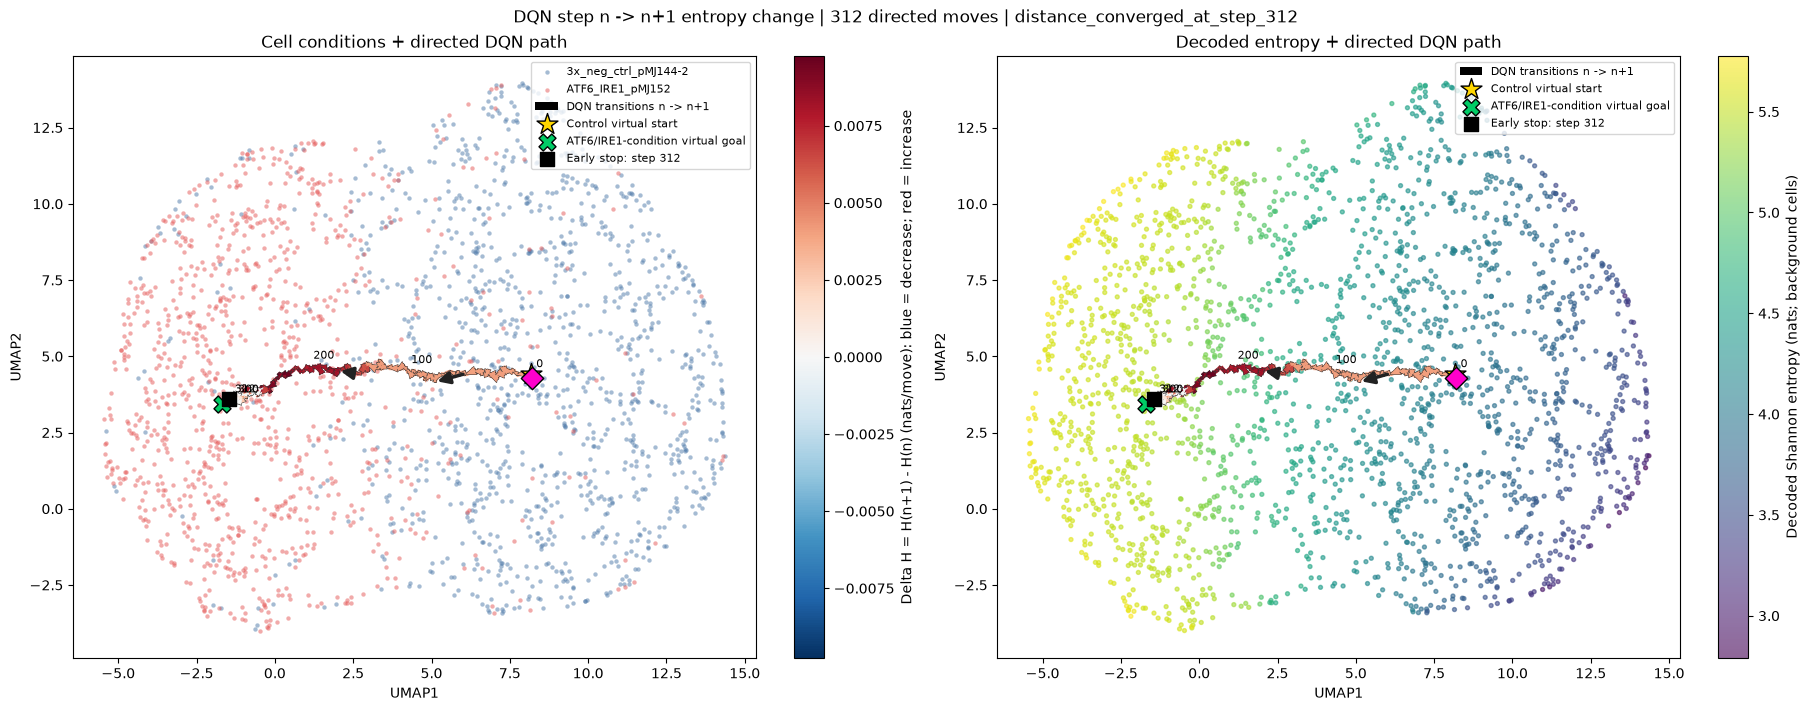

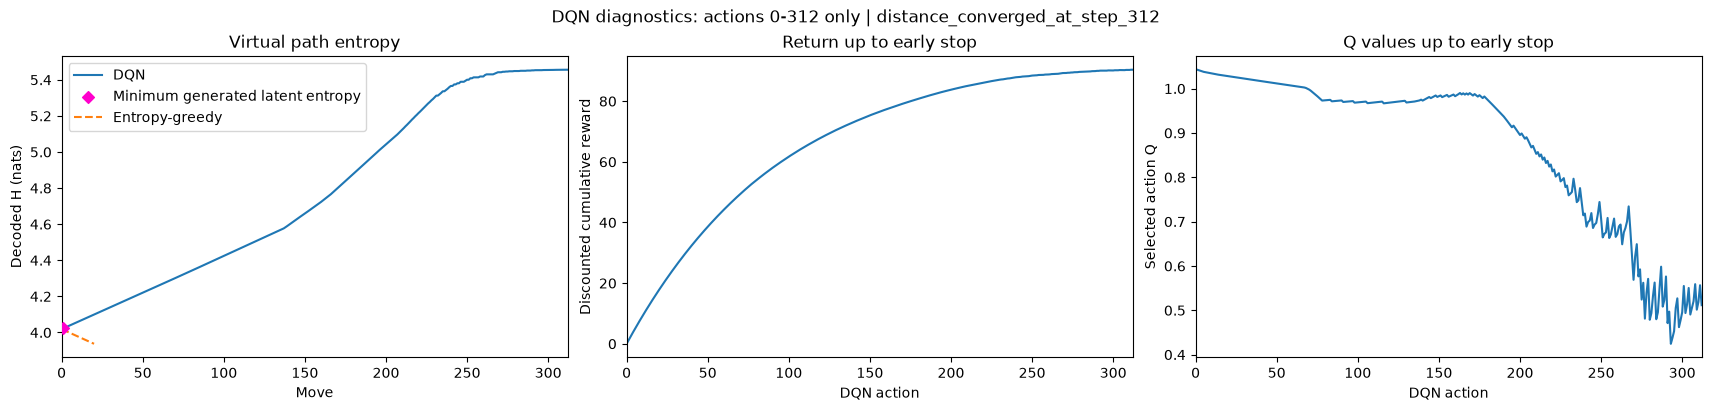

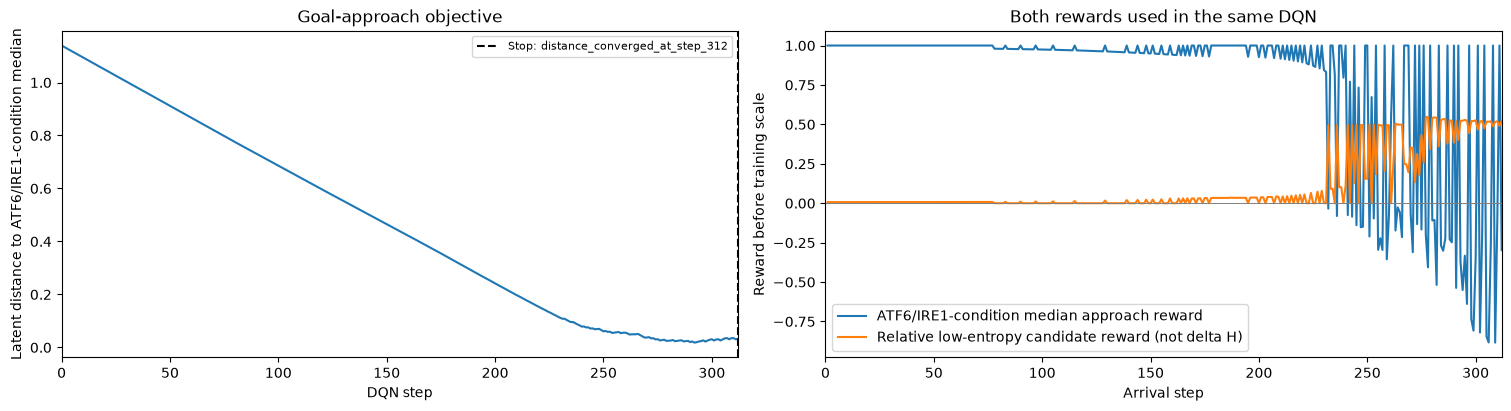

Saved virtual coordinates, entropy, separate reward components and policy: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/coordinate_dqn


In [13]:
@torch.no_grad()
def entropy_greedy_rollout():
    z = z_start_t[None].clone()
    h_min, t = decoded_entropy_t(z), torch.zeros(1, dtype=torch.long, device=DEVICE)
    path, entropies, rewards = [z[0].cpu().numpy()], [float(h_min)], []
    distance_history = (z_goal_t - z).norm(dim=1).repeat(RL_DISTANCE_PATIENCE + 1, 1)
    for _ in range(RL_MAX_STEPS):
        mask, moves, _ = action_mask(z, t)
        landing_entropy = decoded_entropy_t((z[:, None] + moves)[0]).masked_fill(~mask[0], torch.inf)
        if not mask.any():
            raise RuntimeError('No feasible virtual latent action during entropy-greedy rollout.')
        z, h, h_min, t, base, done = environment_step(z, h_min, t, landing_entropy.argmin()[None], moves, distance_history)
        path.append(z[0].cpu().numpy()); entropies.append(float(h)); rewards.append(float(base))
        if bool(done):
            break
    rewards = np.asarray(rewards)
    return {'path_z': np.asarray(path), 'entropy': np.asarray(entropies), 'base_rewards': rewards,
            'status': distance_stop_status(float((z_goal_t - z).norm()), int(t[0])),
            'base_return': float(np.sum(rewards * RL_GAMMA ** np.arange(len(rewards))))}


def trim_at_first_termination(result):
    path = np.asarray(result['path_z'])
    if path.ndim != 2 or path.shape[1] != LATENT_DIM or not np.isfinite(path).all():
        raise ValueError('Trajectory must contain finite 128D latent coordinates.')
    distances = torch.tensor(np.linalg.norm(path - z_goal, axis=1), device=DEVICE)
    distance_history = distances[:1].repeat(RL_DISTANCE_PATIENCE + 1, 1)
    stop_step = None
    for step in range(1, len(path)):
        if bool(distance_stop_state(distance_history, distances[step:step + 1], torch.tensor([step], device=DEVICE))[0]):
            stop_step = step
            break
    if stop_step is None:
        raise RuntimeError('Trajectory has not reached a goal, distance convergence, or step limit.')
    if not 1 <= stop_step <= RL_MAX_STEPS:
        raise ValueError(f'Invalid first termination step: {stop_step}')
    trimmed = dict(result)
    for key in ('path_z', 'entropy', 'support_distance'):
        if key in trimmed:
            if len(trimmed[key]) != len(path):
                raise ValueError(f'{key} must have one value per trajectory coordinate.')
            trimmed[key] = np.asarray(trimmed[key])[:stop_step + 1].copy()
    for key in ('actions', 'chosen_Q', 'base_rewards'):
        if key in trimmed:
            if len(trimmed[key]) != len(path) - 1:
                raise ValueError(f'{key} must have one value per trajectory action.')
            trimmed[key] = np.asarray(trimmed[key])[:stop_step].copy()
    trimmed['status'] = distance_stop_status(float(distances[stop_step]), stop_step)
    if 'base_rewards' in trimmed:
        trimmed['base_return'] = float(np.sum(trimmed['base_rewards'] * RL_GAMMA ** np.arange(stop_step)))
    elif stop_step != len(path) - 1:
        raise ValueError('Per-step rewards are required to truncate the trajectory return.')
    return trimmed


dqn_result = trim_at_first_termination(latent_rollout(latent_q))
policy_results = {'dqn': dqn_result,
                  'straight_goal_only': trim_at_first_termination(latent_rollout(None)),
                  'entropy_greedy': trim_at_first_termination(entropy_greedy_rollout())}
rl_actions = dqn_result['actions']
dqn_stop_step = len(rl_actions)
coordinate_space = dqn_result['path_z']
rl_path = np.arange(len(coordinate_space))
start_node, goal_node = 0, len(coordinate_space) - 1
coordinate_ids = np.array([f'vlatent_{step:04d}' for step in rl_path])
coordinate_umap = project_umap(coordinate_space)
endpoint_umap = project_umap(np.stack([z_start, z_goal]))
coordinate_entropy = dqn_result['entropy']
dqn_trajectory = {'path': rl_path, 'actions': rl_actions, 'status': dqn_result['status'],
                  'base_return': dqn_result['base_return']}
assert 1 <= len(rl_actions) <= RL_MAX_STEPS and len(coordinate_space) == len(rl_actions) + 1
assert dqn_result['status'] == distance_stop_status(float(np.linalg.norm(coordinate_space[-1] - z_goal)), dqn_stop_step)
goal_reached = bool(np.linalg.norm(coordinate_space[-1] - z_goal) <= RL_STEP_LENGTH * 1e-4)
print(f'DQN stopped at action {dqn_stop_step}/{RL_MAX_STEPS}: {dqn_result["status"]}; plotting {dqn_stop_step + 1} coordinates only.')
min_entropy_step = int(np.argmin(coordinate_entropy[1:])) + 1
observed_knn = NearestNeighbors(n_neighbors=REGION_SIZE).fit(Z_space)
support_distances, region_members = observed_knn.kneighbors(coordinate_space)
observed_raw_neighbors = observed_knn.kneighbors(Z_space, n_neighbors=REGION_SIZE + 1)[1]
observed_regions = np.array([np.r_[index, row[row != index][:REGION_SIZE - 1]] for index, row in enumerate(observed_raw_neighbors)])
observed_region_sq = np.sum((Z_space[observed_regions] - Z_space[observed_regions].mean(axis=1)[:, None]) ** 2, axis=2)
entropy_sigma = float(np.median(np.sqrt(observed_region_sq[observed_region_sq > 0])))
support_log_weights = -support_distances ** 2 / (2 * entropy_sigma ** 2)
support_weights = np.exp(support_log_weights - logsumexp(support_log_weights, axis=1, keepdims=True))
coordinate_atf6_condition_fraction = (support_weights * (cell_conditions[region_members] == 'ATF6_IRE1_pMJ152')).sum(axis=1)
coordinate_conditions = np.where(coordinate_atf6_condition_fraction >= 0.5, 'ATF6_IRE1_pMJ152', '3x_neg_ctrl_pMJ144-2')
step_lengths = np.linalg.norm(np.diff(coordinate_space, axis=0), axis=1)
reward_distances = np.linalg.norm(z_goal - coordinate_space, axis=1)
reward_progress = RL_PROGRESS_WEIGHT * (reward_distances[:-1] - reward_distances[1:]) / RL_STEP_LENGTH
candidate_audit_frames, candidate_minima, candidate_maxima = [], [], []
for start in range(len(rl_actions)):
    stop = start + 1
    audit_z = torch.tensor(coordinate_space[start:stop], device=DEVICE)
    audit_t = torch.arange(start, stop, device=DEVICE)
    audit_mask, audit_moves, _ = action_mask(audit_z, audit_t)
    audit_h, audit_min, audit_max = candidate_entropies(audit_z, audit_moves, audit_mask)
    audit_scores = relative_entropy_reward(audit_h, audit_min[:, None], audit_max[:, None])
    audit_choices = torch.tensor(rl_actions[start:stop], device=DEVICE)
    audit_rows = torch.arange(stop - start, device=DEVICE)
    assert audit_mask[audit_rows, audit_choices].all()
    np.testing.assert_allclose(audit_h[audit_rows, audit_choices].cpu().numpy(),
                               coordinate_entropy[start + 1:stop + 1], atol=1e-6)
    candidate_minima.append(audit_min.cpu().numpy())
    candidate_maxima.append(audit_max.cpu().numpy())
    candidate_audit_frames.append(pd.DataFrame({
        'from_step': np.repeat(np.arange(start, stop), N_ACTIONS),
        'action': np.tile(action_names, stop - start),
        'feasible': audit_mask.cpu().numpy().ravel(),
        'candidate_entropy_nats': audit_h.cpu().numpy().ravel(),
        'relative_entropy_reward': audit_scores.cpu().numpy().ravel(),
        'selected': (torch.arange(N_ACTIONS, device=DEVICE)[None] == audit_choices[:, None]).cpu().numpy().ravel(),
    }))
reward_candidate_min = np.concatenate(candidate_minima)
reward_candidate_max = np.concatenate(candidate_maxima)
reward_entropy = relative_entropy_reward(torch.tensor(coordinate_entropy[1:], dtype=torch.float32, device=DEVICE),
    torch.tensor(reward_candidate_min, device=DEVICE), torch.tensor(reward_candidate_max, device=DEVICE)).cpu().numpy()
reward_goal = np.zeros(len(rl_actions))
if reward_distances[-1] <= RL_STEP_LENGTH * 1e-4:
    reward_goal[-1] = RL_GOAL_BONUS
reward_reconstructed = reward_progress + reward_entropy - RL_STEP_COST + reward_goal
np.testing.assert_allclose(reward_reconstructed, dqn_result['base_rewards'], atol=3e-4, rtol=3e-4)
dqn_trajectory_df = pd.DataFrame({
    'step': rl_path, 'coordinate_id': coordinate_ids,
    'estimated_perturbation': coordinate_conditions, 'estimated_atf6_condition_fraction': coordinate_atf6_condition_fraction,
    'decoded_entropy_nats': coordinate_entropy,
    'decoded_entropy_min_so_far': np.minimum.accumulate(coordinate_entropy),
    'delta_entropy_nats': np.r_[np.nan, np.diff(coordinate_entropy)],
    'distance_to_goal': reward_distances,
    'UMAP1': coordinate_umap[:, 0], 'UMAP2': coordinate_umap[:, 1],
    'step_length': np.r_[np.nan, step_lengths], 'support_distance_k5': support_distances[:, -1],
    'chosen_action': [action_names[action] for action in rl_actions] + [''],
    'chosen_Q': np.r_[dqn_result['chosen_Q'], np.nan],
    'arrival_progress_reward': np.r_[np.nan, reward_progress],
    'arrival_entropy_reward': np.r_[np.nan, reward_entropy],
    'arrival_feasible_candidate_entropy_min': np.r_[np.nan, reward_candidate_min],
    'arrival_feasible_candidate_entropy_max': np.r_[np.nan, reward_candidate_max],
    'arrival_goal_bonus': np.r_[np.nan, reward_goal],
    'arrival_step_cost': np.r_[np.nan, np.full(len(rl_actions), -RL_STEP_COST)],
    'arrival_base_reward': np.r_[np.nan, dqn_result['base_rewards']],
    'arrival_training_reward': np.r_[np.nan, RL_REWARD_SCALE * dqn_result['base_rewards']],
})
baseline_rows = [{'policy': name, 'status': result['status'], 'moves': len(result['path_z']) - 1,
                  'discounted_base_return': result['base_return'], 'mean_path_entropy': float(result['entropy'].mean()),
                  'min_path_entropy': float(result['entropy'].min()), 'final_entropy': float(result['entropy'][-1]),
                  'min_generated_entropy': float(result['entropy'][1:].min()),
                  'min_generated_step': int(result['entropy'][1:].argmin()) + 1,
                  'final_distance_to_goal': float(np.linalg.norm(result['path_z'][-1] - z_goal)),
                  'entropy_decreasing_moves': int((np.diff(result['entropy']) < 0).sum())}
                 for name, result in policy_results.items()]
display(pd.DataFrame(baseline_rows))
display(dqn_trajectory_df.iloc[np.unique(np.r_[0:3, min_entropy_step, len(rl_path) - 3:len(rl_path)])])
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm
import matplotlib.patheffects as path_effects

path_delta_h = np.diff(coordinate_entropy)
path_displacements = np.diff(coordinate_umap, axis=0)
np.testing.assert_allclose(path_delta_h, dqn_trajectory_df['delta_entropy_nats'].iloc[1:])
if not np.isfinite(path_delta_h).all() or not np.isfinite(path_displacements).all():
    raise ValueError('Non-finite DQN transition entropy or UMAP displacement.')
path_color_limit = max(float(np.abs(path_delta_h).max()), np.finfo(float).eps)
path_delta_norm = TwoSlopeNorm(vmin=-path_color_limit, vcenter=0, vmax=path_color_limit)
fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
for label, color in zip(CONDITIONS, ['#4C78A8', '#E45756']):
    selected = cell_conditions == label
    axes[0].scatter(*Z_umap[selected].T, s=10, c=color, alpha=0.5, linewidths=0, label=label)
entropy_scatter = axes[1].scatter(*Z_umap.T, c=observed_decoded_entropy,
                                 s=8, cmap='viridis', alpha=0.6)
fig.colorbar(entropy_scatter, ax=axes[1], label='Decoded Shannon entropy (nats; background cells)')
path_arrow_artists = []
path_line_artists = []
path_segments = np.stack([coordinate_umap[:-1], coordinate_umap[1:]], axis=1)
for axis in axes:
    path_lines = LineCollection(path_segments, cmap='RdBu_r', norm=path_delta_norm,
        linewidths=3.0, label='_nolegend_', zorder=3)
    path_lines.set_array(path_delta_h)
    axis.add_collection(path_lines)
    path_line_artists.append(path_lines)
    path_arrows = axis.quiver(coordinate_umap[:-1, 0], coordinate_umap[:-1, 1],
        path_displacements[:, 0], path_displacements[:, 1], path_delta_h,
        angles='xy', scale_units='xy', scale=1, pivot='tail', cmap='RdBu_r', norm=path_delta_norm,
        width=0.004, minlength=0, headwidth=4, headlength=5, headaxislength=4.5,
        label='DQN transitions n -> n+1', zorder=4)
    path_arrows.set_path_effects([path_effects.Stroke(linewidth=0.7, foreground='#333333'),
                                  path_effects.Normal()])
    path_arrow_artists.append(path_arrows)
    axis.scatter(*coordinate_umap[0], marker='*', s=250, c='#FFD700', edgecolors='black', label='Control virtual start', zorder=5)
    axis.scatter(*endpoint_umap[1], marker='X', s=150, c='#00CC66', edgecolors='black', label='ATF6/IRE1-condition virtual goal', zorder=5)
    if not goal_reached:
        axis.scatter(*coordinate_umap[-1], marker='s', s=90, c='black', label=f'Early stop: step {dqn_stop_step}', zorder=6)
    axis.scatter(*coordinate_umap[min_entropy_step], marker='D', s=130, c='#FF00CC', edgecolors='black',
        label='_nolegend_', zorder=6)
    axis.set(xlabel='UMAP1', ylabel='UMAP2')
    for step in sorted(set(range(0, len(coordinate_umap), 100)) | {len(coordinate_umap) - 1}):
        axis.annotate(str(step), coordinate_umap[step], xytext=(4, 5), textcoords='offset points',
                      fontsize=8, zorder=7)
    axis.legend(fontsize=8, loc='upper right')
    for guide_start in (50, 150, 450):
        guide_end = guide_start + 20
        if guide_end >= len(coordinate_umap):
            continue
        axis.annotate('', xy=coordinate_umap[guide_end], xytext=coordinate_umap[guide_start],
            arrowprops={'arrowstyle': '-|>', 'color': '#222222', 'lw': 2.5, 'mutation_scale': 18}, zorder=8)
axes[0].set_title('Cell conditions + directed DQN path')
axes[1].set_title('Decoded entropy + directed DQN path')
fig.colorbar(path_arrows, ax=axes[0],
    label='Delta H = H(n+1) - H(n) (nats/move): blue = decrease; red = increase')
np.testing.assert_allclose(entropy_scatter.get_array(), observed_decoded_entropy)
assert entropy_scatter.get_cmap().name == 'viridis'
np.testing.assert_allclose(axes[0].get_xlim(), axes[1].get_xlim())
np.testing.assert_allclose(axes[0].get_ylim(), axes[1].get_ylim())
for lines in path_line_artists:
    np.testing.assert_allclose(lines.get_array(), path_delta_h)
    np.testing.assert_allclose(lines.get_segments(), path_segments)
    assert lines.norm is path_delta_norm and lines.get_cmap().name == 'RdBu_r'
    assert len(lines.get_segments()) == len(rl_actions) <= RL_MAX_STEPS
for arrows in path_arrow_artists:
    np.testing.assert_allclose(arrows.get_array(), path_delta_h)
    np.testing.assert_allclose(np.column_stack([arrows.U, arrows.V]), path_displacements)
    np.testing.assert_allclose(arrows.get_offsets(), coordinate_umap[:-1])
    assert arrows.N == len(rl_actions) <= RL_MAX_STEPS
fig.suptitle(f'DQN step n -> n+1 entropy change | {len(rl_actions)} directed moves | {dqn_result["status"]}')
fig.savefig(RL_RESULT_DIR / 'dqn_coordinate_umap_path.png', dpi=180, bbox_inches='tight')
plt.show()
rl_history_df = pd.DataFrame(rl_history)
fig, axes = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
axes[0].plot(rl_path, coordinate_entropy, label='DQN')
axes[0].scatter(min_entropy_step, coordinate_entropy[min_entropy_step], c='#FF00CC', marker='D',
                label='Minimum generated latent entropy', zorder=5)
baseline_entropy_plot = policy_results['entropy_greedy']['entropy'][:dqn_stop_step + 1]
axes[0].plot(np.arange(len(baseline_entropy_plot)), baseline_entropy_plot, ls='--', label='Entropy-greedy')
axes[0].set(xlim=(0, dqn_stop_step), xlabel='Move', ylabel='Decoded H (nats)', title='Virtual path entropy')
assert all(np.max(line.get_xdata()) <= dqn_stop_step for line in axes[0].lines)
axes[0].legend()
path_discounted_return = np.r_[0.0, np.cumsum(dqn_result['base_rewards'] * RL_GAMMA ** np.arange(dqn_stop_step))]
np.testing.assert_allclose(path_discounted_return[-1], dqn_result['base_return'])
axes[1].plot(rl_path, path_discounted_return)
axes[1].set(xlabel='DQN action', ylabel='Discounted cumulative reward', title='Return up to early stop')
axes[2].plot(rl_path[1:], dqn_result['chosen_Q'])
axes[2].set(xlabel='DQN action', ylabel='Selected action Q', title='Q values up to early stop')
for axis in axes:
    axis.set_xlim(0, dqn_stop_step)
    for line in axis.lines:
        assert np.all((np.asarray(line.get_xdata()) >= 0) & (np.asarray(line.get_xdata()) <= dqn_stop_step))
fig.suptitle(f'DQN diagnostics: actions 0-{dqn_stop_step} only | {dqn_result["status"]}')
fig.savefig(RL_RESULT_DIR / 'dqn_coordinate_training_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
axes[0].plot(rl_path, reward_distances)
axes[0].axvline(dqn_stop_step, color='black', ls='--', label=f'Stop: {dqn_result["status"]}')
axes[0].legend(fontsize=8)
axes[0].set(xlim=(0, dqn_stop_step), xlabel='DQN step', ylabel='Latent distance to ATF6/IRE1-condition median', title='Goal-approach objective')
axes[1].plot(rl_path[1:], reward_progress, label='ATF6/IRE1-condition median approach reward')
axes[1].plot(rl_path[1:], reward_entropy, label='Relative low-entropy candidate reward (not delta H)')
axes[1].axhline(0, color='grey', lw=0.7)
axes[1].set(xlim=(0, dqn_stop_step), xlabel='Arrival step', ylabel='Reward before training scale', title='Both rewards used in the same DQN')
axes[1].legend()
fig.savefig(RL_RESULT_DIR / 'dqn_joint_reward_components.png', dpi=180, bbox_inches='tight')
plt.show()
latent_columns = [f'Z{dimension + 1}' for dimension in range(LATENT_DIM)]
coordinate_path_export = pd.concat([dqn_trajectory_df, pd.DataFrame(coordinate_space, columns=latent_columns)], axis=1)
coordinate_path_export.to_csv(RL_RESULT_DIR / 'dqn_trajectory.csv', index=False)
pd.concat(candidate_audit_frames, ignore_index=True).to_csv(RL_RESULT_DIR / 'dqn_candidate_entropy_audit.csv', index=False)
coordinate_path_export.iloc[[min_entropy_step]].to_csv(RL_RESULT_DIR / 'dqn_min_entropy_latent.csv', index=False)
rl_history_df.to_csv(RL_RESULT_DIR / 'dqn_training.csv', index=False)
pd.DataFrame(rl_episodes).to_csv(RL_RESULT_DIR / 'dqn_episodes.csv', index=False)
pd.DataFrame(baseline_rows).to_csv(RL_RESULT_DIR / 'policy_summary.csv', index=False)
np.savez_compressed(RL_RESULT_DIR / 'coordinate_graph.npz', Z_space=Z_space,
                    cell_barcodes=adata.obs_names.to_numpy(dtype=str), coordinate_space=coordinate_space,
                    coordinate_umap=coordinate_umap, observed_umap=Z_umap, endpoint_umap=endpoint_umap, region_members=region_members, support_weights=support_weights,
                    z_start=z_start, z_goal=z_goal, pca_median_xy=pca_median_xy, decoded_entropy=coordinate_entropy)
coordinate_run_config = {
    'data_path': str(DATA_PATH), 'conditions': CONDITIONS, 'ko_target': KO_TARGET,
    'n_cells': adata.n_obs, 'n_genes': adata.n_vars,
    'workflow_version': WORKFLOW_VERSION, 'gene_selection': adata.uns['deg_selection'],
    'display_space': 'fixed UMAP from section 4', 'umap_model_path': str(UMAP_MODEL_PATH),
    'endpoint_umap': endpoint_umap.tolist(),
    'start': 'inverse PCA of 3x_neg_ctrl_pMJ144-2 perturbation median (virtual 128D coordinate)',
    'goal': 'inverse PCA of ATF6_IRE1_pMJ152 perturbation median (virtual 128D coordinate)',
    'pca_median_xy': pca_median_xy.tolist(), 'z_start': z_start.tolist(), 'z_goal': z_goal.tolist(),
    'action_space': f'{N_ACTIONS} virtual latent actions: goal, away from goal, signed latent axes; step <= L',
    'state_space': 'continuous virtual 128D latent coordinates generated by actions; no cell graph',
    'step_length_cap_L': RL_STEP_LENGTH, 'latent_start_goal_distance': rl_total_distance,
    'minimum_moves': RL_MIN_MOVES, 'max_episode_moves': RL_MAX_STEPS,
    'termination': 'first goal arrival, best-distance improvement <= min_delta over patience moves, or max steps; no forced goal endpoint',
    'distance_patience': RL_DISTANCE_PATIENCE, 'distance_min_delta': RL_DISTANCE_MIN_DELTA,
    'goal_reached': goal_reached, 'final_distance_to_goal': float(reward_distances[-1]),
    'checkpoint_selection': 'maximum discounted joint reward over greedy evaluations with goal/convergence termination',
    'support_constraint': f'5th nearest observed cell <= {rl_support_radius:.6g} (q{RL_SUPPORT_QUANTILE}); goal action exempt',
    'reward_version': RL_REWARD_VERSION,
    'reward': 'progress_weight*(d_current-d_next)/L + entropy_weight*(Hmax_feasible_next-Hchosen_next)/(Hmax_feasible_next-Hmin_feasible_next) - step_cost + goal_bonus*(first_goal_arrival)',
    'entropy_reward_ties': 'all feasible candidates tied within 1e-7 nats: score=1; otherwise min-max score clipped to [0,1]',
    'entropy_reward_reference': 'only feasible generated NEXT latent candidates, not previous state or observed cells',
    'entropy': 'Shannon H of decoded expression p=expm1(max(decoder(z),0))/sum (nats)',
    'entropy_floor': rl_entropy_floor, 'entropy_scale': rl_entropy_scale,
    'progress_weight': RL_PROGRESS_WEIGHT, 'step_cost': RL_STEP_COST, 'entropy_weight': RL_ENTROPY_WEIGHT,
    'goal_bonus': RL_GOAL_BONUS, 'reward_scale': RL_REWARD_SCALE, 'gamma': RL_GAMMA,
    'selected_checkpoint_vector_step': best_rl_step, 'status': dqn_trajectory['status'],
    'moves': len(rl_actions), 'path_observations': len(rl_path),
    'min_entropy_step': min_entropy_step, 'min_entropy_nats': float(coordinate_entropy[min_entropy_step]),
    'start_cell_barcode': start_barcode, 'goal_cell_barcode': end_barcode,
    'start_coordinate_id': coordinate_ids[0], 'end_coordinate_id': coordinate_ids[-1],
    'goal_coordinate_id': coordinate_ids[-1] if goal_reached else None,
    'minimum_search_scope': f'generated DQN trajectory steps 1-{len(rl_actions)}; not a global optimum guarantee',
    'tf_expression_method': 'Gaussian distance-weighted CP10K of nearest 5 measured cells, then log1p',
    'entropy_sigma': entropy_sigma,
}
(RL_RESULT_DIR / 'run_config.json').write_text(json.dumps(coordinate_run_config, indent=2))
torch.save({'vae': vae.state_dict(), 'latent_q': latent_q.state_dict(),
            'pca_components': pca.components_, 'pca_mean': pca.mean_,
            'gene_symbols': adata.var_names.to_numpy(dtype=str),
            'gene_selection': adata.uns['deg_selection'], 'display_space': 'fixed UMAP from section 4',
            'cell_barcodes': adata.obs_names.to_numpy(dtype=str), 'conditions': CONDITIONS}, RL_RESULT_DIR / 'coordinate_models.pt')
print(f'Saved virtual coordinates, entropy, separate reward components and policy: {RL_RESULT_DIR}')

## 7. 학습된 가상 latent 경로 영상

저장된 학습 결과를 읽어 재학습 없이 영상을 생성합니다. 왼쪽은 기존 고정 UMAP의 가상 latent 경로, 오른쪽은 H, 관찰용 이동별 `ΔH[t] = H[t] − H[t−1]`, 동일 이동의 저장된 보상 `arrival_base_reward`입니다. entropy 보상은 delta H가 아니라 **허용된 다음 가상 후보 중 상대적으로 낮은 H**를 기준으로 하며, H가 증가한 이동에서도 양수가 될 수 있습니다. 보상은 학습용 0.1 배율 적용 전 원래 값이고 누적 보상이 아닙니다. 최대 500회 이내 목표 도착·거리 수렴·최대 step 중 최초 종료까지의 실제 경로와 최소 H 좌표를 표시합니다. 목표 도착 보너스는 실제 도착한 경우에만 지급됩니다. 기존 결과는 5절의 수렴 종료 조건으로 재학습하고 6절에서 내보낸 뒤 사용합니다.

각 값은 이동의 도착 스텝 t(1부터)에 정렬하며, 이동 전 시작점에는 변화량이나 보상을 만들지 않습니다. `MOVES_PER_FRAME`마다 프레임을 그리지만 그래프에는 그 시점까지의 모든 이동을 포함하고 마지막 이동을 항상 표시합니다.

영상은 `coordinate_dqn/dqn_latent_pca_transition.mp4`로 저장합니다. DQN step은 생물학적 시간이 아닙니다.

좌표·배경·CSV·동영상은 4번에서 fit한 동일한 UMAP 모델을 사용합니다. DQN 계산 공간은 latent로 유지합니다.

In [14]:
print(f'Condition trajectory results: {RL_RESULT_DIR}')

Condition trajectory results: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/coordinate_dqn


In [15]:
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import torch
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Video, display
import imageio_ffmpeg

VIDEO_DIR = RESULT_ROOT / 'coordinate_dqn'
VIDEO_PATH = VIDEO_DIR / 'dqn_latent_umap_transition.mp4'
VIDEO_FPS, MOVES_PER_FRAME = 24, 2
VIDEO_FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()
video_table = pd.read_csv(VIDEO_DIR / 'dqn_trajectory.csv')
video_config = json.loads((VIDEO_DIR / 'run_config.json').read_text())
if video_config.get('reward_version') != 'candidate_relative_entropy_distance_convergence_v7':
    raise ValueError('Saved results use an older algorithm. Run section 5 (DQN environment, components and training), then section 6 (export), before section 7. VAE/PCA retraining is not required.')
with np.load(VIDEO_DIR / 'coordinate_graph.npz', allow_pickle=False) as video_saved:
    video_cell_z = video_saved['Z_space'].copy()
    video_path_z = video_saved['coordinate_space'].copy()
    video_saved_xy = video_saved['coordinate_umap'].copy()
    video_cell_xy = video_saved['observed_umap'].copy()
    video_barcodes = video_saved['cell_barcodes'].astype(str)
video_checkpoint = torch.load(VIDEO_DIR / 'coordinate_models.pt', map_location='cpu', weights_only=False)
if video_checkpoint.get('display_space') != 'fixed UMAP from section 4':
    raise ValueError('Expected current fixed-UMAP model checkpoint; rerun sections 4-6.')
del video_checkpoint
np.testing.assert_array_equal(video_cell_xy, Z_umap)
video_xy = video_table[['UMAP1', 'UMAP2']].to_numpy()
video_entropy = video_table['decoded_entropy_nats'].to_numpy(dtype=float)
video_delta_entropy = np.diff(video_entropy)
video_rewards = video_table['arrival_base_reward'].to_numpy(dtype=float)[1:]
video_progress_reward = video_table['arrival_progress_reward'].to_numpy(dtype=float)[1:]
video_entropy_reward = video_table['arrival_entropy_reward'].to_numpy(dtype=float)[1:]
video_goal_reward = video_table['arrival_goal_bonus'].to_numpy(dtype=float)[1:]
video_step_cost = video_table['arrival_step_cost'].to_numpy(dtype=float)[1:]
n_moves = len(video_table) - 1
if not 1 <= n_moves <= min(500, video_config['max_episode_moves']):
    raise ValueError('Expected 1 to 500 saved DQN moves, ending at goal arrival or distance convergence.')
if video_config['moves'] != n_moves:
    raise ValueError('Saved configuration and trajectory disagree about the termination step.')
video_move_steps = np.arange(1, n_moves + 1)
if n_moves < 1 or not np.array_equal(video_table['step'].to_numpy(), np.arange(n_moves + 1)):
    raise ValueError('Expected consecutive saved steps from zero.')
for values in (video_path_z, video_xy, video_entropy, video_rewards, video_progress_reward,
               video_entropy_reward, video_goal_reward, video_step_cost):
    if not np.isfinite(values).all():
        raise ValueError('Non-finite saved trajectory or reward.')
np.testing.assert_allclose(video_path_z, video_table[[f'Z{dimension + 1}' for dimension in range(video_cell_z.shape[1])]], atol=1e-6)
np.testing.assert_allclose(video_xy, video_saved_xy, atol=1e-5, rtol=1e-4)
np.testing.assert_allclose(project_umap(video_path_z), video_xy, atol=1e-5, rtol=1e-4)
video_candidate_min = video_table['arrival_feasible_candidate_entropy_min'].to_numpy(dtype=np.float32)[1:]
video_candidate_max = video_table['arrival_feasible_candidate_entropy_max'].to_numpy(dtype=np.float32)[1:]
video_candidate_span = video_candidate_max - video_candidate_min
video_relative_scores = np.where(video_candidate_span > 1e-7,
    (video_candidate_max - video_entropy[1:].astype(np.float32)) / np.maximum(video_candidate_span, 1e-7), 1.0)
np.testing.assert_allclose(video_entropy_reward,
    video_config['entropy_weight'] * np.clip(video_relative_scores, 0, 1), atol=1e-6)
np.testing.assert_allclose(video_rewards, video_progress_reward + video_entropy_reward + video_goal_reward + video_step_cost, atol=3e-4, rtol=3e-4)
video_distances = np.linalg.norm(video_path_z - np.asarray(video_config['z_goal']), axis=1)
video_goal_reached = bool(video_distances[-1] <= video_config['step_length_cap_L'] * 1e-4)
video_best_distances = np.minimum.accumulate(video_distances)
video_patience = video_config['distance_patience']
video_stops = video_distances <= video_config['step_length_cap_L'] * 1e-4
video_stops[video_patience:] |= video_best_distances[:-video_patience] - video_best_distances[video_patience:] <= video_config['distance_min_delta']
video_stops |= np.arange(n_moves + 1) >= video_config['max_episode_moves']
if np.flatnonzero(video_stops).tolist() != [n_moves]:
    raise ValueError('Saved trajectory must end at its first goal/convergence/limit termination.')
video_stop_reason = 'target_reached' if video_goal_reached else ('max_steps' if n_moves >= video_config['max_episode_moves'] else 'distance_converged')
if video_config['status'] != f'{video_stop_reason}_at_step_{n_moves}' or video_config['goal_reached'] != video_goal_reached:
    raise ValueError('Saved termination reason does not match the actual endpoint.')
if (video_distances[:-1] <= video_config['step_length_cap_L'] * 1e-4).any():
    raise ValueError('Saved trajectory continues after its first goal arrival.')
np.testing.assert_allclose(video_table['distance_to_goal'], video_distances, atol=1e-6)
np.testing.assert_allclose(video_table['delta_entropy_nats'].iloc[1:], video_delta_entropy, atol=1e-6)
video_expected_goal_reward = np.zeros(n_moves)
if video_goal_reached:
    video_expected_goal_reward[-1] = video_config['goal_bonus']
np.testing.assert_allclose(video_goal_reward, video_expected_goal_reward, atol=1e-6)
np.testing.assert_allclose(video_step_cost, -video_config['step_cost'], atol=1e-6)
np.testing.assert_allclose(video_progress_reward, -video_config['progress_weight'] * np.diff(video_distances) / video_config['step_length_cap_L'], atol=3e-4, rtol=3e-4)
if np.linalg.norm(np.diff(video_path_z, axis=0), axis=1).max() > video_config['step_length_cap_L'] * (1 + 1e-4):
    raise ValueError('Latent action exceeded the saved step cap.')
np.testing.assert_array_equal(video_barcodes, adata.obs_names.to_numpy(dtype=str))
video_cell_conditions = adata.obs.loc[video_barcodes, 'perturbation'].astype(str).to_numpy()
frame_schedule = np.r_[np.zeros(VIDEO_FPS, dtype=int),
                       np.unique(np.r_[np.arange(0, len(video_table), MOVES_PER_FRAME), n_moves]),
                       np.full(2 * VIDEO_FPS, n_moves, dtype=int)]
video_fig = plt.figure(figsize=(17, 10), constrained_layout=True)
video_grid = video_fig.add_gridspec(3, 2, width_ratios=[1.7, 1])
video_ax = video_fig.add_subplot(video_grid[:, 0])
entropy_ax = video_fig.add_subplot(video_grid[0, 1])
delta_ax = video_fig.add_subplot(video_grid[1, 1], sharex=entropy_ax)
reward_ax = video_fig.add_subplot(video_grid[2, 1], sharex=entropy_ax)
for label, color in [('3x_neg_ctrl_pMJ144-2', '#4C78A8'), ('ATF6_IRE1_pMJ152', '#E45756')]:
    selected = video_cell_conditions == label
    video_ax.scatter(*video_cell_xy[selected].T, s=9, c=color, alpha=0.35, label=label, zorder=1)
video_ax.scatter(*video_xy[0], marker='*', s=230, c='#FFD700', edgecolors='black', label='Control virtual start', zorder=5)
video_goal_xy = np.asarray(video_config['endpoint_umap'])[1]
video_ax.scatter(*video_goal_xy, marker='X', s=130, c='#00CC66', edgecolors='black', label='ATF6/IRE1-condition median goal', zorder=5)
trail, = video_ax.plot([], [], '-', c='#222222', lw=1.8, zorder=3)
current_cell = video_ax.scatter(*video_xy[0], s=95, c='#FFD700', edgecolors='black', zorder=6)
video_minimum = video_ax.scatter([], [], marker='D', s=110, c='#FF00CC', edgecolors='black',
                                 label='_nolegend_', zorder=6)
status_text = video_ax.text(0.02, 0.98, '', transform=video_ax.transAxes, va='top', fontsize=9,
                           bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9}, zorder=7)
video_ax.set(xlabel='UMAP1', ylabel='UMAP2',
             title='Learned DQN: generated 128D latent coordinates on fixed UMAP')
video_ax.legend(loc='lower left', fontsize=8)
video_series = []
for axis, values, color, label in [
    (entropy_ax, video_entropy, '#4C78A8', 'Decoded H'),
    (delta_ax, video_delta_entropy, '#E45756', 'Delta H = H[next] - H[current]'),
    (reward_ax, video_rewards, '#222222', 'Total'),
    (reward_ax, video_progress_reward, '#59A14F', 'ATF6/IRE1-condition approach'),
    (reward_ax, video_entropy_reward, '#B07AA1', 'Relative low candidate H'),
    (reward_ax, video_goal_reward, '#F28E2B', 'Arrival bonus'),
    (reward_ax, video_step_cost, '#999999', 'Step cost'),
]:
    line, = axis.plot([], [], color=color, lw=1.4, label=label)
    video_series.append((line, values, axis is entropy_ax))
for axis, values, ylabel in [
    (entropy_ax, video_entropy, 'Decoded Shannon H (nats)'),
    (delta_ax, video_delta_entropy, 'Delta H (nats / move)'),
    (reward_ax, np.concatenate([video_rewards, video_progress_reward, video_entropy_reward, video_goal_reward, video_step_cost]), 'Reward per move (unscaled)'),
]:
    lower, upper = float(values.min()), float(values.max())
    if axis is not entropy_ax:
        lower, upper = min(lower, 0), max(upper, 0)
        axis.axhline(0, c='#777777', lw=0.8, ls='--')
    margin = max((upper - lower) * 0.12, 1e-8)
    axis.set(xlim=(-0.5, n_moves + 0.5), ylim=(lower - margin, upper + margin), ylabel=ylabel, xlabel='Arrival move')
    axis.grid(alpha=0.2)
    axis.legend(fontsize=8, ncol=2 if axis is reward_ax else 1)
video_fig.suptitle(f'{n_moves} virtual latent moves | {video_config["status"]} | approach + relative low candidate H rewards')


def update_umap_video(step: int):
    trail.set_data(video_xy[:step + 1, 0], video_xy[:step + 1, 1])
    current_cell.set_offsets(video_xy[step:step + 1])
    video_best_step = int(video_entropy[1:step + 1].argmin()) + 1 if step else None
    video_minimum.set_offsets(video_xy[video_best_step:video_best_step + 1] if step else np.empty((0, 2)))
    for line, values, is_state in video_series:
        count = step + 1 if is_state else step
        line.set_data(np.arange(count) if is_state else video_move_steps[:count], values[:count])
    status = video_config['status'] if step == n_moves else 'Moving'
    current_cell.set_facecolor('black' if step == n_moves and not video_goal_reached else '#FFD700')
    transition_text = (f'Delta H={video_delta_entropy[step - 1]:+.6f} nats\n'
                       f'Approach={video_progress_reward[step - 1]:+.4f}; entropy={video_entropy_reward[step - 1]:+.4f}\n'
                       f'Arrival bonus={video_goal_reward[step - 1]:+.1f}; total={video_rewards[step - 1]:+.4f}'
                       if step else 'Start: no transition or reward yet')
    status_text.set_text(f'Move {step}/{n_moves} | {status}\n'
                         f'{video_table.coordinate_id.iloc[step]} | H={video_entropy[step]:.6f}\n'
                         f'Latent distance to ATF6/IRE1-condition={video_table.distance_to_goal.iloc[step]:.5f}\n'
                         f'{transition_text}')
    return trail, current_cell, video_minimum, status_text, *(item[0] for item in video_series)


for video_check_step in (0, 1, n_moves):
    update_umap_video(video_check_step)
    for line, values, is_state in video_series:
        count = video_check_step + 1 if is_state else video_check_step
        np.testing.assert_allclose(line.get_ydata(), values[:count])
umap_animation = animation.FuncAnimation(video_fig, update_umap_video, frames=frame_schedule,
                                        interval=1000 / VIDEO_FPS, blit=False, repeat=False)
video_writer = animation.FFMpegWriter(fps=VIDEO_FPS, codec='libx264', bitrate=2400,
                                      extra_args=['-pix_fmt', 'yuv420p', '-movflags', '+faststart', '-threads', '2'])
try:
    with plt.rc_context({'animation.ffmpeg_path': VIDEO_FFMPEG}):
        umap_animation.save(str(VIDEO_PATH), writer=video_writer, dpi=100)
finally:
    plt.close(video_fig)
video_decode = subprocess.run([VIDEO_FFMPEG, '-v', 'error', '-xerror', '-i', str(VIDEO_PATH),
                               '-progress', 'pipe:1', '-nostats', '-f', 'null', '-'],
                              check=True, capture_output=True, text=True)
video_decoded_frames = [int(line.split('=', 1)[1]) for line in video_decode.stdout.splitlines() if line.startswith('frame=')]
assert video_decoded_frames[-1] == len(frame_schedule)
(VIDEO_DIR / 'video_metadata.json').write_text(json.dumps({
    'reward_version': video_config['reward_version'], 'frames': len(frame_schedule), 'fps': VIDEO_FPS,
    'moves': n_moves, 'minimum_generated_entropy_step': int(video_entropy[1:].argmin()) + 1,
    'status': video_config['status'], 'goal_reached': video_goal_reached,
    'distance_patience': video_config['distance_patience'], 'distance_min_delta': video_config['distance_min_delta'],
    'duration_seconds': len(frame_schedule) / VIDEO_FPS,
    'display': 'saved virtual 128D path on fixed UMAP; H, delta H, separate rewards and total',
    'validation': 'reward reconstruction, coordinate projection, all frames decoded and counted',
}, indent=2))
print(f'Saved {VIDEO_PATH}; {n_moves} moves; {len(frame_schedule) / VIDEO_FPS:.2f} seconds; all frames decoded.')
display(Video(str(VIDEO_PATH), embed=True, html_attributes='controls loop'))

Saved /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/coordinate_dqn/dqn_latent_umap_transition.mp4; 312 moves; 9.54 seconds; all frames decoded.


## 8. 좌표 경로의 TF 변동 순위와 latent decoder 발현 히트맵

TF 목록: https://resources.aertslab.org/cistarget/tf_lists/allTFs_hg38.txt

경로는 실제 세포가 아닌 가상 Z 좌표이며 early stop까지의 DQN step 0–종료 step만 사용합니다. **첫 번째 figure**는 TF 목록과 원래 VAE 출력 유전자의 교집합 전체를 대상으로, 각 TF의 step별 **decoded 발현 표본분산(variance, ddof=1) 상위 10개를 내림차순**으로 표시합니다. 분산은 유전자별 percentage 정규화 전 decoder 원출력(log1p CP10K scale)에 대해 계산하며, 값이 클수록 경로를 따라 발현 변동이 큽니다. 동점은 TF 이름순입니다. 전체 순위는 `dqn_path_tf_decoded_variance_ranking.csv`에 저장합니다. 기존 이웃 기반 분산 순위 파일과 entropy 순위 파일은 보존하지만 이 두 figure의 순위에는 사용하지 않습니다.

**두 번째 figure의 하단 히트맵**은 각 DQN step의 latent Z 좌표를 저장된 원래 VAE decoder에 직접 입력한 발현을 **유전자별 min–max percentage**로 표시합니다. 각 유전자의 경로 내 최소 발현은 0%(흰색), 최대 발현은 100%(빨강)이며 `(expression - gene_min) / (gene_max - gene_min) * 100`으로 계산합니다. 경로 내 발현이 일정한 유전자는 변동 없음으로 0% 표시하고 목록을 출력합니다. 이는 유전자 간 절대 발현 비교나 전체 발현 중 비율이 아닙니다. Shannon entropy, z-score, smoothing, clipping은 적용하지 않습니다.

**두 번째 figure**는 첫 번째 figure에서 선정한 **동일한 상위 10 TF를 동일한 variance 순서**로 표시합니다. Decoder에 없는 TF를 이웃 발현으로 대체하지 않습니다. Decoder 원출력(log1p CP10K scale)은 `dqn_path_top_tf_decoded_expression.csv`로 저장하고 표시용 percentage는 `dqn_path_top_tf_decoded_percentage.csv`에 별도로 저장합니다. 저장된 latent 경로 및 decoder baseline 재현 여부, variance 순위와 실제 히트맵 배열·CSV의 일치 여부를 검증합니다.

**상단 비율 띠**는 Z 공간 최근접 실제 세포 **10개**의 단순 개수 비율(`ATF6/IRE1-condition 수 / 10`)입니다. 0=파랑(Control 100%), 0.5=흰색, 1=빨강(ATF6/IRE1-condition 100%)이며 거리 가중치나 다수결 이진 라벨을 사용하지 않습니다. 띠와 범례 높이를 키우고 범례 글자는 12pt로 표시합니다. 이웃 10개는 색상 띠에만 사용하며 TF 순위와 하단 발현값은 decoder로만 계산합니다.

DQN step은 생물학적 시간이 아니며, 공간 보간에 따른 변화는 인과관계나 실제 분화를 증명하지 않습니다.

In [16]:
print(f'Preserved decoder genes: {adata.n_vars}; target: {KO_TARGET}')

Preserved decoder genes: 3000; target: ATF6


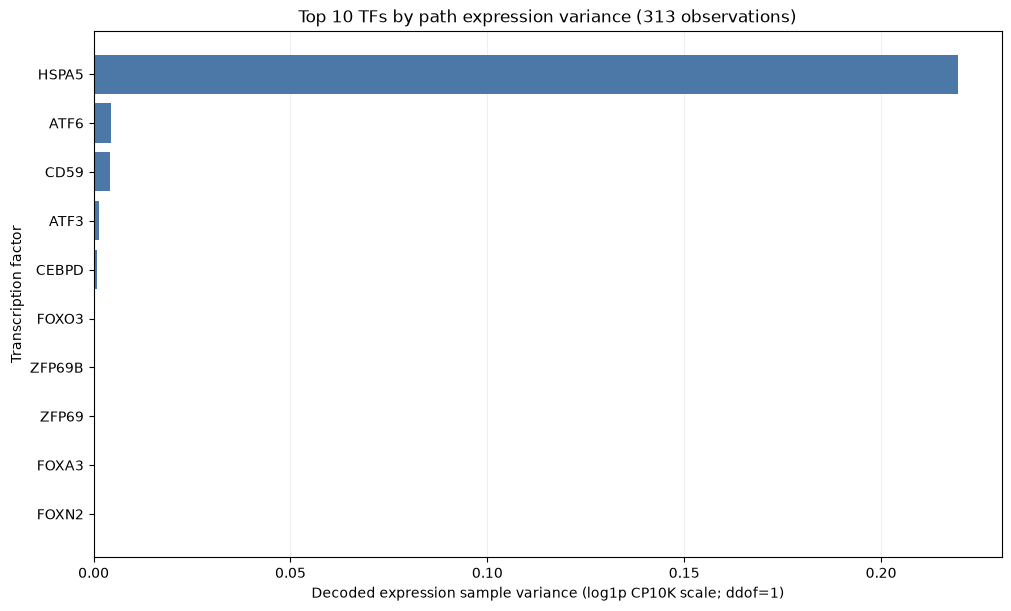

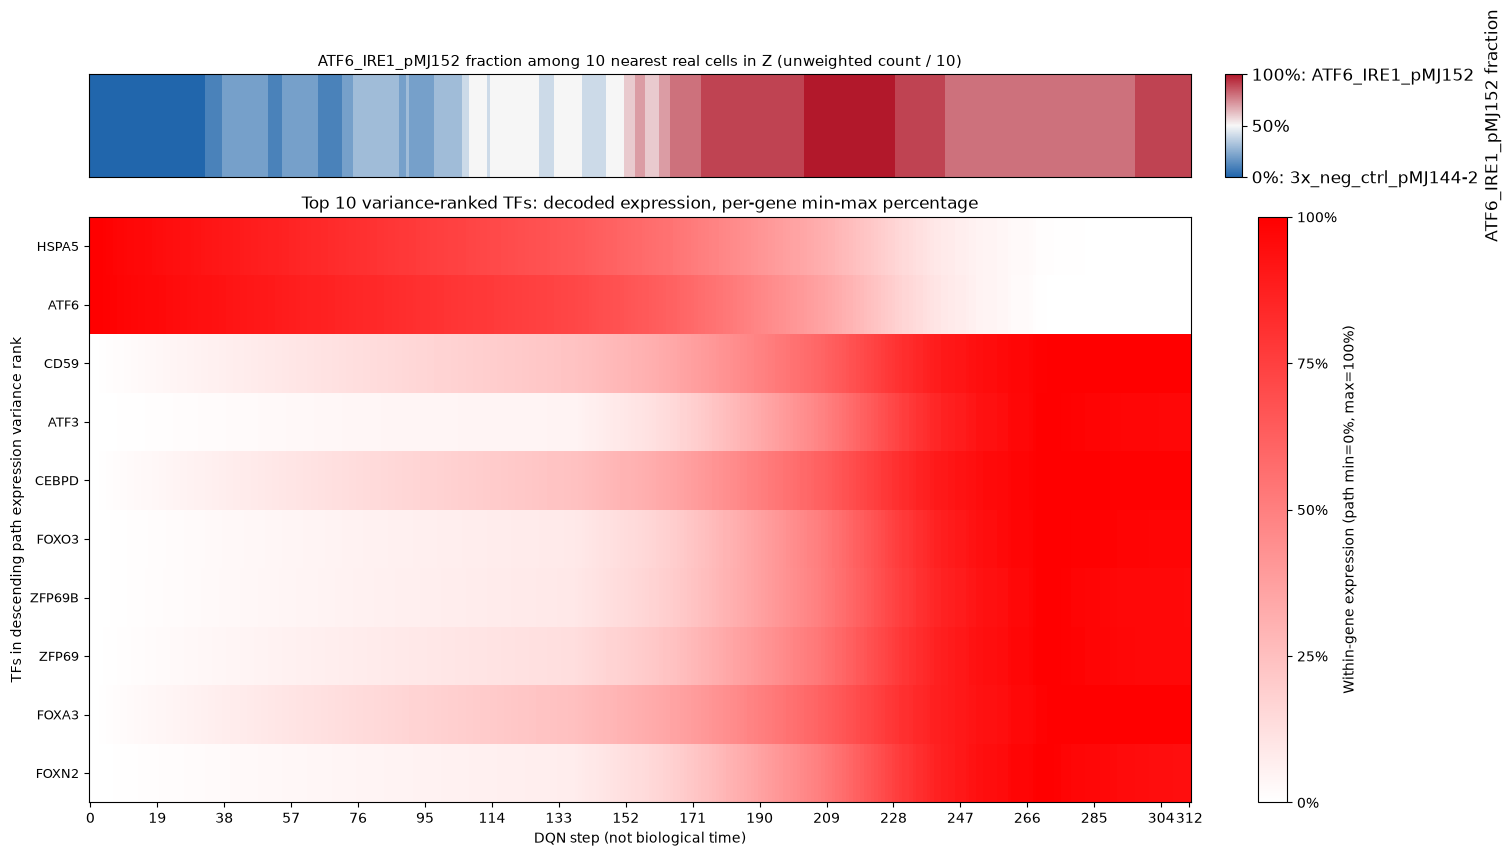

Validated 313 steps: direct latent decoding; per-gene min-max 0-100% display.
Top 10 TFs ranked among 173 decoder-available TFs by path expression variance (ddof=1).


,rank,TF,variance
0,1,HSPA5,0.219640
1,2,ATF6,0.004385
2,3,CD59,0.004045
3,4,ATF3,0.001252
4,5,CEBPD,0.000751
5,6,FOXO3,0.000392
6,7,ZFP69B,0.000114
7,8,ZFP69,0.000111
8,9,FOXA3,0.000089
9,10,FOXN2,0.000084


Saved decoded-expression heatmap and CSV to /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/coordinate_dqn


In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.neighbors import NearestNeighbors
import scanpy as sc

TF_RESULT_DIR = RESULT_ROOT / 'coordinate_dqn'
TF_VARIANCE_TOP_N = 10
tf_variance_symbols = pd.Index(TF_LIST_PATH.read_text().split())
tf_plot_path = pd.read_csv(TF_RESULT_DIR / 'dqn_trajectory.csv')
TF_ANNOTATION_K = 10
with np.load(TF_RESULT_DIR / 'coordinate_graph.npz', allow_pickle=False) as tf_plot_graph:
    tf_plot_cell_z = tf_plot_graph['Z_space'].copy()
    tf_plot_cell_barcodes = tf_plot_graph['cell_barcodes'].astype(str)
    tf_plot_saved_path_z = tf_plot_graph['coordinate_space'].copy()
tf_plot_latent_columns = [f'Z{dimension + 1}' for dimension in range(tf_plot_cell_z.shape[1])]
tf_plot_query = tf_plot_path[tf_plot_latent_columns].to_numpy(dtype=np.float32)
np.testing.assert_allclose(tf_plot_query, tf_plot_saved_path_z, atol=1e-6)
if not np.array_equal(tf_plot_path['step'].to_numpy(), np.arange(len(tf_plot_path))):
    raise ValueError('Expected consecutive DQN steps starting at zero.')

tf_decoder_checkpoint = torch.load(TF_RESULT_DIR / 'coordinate_models.pt', map_location='cpu', weights_only=False)
tf_decoder_symbols = np.asarray(tf_decoder_checkpoint['gene_symbols']).astype(str)
np.testing.assert_array_equal(tf_decoder_symbols, adata.var_names.to_numpy(dtype=str))
tf_decoder_reference_z = Z_space[:32].astype(np.float32)
with torch.no_grad():
    tf_decoder_reference_expression = vae.decoder(torch.from_numpy(tf_decoder_reference_z).to(DEVICE)).cpu().numpy()
if len(np.unique(tf_decoder_symbols)) != len(tf_decoder_symbols):
    raise ValueError('Decoder feature symbols must be unique.')
tf_decoder_state = {key.removeprefix('decoder.'): value for key, value in tf_decoder_checkpoint['vae'].items()
                    if key.startswith('decoder.')}
tf_path_decoder = nn.Sequential(
    nn.Linear(tf_decoder_state['0.weight'].shape[1], tf_decoder_state['0.weight'].shape[0]), nn.ReLU(),
    nn.Linear(tf_decoder_state['2.weight'].shape[1], tf_decoder_state['2.weight'].shape[0]), nn.ReLU(),
    nn.Linear(tf_decoder_state['4.weight'].shape[1], tf_decoder_state['4.weight'].shape[0]),
)
tf_path_decoder.load_state_dict(tf_decoder_state)
tf_path_decoder.eval().requires_grad_(False)
if len(tf_decoder_symbols) != tf_decoder_state['4.weight'].shape[0]:
    raise ValueError('Saved gene mapping does not match the original decoder output dimension.')
with torch.no_grad():
    np.testing.assert_allclose(tf_path_decoder(torch.from_numpy(tf_decoder_reference_z)).numpy(),
                               tf_decoder_reference_expression, rtol=1e-5, atol=1e-5)
    tf_path_decoded = np.concatenate([
        tf_path_decoder(torch.from_numpy(tf_plot_query[start:start + 256])).numpy()
        for start in range(0, len(tf_plot_query), 256)
    ])
if not np.isfinite(tf_path_decoded).all():
    raise ValueError('Non-finite decoded path expression.')
tf_variance_positions = np.flatnonzero(pd.Index(tf_decoder_symbols).isin(tf_variance_symbols))
if not len(tf_variance_positions):
    raise ValueError('No TF from allTFs_hg38.txt has an output in the original VAE decoder.')
if len(tf_plot_path) < 2:
    raise ValueError('Path expression sample variance requires at least two observations.')
tf_variance_expression = tf_path_decoded[:, tf_variance_positions].astype(np.float64)
tf_variance_scores = tf_variance_expression.var(axis=0, ddof=1)
tf_plot_ranking = pd.DataFrame({
    'TF': tf_decoder_symbols[tf_variance_positions],
    'variance': tf_variance_scores,
}).sort_values(['variance', 'TF'], ascending=[False, True], kind='stable').reset_index(drop=True)
if len(tf_plot_ranking) < TF_VARIANCE_TOP_N:
    raise ValueError(f'Expected at least {TF_VARIANCE_TOP_N} decoder-available TFs.')
tf_plot_ranking.insert(0, 'rank', np.arange(1, len(tf_plot_ranking) + 1))
tf_plot_top = tf_plot_ranking.head(TF_VARIANCE_TOP_N).copy()
tf_decoder_top = tf_plot_top.copy()
tf_plot_ranking.to_csv(TF_RESULT_DIR / 'dqn_path_tf_decoded_variance_ranking.csv', index=False)
tf_decoder_top_positions = pd.Index(tf_decoder_symbols).get_indexer(tf_decoder_top['TF'])
tf_heat_decoded_expression = tf_path_decoded[:, tf_decoder_top_positions].T
tf_heat_gene_min = tf_heat_decoded_expression.min(axis=1, keepdims=True)
tf_heat_gene_span = np.ptp(tf_heat_decoded_expression, axis=1, keepdims=True)
tf_heat_percentage = np.divide(tf_heat_decoded_expression - tf_heat_gene_min, tf_heat_gene_span,
                                out=np.zeros_like(tf_heat_decoded_expression), where=tf_heat_gene_span > 0) * 100
tf_heat_constant_genes = tf_decoder_top.loc[tf_heat_gene_span.ravel() == 0, 'TF'].tolist()
if tf_heat_constant_genes:
    print(f'Constant-expression TFs displayed as 0% (no within-gene variation): {tf_heat_constant_genes}')

tf_annotation_distances, tf_annotation_members = NearestNeighbors(n_neighbors=TF_ANNOTATION_K).fit(tf_plot_cell_z).kneighbors(tf_plot_query)
np.testing.assert_array_equal(tf_plot_cell_barcodes, adata.obs_names.to_numpy(dtype=str))
tf_plot_cell_types = adata.obs.loc[tf_plot_cell_barcodes, 'perturbation'].astype(str).to_numpy()
if not np.isin(tf_plot_cell_types, ['3x_neg_ctrl_pMJ144-2', 'ATF6_IRE1_pMJ152']).all():
    raise ValueError('Unexpected perturbation in the saved reference cells.')
tf_annotation_atf6_condition_count = (tf_plot_cell_types[tf_annotation_members] == 'ATF6_IRE1_pMJ152').sum(axis=1)
tf_annotation_atf6_condition_fraction = tf_annotation_atf6_condition_count / TF_ANNOTATION_K

fig, ax = plt.subplots(figsize=(10, max(6, 0.28 * len(tf_decoder_top))), constrained_layout=True)
tf_bar_order = tf_decoder_top.iloc[::-1]
ax.barh(tf_bar_order['TF'], tf_bar_order['variance'], color='#4C78A8')
ax.set(xlabel='Decoded expression sample variance (log1p CP10K scale; ddof=1)', ylabel='Transcription factor',
       title=f'Top {len(tf_decoder_top)} TFs by path expression variance ({len(tf_plot_path)} observations)')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.savefig(TF_RESULT_DIR / 'dqn_path_top_tf_variability.png', dpi=180, bbox_inches='tight')
plt.show()

tf_ratio_cmap = LinearSegmentedColormap.from_list('control_to_atf6_condition_ratio', ['#2166AC', '#F7F7F7', '#B2182B'])
fig, (type_ax, heat_ax) = plt.subplots(2, 1, figsize=(15, max(8, 0.28 * len(tf_decoder_top))),
                                      gridspec_kw={'height_ratios': [1.4, 8]}, sharex=True,
                                      constrained_layout=True)
type_image = type_ax.imshow(tf_annotation_atf6_condition_fraction[None, :], cmap=tf_ratio_cmap,
                           vmin=0, vmax=1, aspect='auto', interpolation='nearest')
type_ax.set_yticks([])
type_ax.tick_params(axis='x', bottom=False, labelbottom=False)
type_ax.set_title('ATF6_IRE1_pMJ152 fraction among 10 nearest real cells in Z (unweighted count / 10)', fontsize=11)
tf_ratio_colorbar = fig.colorbar(type_image, ax=type_ax, ticks=[0, 0.5, 1], fraction=0.08, pad=0.02, aspect=6)
tf_ratio_colorbar.ax.set_yticklabels(['0%: 3x_neg_ctrl_pMJ144-2', '50%', '100%: ATF6_IRE1_pMJ152'])
tf_ratio_colorbar.ax.tick_params(labelsize=12)
tf_ratio_colorbar.set_label('ATF6_IRE1_pMJ152 fraction', fontsize=12)
tf_expression_cmap = LinearSegmentedColormap.from_list('white_to_red', ['#FFFFFF', '#FF0000'])
heat_image = heat_ax.imshow(tf_heat_percentage, cmap=tf_expression_cmap, vmin=0, vmax=100,
                            aspect='auto', interpolation='nearest')
heat_ax.set_yticks(np.arange(len(tf_decoder_top)), labels=tf_decoder_top['TF'].tolist(), fontsize=9)
tick_steps = np.unique(np.r_[np.arange(0, len(tf_plot_path), max(1, len(tf_plot_path) // 16)), len(tf_plot_path) - 1])
heat_ax.set_xticks(tick_steps, labels=tick_steps)
heat_ax.set(xlabel='DQN step (not biological time)', ylabel='TFs in descending path expression variance rank')
heat_ax.set_title(f'Top {len(tf_decoder_top)} variance-ranked TFs: decoded expression, per-gene min-max percentage')
tf_expression_colorbar = fig.colorbar(heat_image, ax=heat_ax, ticks=[0, 25, 50, 75, 100],
                                    label='Within-gene expression (path min=0%, max=100%)')
tf_expression_colorbar.ax.set_yticklabels(['0%', '25%', '50%', '75%', '100%'])
fig.savefig(TF_RESULT_DIR / 'dqn_path_top_tf_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

tf_decoded_export = pd.DataFrame(tf_heat_decoded_expression.T, columns=tf_decoder_top['TF'].tolist(),
                                  index=pd.Index(tf_plot_path['step'], name='DQN_step'))
tf_decoded_export.to_csv(TF_RESULT_DIR / 'dqn_path_top_tf_decoded_expression.csv')
pd.DataFrame(tf_heat_percentage.T, columns=tf_decoder_top['TF'].tolist(),
             index=tf_decoded_export.index).to_csv(TF_RESULT_DIR / 'dqn_path_top_tf_decoded_percentage.csv')
pd.DataFrame({'step': tf_plot_path['step'], 'coordinate_id': tf_plot_path['coordinate_id'],
              'nearest10_ATF6/IRE1-condition_count': tf_annotation_atf6_condition_count,
              'nearest10_ATF6/IRE1-condition_fraction': tf_annotation_atf6_condition_fraction}).to_csv(
    TF_RESULT_DIR / 'dqn_path_decoded_tf_neighborhood10.csv', index=False)
np.testing.assert_allclose(type_image.get_array().data.ravel(), tf_annotation_atf6_condition_fraction)
np.testing.assert_allclose(heat_image.get_array().data, tf_heat_percentage)
print(f'Validated {len(tf_plot_path)} steps: direct latent decoding; per-gene min-max 0-100% display.')
print(f'Top {len(tf_decoder_top)} TFs ranked among {len(tf_plot_ranking)} decoder-available TFs by path expression variance (ddof=1).')
display(tf_plot_top)
print(f'Saved decoded-expression heatmap and CSV to {TF_RESULT_DIR}')

In [18]:
assert np.isfinite(tf_heat_decoded_expression).all()
assert tf_heat_decoded_expression.shape == (len(tf_decoder_top), len(tf_plot_path))
with torch.no_grad():
    tf_checked_decoded = tf_path_decoder(torch.from_numpy(tf_plot_query)).numpy()
np.testing.assert_allclose(tf_heat_decoded_expression,
                           tf_checked_decoded[:, tf_decoder_top_positions].T, rtol=1e-5, atol=1e-5)
np.testing.assert_allclose(heat_image.get_array().data, tf_heat_percentage)
np.testing.assert_allclose(type_image.get_array().data.ravel(), tf_annotation_atf6_condition_fraction)
assert heat_image.get_cmap().name == 'white_to_red'
np.testing.assert_allclose(heat_image.get_cmap()(0.0)[:3], [1, 1, 1])
np.testing.assert_allclose(heat_image.get_cmap()(1.0)[:3], [1, 0, 0])
np.testing.assert_allclose(heat_image.get_clim(), [0, 100])
np.testing.assert_allclose(tf_heat_percentage.min(axis=1), 0, atol=1e-5)
np.testing.assert_allclose(tf_heat_percentage.max(axis=1)[tf_heat_gene_span.ravel() > 0], 100, atol=1e-5)
assert tf_bar_order['TF'].tolist() == tf_decoder_top['TF'].iloc[::-1].tolist()
np.testing.assert_allclose([bar.get_width() for bar in ax.patches], tf_bar_order['variance'])
tf_saved_percentage = pd.read_csv(TF_RESULT_DIR / 'dqn_path_top_tf_decoded_percentage.csv', index_col='DQN_step')
assert tf_saved_percentage.columns.tolist() == tf_decoder_top['TF'].tolist()
np.testing.assert_array_equal(tf_saved_percentage.index, tf_plot_path['step'])
np.testing.assert_allclose(tf_saved_percentage.to_numpy().T, tf_heat_percentage, rtol=1e-6, atol=1e-5)
tf_expected_top = tf_plot_ranking.head(TF_VARIANCE_TOP_N)
pd.testing.assert_frame_equal(tf_plot_top, tf_expected_top)
assert tf_decoder_top['TF'].tolist() == tf_expected_top['TF'].tolist()
assert len(tf_decoder_top) == TF_VARIANCE_TOP_N == 10
assert tf_plot_ranking['TF'].is_unique and tf_plot_ranking['variance'].is_monotonic_decreasing
assert (tf_plot_ranking['variance'] >= 0).all()
tf_checked_variance = pd.DataFrame(tf_checked_decoded[:, tf_variance_positions].astype(np.float64),
                                   columns=tf_decoder_symbols[tf_variance_positions]).var(axis=0, ddof=1)
np.testing.assert_allclose(tf_plot_ranking['variance'], tf_checked_variance.loc[tf_plot_ranking['TF']], atol=1e-8)
tf_saved_ranking = pd.read_csv(TF_RESULT_DIR / 'dqn_path_tf_decoded_variance_ranking.csv')
pd.testing.assert_frame_equal(tf_saved_ranking, tf_plot_ranking, check_exact=False)
assert tf_annotation_members.shape == (len(tf_plot_path), TF_ANNOTATION_K)
assert all(len(np.unique(row)) == TF_ANNOTATION_K for row in tf_annotation_members)
np.testing.assert_array_equal(tf_annotation_atf6_condition_count,
    (tf_plot_cell_types[tf_annotation_members] == 'ATF6_IRE1_pMJ152').sum(axis=1))
np.testing.assert_allclose(tf_annotation_atf6_condition_fraction, tf_annotation_atf6_condition_count / 10)
np.testing.assert_allclose(tf_ratio_cmap(0.0)[:3], (33 / 255, 102 / 255, 172 / 255))
np.testing.assert_allclose(tf_ratio_cmap(1.0)[:3], (178 / 255, 24 / 255, 43 / 255))
tf_saved_decoded = pd.read_csv(TF_RESULT_DIR / 'dqn_path_top_tf_decoded_expression.csv', index_col='DQN_step')
assert tf_saved_decoded.columns.tolist() == tf_decoder_top['TF'].tolist()
np.testing.assert_array_equal(tf_saved_decoded.index, tf_plot_path['step'])
np.testing.assert_allclose(tf_saved_decoded.to_numpy().T, tf_heat_decoded_expression, rtol=1e-6, atol=1e-7)
tf_saved_annotation = pd.read_csv(TF_RESULT_DIR / 'dqn_path_decoded_tf_neighborhood10.csv')
np.testing.assert_array_equal(tf_saved_annotation['step'], tf_plot_path['step'])
np.testing.assert_array_equal(tf_saved_annotation['nearest10_ATF6/IRE1-condition_count'], tf_annotation_atf6_condition_count)
np.testing.assert_allclose(tf_saved_annotation['nearest10_ATF6/IRE1-condition_fraction'], tf_annotation_atf6_condition_fraction)
assert tf_saved_annotation['coordinate_id'].tolist() == tf_plot_path['coordinate_id'].tolist()
assert min(label.get_fontsize() for label in tf_ratio_colorbar.ax.get_yticklabels()) >= 12
assert type_ax.get_position().height >= 0.08
print('Validated: top 10 TF path expression variance descending (ddof=1); matching bar/heatmap gene order; per-gene 0-100% white-to-red heatmap and CSV; enlarged nearest-10 ATF6/IRE1-condition fraction legend.')

Validated: top 10 TF path expression variance descending (ddof=1); matching bar/heatmap gene order; per-gene 0-100% white-to-red heatmap and CSV; enlarged nearest-10 ATF6/IRE1-condition fraction legend.


## 14. 3x_neg-control shared-start KO DQN: ATF6↓ + IRE1(ERN1)↓ small-step walks, hierarchical branches

5–6번의 저장된 control PCA-median inverse-PCA 시작점과 고정 UMAP을 그대로 사용하며 endpoint는 지정하지 않습니다.
Action은 기존처럼 각 latent 축 ± 방향의 **관측 SD × 0.01** 이동입니다.

**동시 감소 보상**:
`r_t = 0.5 * [(ATF6_t - ATF6_next)/ATF6_start + (ERN1_t - ERN1_next)/ERN1_start]`.
각 target에 대해 도착 발현 ≥ 0이고 감소량이 `8 * dtype epsilon * max(abs(current), 1)`보다 커야 합니다.
한 유전자의 큰 감소로 다른 유전자의 상승을 상쇄하는 행동은 허용하지 않습니다.
Shannon entropy는 관찰용이며 보상에 포함하지 않습니다.

기존 q95 5th-NN support, 최대 500 moves, simulation-only 10-move 순변위 early stop,
독립 DQN 4개 × 12 rollouts, Ward hierarchical clustering / silhouette elbow / medoid branch 선택을 유지합니다.
모든 rollout에서 ATF6와 ERN1 동시 감소 및 실제 보상 일치를 검증하고 두 유전자의 궤적·학습 요약을 저장합니다.


Start = 3x_neg_ctrl_pMJ144-2 saved section 5–6 DQN start (UMAP=(8.166, 4.414)); ATF6=0.2112, H=4.0187 nats; actions=256; no endpoint.
Each action moves 0.01 SD. Max 500 moves; simulation early stop when 10-move net displacement <= 0.04 SD; only ATF6-and-ERN1-decreasing actions allowed.
Model 1 step 250: return=0.664, moves=168, no_supported_decreasing_action, ATF6 0.211->0.027, H 4.019->5.455 (56s)
Model 1 step 500: return=0.664, moves=168, no_supported_decreasing_action, ATF6 0.211->0.027, H 4.019->5.455 (117s)
Model 1 step 750: return=0.664, moves=168, no_supported_decreasing_action, ATF6 0.211->0.027, H 4.019->5.455 (182s)
Model 1 step 1000: return=0.664, moves=168, no_supported_decreasing_action, ATF6 0.211->0.027, H 4.019->5.455 (256s)
Model 1 step 1250: return=0.658, moves=403, no_supported_decreasing_action, ATF6 0.211->0.027, H 4.019->5.456 (335s)
Model 1 step 1500: return=0.625, moves=376, no_supported_decreasing_action, ATF6 0.211->0.039, H 4.019->5.408 (419s)
Model 2 step 25

,branch,n_simulations,fraction,representative_simulation,representative_model,representative_moves,representative_status,dominant_latent_axes,ATF6_start,ATF6_end_rep,ERN1_start,ERN1_end_rep,ERN1_end_cluster_mean,ATF6_end_cluster_mean,entropy_start,entropy_end_rep,entropy_end_cluster_mean,UMAP_endpoint_displacement,mean_moves
0,1,37,0.770833,25,3,171,no_supported_decreasing_action,"-Z77, -Z64, -Z74",0.211176,0.026715,0.044782,0.017174,0.017174,0.026719,4.018735,5.455108,5.455127,10.143626,172.135135
1,2,7,0.145833,41,4,185,no_supported_decreasing_action,"-Z77, -Z29, -Z64",0.211176,0.026704,0.044782,0.017172,0.017172,0.026718,4.018735,5.455103,5.455162,10.004984,188.000000
2,3,2,0.041667,37,4,204,no_supported_decreasing_action,"-Z77, -Z29, -Z64",0.211176,0.026655,0.044782,0.017170,0.017171,0.026668,4.018735,5.454963,5.455000,10.077672,199.500000
3,4,1,0.020833,40,4,224,no_supported_decreasing_action,"-Z77, -Z29, -Z74",0.211176,0.026650,0.044782,0.017168,0.017168,0.026650,4.018735,5.454998,5.454998,10.129575,224.000000
4,5,1,0.020833,36,4,282,no_supported_decreasing_action,"-Z77, -Z29, -Z3",0.211176,0.026513,0.044782,0.017162,0.017162,0.026513,4.018735,5.454630,5.454630,10.096188,282.000000


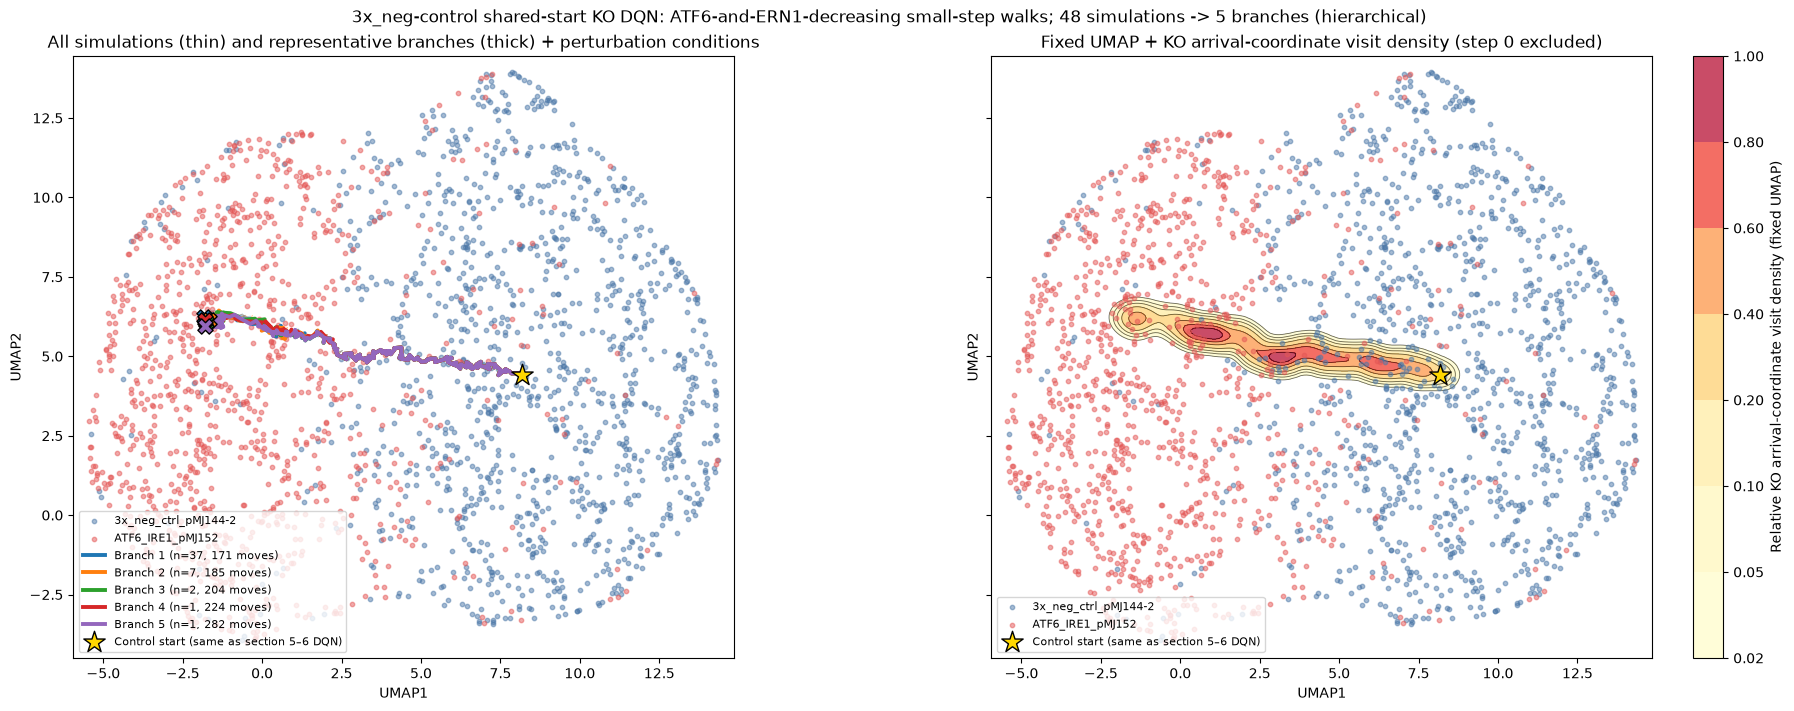

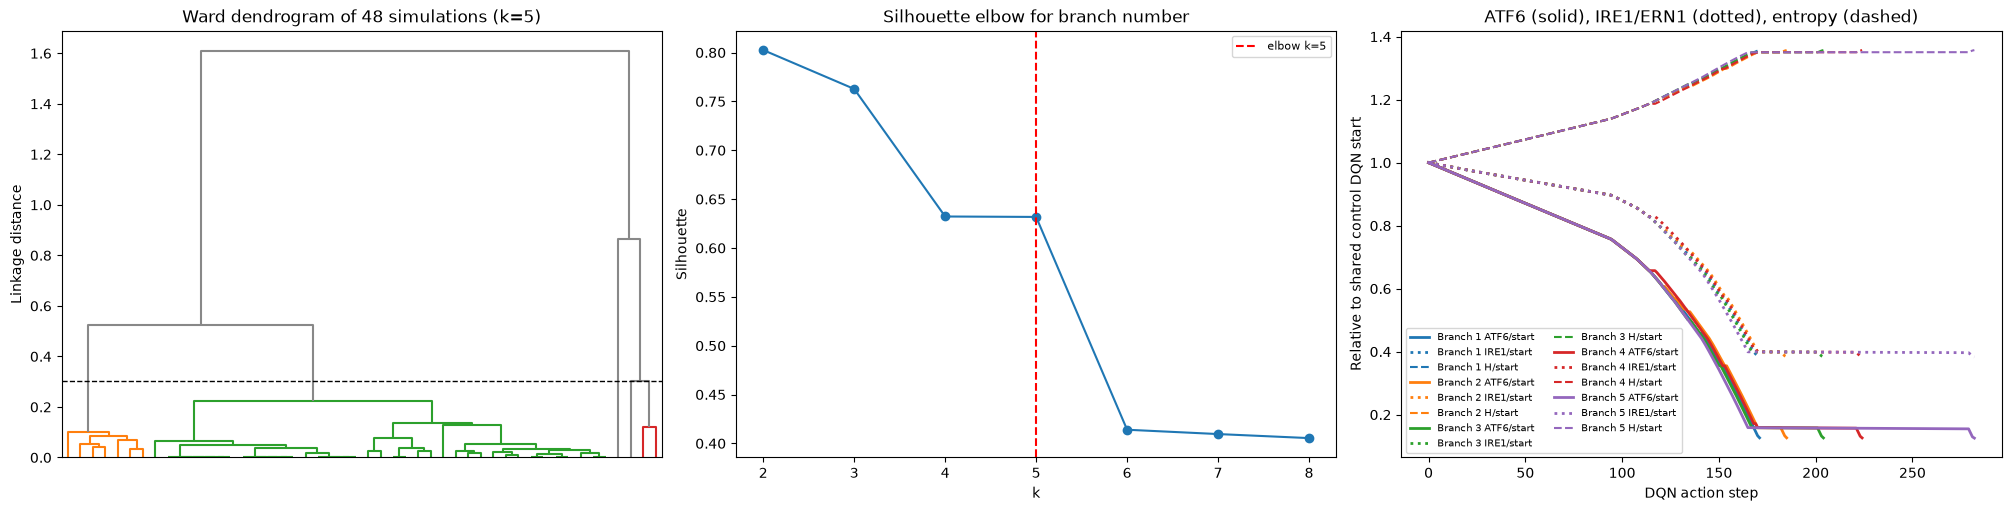

Saved branch policies, simulations, clustering and figures to /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/control_condition_double_ko_branch_dqn


Model 1 step 750: return=0.687, moves=91, no_supported_decreasing_action, ATF6 0.194->0.027, H 4.209->5.455 (250s)


Model 1 step 1000: return=0.687, moves=91, no_supported_decreasing_action, ATF6 0.194->0.027, H 4.209->5.455 (343s)


Model 1 step 1250: return=0.687, moves=91, no_supported_decreasing_action, ATF6 0.194->0.027, H 4.209->5.455 (439s)


Model 1 step 1500: return=0.687, moves=91, no_supported_decreasing_action, ATF6 0.194->0.027, H 4.209->5.455 (536s)


Model 2 step 250: return=0.650, moves=198, no_supported_decreasing_action, ATF6 0.194->0.034, H 4.209->5.429 (81s)


... (16 outputs left out)

Model 4 step 1500: return=0.687, moves=91, no_supported_decreasing_action, ATF6 0.194->0.027, H 4.209->5.455 (652s)


48 simulations -> 3 representative branches (Ward hierarchical clustering, silhouette elbow; silhouette by k: {2: 0.732, 3: 0.864, 4: 0.888, 5: 0.934, 6: 0.976, 7: 0.958}).


,branch,n_simulations,fraction,representative_simulation,representative_model,representative_moves,representative_status,dominant_latent_axes,ATF6_start,ATF6_end_rep,ERN1_start,ERN1_end_rep,ERN1_end_cluster_mean,ATF6_end_cluster_mean,entropy_start,entropy_end_rep,entropy_end_cluster_mean,UMAP_endpoint_displacement,mean_moves
0,1,30,0.625000,0,1,91,no_supported_decreasing_action,"-Z77, -Z1, -Z3",0.193662,0.026872,0.043126,0.017177,0.017177,0.026872,4.209065,5.454914,5.454914,6.999835,91.00
1,2,10,0.208333,21,2,92,no_supported_decreasing_action,"-Z77, -Z74, -Z1",0.193662,0.026876,0.043126,0.017177,0.017177,0.026878,4.209065,5.454932,5.454937,6.868313,92.30
2,3,8,0.166667,3,1,92,no_supported_decreasing_action,"-Z77, -Z74, -Z1",0.193662,0.026876,0.043126,0.017177,0.017177,0.026880,4.209065,5.454932,5.454946,6.868313,92.75


Saved branch policies, simulations, clustering and figures to /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/control_condition_double_ko_branch_dqn


In [19]:
from pathlib import Path
from copy import deepcopy
import json
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from scipy.ndimage import gaussian_filter
from sklearn.metrics import silhouette_score
from IPython.display import display

LG_ROOT = RESULT_ROOT
LG_DIR = LG_ROOT / 'control_condition_double_ko_branch_dqn'
LG_START_CONDITION = '3x_neg_ctrl_pMJ144-2'
LG_DIR.mkdir(parents=True, exist_ok=True)
LG_SEED = 20261028
LG_STRIDES = (1,)                   # one fixed small latent step per action (move distance is capped)
LG_STEP_FRACTION = 0.01             # each action moves 0.01 x observed SD of one latent axis
LG_SUPPORT_QUANTILE = 0.95
LG_ATF6_WEIGHT = 1.0
LG_REWARD_VERSION = 'atf6_ern1_joint_decrease_consistent_reference_v1'
LG_MAX_MOVES = 500                  # maximum moves per simulation
LG_MOVE_PATIENCE, LG_MOVE_FRACTION = 10, 0.40
LG_MOVE_MIN = LG_MOVE_PATIENCE * LG_STEP_FRACTION * max(LG_STRIDES) * LG_MOVE_FRACTION
LG_N_MODELS, LG_SIMS_PER_MODEL, LG_EPS_RANGE = 4, 12, (0.05, 0.30)
LG_N_ENVS, LG_VECTOR_STEPS, LG_BATCH, LG_GAMMA, LG_LR = 256, 1500, 1024, 0.999, 3e-4
LG_TARGET_SYNC, LG_EVAL_EVERY = 500, 250
LG_K_MAX, LG_ELBOW_GAIN_FRACTION, LG_ELBOW_DROP = 8, 0.25, 0.1
LG_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

with np.load(LG_ROOT / 'coordinate_dqn/coordinate_graph.npz', allow_pickle=False) as saved:
    lg_z = saved['Z_space'].astype(np.float32)
    lg_barcodes = saved['cell_barcodes'].astype(str)
    lg_observed_xy = saved['observed_umap'].astype(np.float32)
    lg_start_z = saved['z_start'].astype(np.float32)
    lg_saved_start_xy = saved['endpoint_umap'][0].astype(np.float32)
np.testing.assert_array_equal(lg_barcodes, adata.obs_names.to_numpy(dtype=str))
np.testing.assert_array_equal(lg_z, adata.obsm['X_z'])
np.testing.assert_array_equal(lg_observed_xy, adata.obsm['X_umap'])
np.testing.assert_array_equal(project_umap(lg_z), lg_observed_xy)
lg_types = adata.obs.loc[lg_barcodes, 'perturbation'].astype(str).to_numpy()
if not (lg_types == LG_START_CONDITION).any():
    raise ValueError(f'No {LG_START_CONDITION} cells found for the KO DQN start.')
lg_checkpoint = torch.load(LG_ROOT / 'coordinate_dqn/coordinate_models.pt', map_location='cpu', weights_only=False)
# Preserve the exported start projection even if the UMAP cache was rebuilt.
umap_projection_cache[lg_start_z.tobytes()] = lg_saved_start_xy.copy()
lg_start_xy = project_umap(lg_start_z[None])[0]
np.testing.assert_array_equal(lg_start_xy, lg_saved_start_xy)
lg_symbols = np.asarray(lg_checkpoint['gene_symbols']).astype(str)
lg_decoder = nn.Sequential(nn.Linear(lg_z.shape[1], 128), nn.ReLU(), nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, len(lg_symbols)))
lg_decoder.load_state_dict({k.removeprefix('decoder.'): v
                            for k, v in lg_checkpoint['vae'].items() if k.startswith('decoder.')})
lg_decoder = lg_decoder.to(LG_DEVICE).eval().requires_grad_(False)
if any(np.count_nonzero(lg_symbols == gene) != 1 for gene in KO_TARGETS):
    raise ValueError('Exactly one decoded output is required for ATF6 and ERN1.')
lg_target_indices = [int(np.flatnonzero(lg_symbols == gene)[0]) for gene in KO_TARGETS]
LG_ATF6_INDEX, LG_ERN1_INDEX = lg_target_indices
lg_dim = lg_z.shape[1]
lg_cells_t = torch.tensor(lg_z, device=LG_DEVICE)
lg_start_t = torch.tensor(lg_start_z, device=LG_DEVICE)


@torch.no_grad()
def lg_measure(z: torch.Tensor):
    flat = z.reshape(-1, lg_dim)
    entropy_parts, target_parts, support_parts = [], [], []
    for chunk in flat.split(1024):
        decoded = lg_decoder(chunk)
        linear = torch.expm1(decoded.double().clamp_min(0))
        totals = linear.sum(dim=1, keepdim=True)
        if not torch.isfinite(linear).all() or (totals <= 0).any():
            raise FloatingPointError('Joint-KO entropy requires finite nonzero decoded expression.')
        p = linear / totals
        entropy_parts.append(-torch.xlogy(p, p).sum(dim=1).float())
        target_parts.append(decoded[:, lg_target_indices])
        support_parts.append(torch.cdist(chunk, lg_cells_t).topk(5, largest=False).values[:, -1])
    shape = z.shape[:-1]
    return (torch.cat(entropy_parts).reshape(shape),
            torch.cat(target_parts).reshape(shape + (2,)),
            torch.cat(support_parts).reshape(shape))


lg_cell_entropy, lg_cell_target, _ = (v.cpu().numpy() for v in lg_measure(lg_cells_t))
with torch.no_grad():
    lg_cell_fifth = torch.cat([torch.cdist(chunk, lg_cells_t).topk(6, largest=False).values[:, -1]
                              for chunk in lg_cells_t.split(1024)])
lg_support_radius = float(torch.quantile(lg_cell_fifth, LG_SUPPORT_QUANTILE))
lg_h_mean, lg_h_scale = float(lg_cell_entropy.mean()), float(lg_cell_entropy.std(ddof=1))
if not np.isfinite(lg_h_scale) or lg_h_scale <= 0:
    raise ValueError('Decoded Shannon entropy scale must be finite and positive.')
start_h, start_pair, start_support = lg_measure(lg_start_t[None])
lg_start_h, lg_start_support = float(start_h[0]), float(start_support[0])
lg_start_pair = start_pair[0]
lg_start_target, lg_start_ire1 = lg_start_pair.cpu().tolist()
lg_f_scale = lg_start_pair.clone()
if not torch.isfinite(lg_f_scale).all() or (lg_f_scale <= 0).any():
    raise ValueError('Both decoded control-start targets must be finite and positive.')
lg_axis_step = torch.tensor(LG_STEP_FRACTION * lg_z.std(axis=0), device=LG_DEVICE)
lg_directions = torch.cat([torch.diag(lg_axis_step), -torch.diag(lg_axis_step)])        # (32, 16)
lg_direction_names = [f'{sign}Z{i + 1}' for sign in '+-' for i in range(lg_dim)]
lg_n_dir, lg_max_stride = len(lg_directions), max(LG_STRIDES)
LG_N_ACTIONS = lg_n_dir * len(LG_STRIDES)
lg_action_names = [f'{name} x{stride}' for stride in LG_STRIDES for name in lg_direction_names]
lg_substep_index = torch.arange(1, lg_max_stride + 1, device=LG_DEVICE, dtype=torch.float32)
lg_diversity_scale = float(np.quantile(np.linalg.norm(lg_z - lg_z.mean(axis=0), axis=1), .95))
lg_feature_mean = torch.tensor(lg_z.mean(axis=0), device=LG_DEVICE)
lg_feature_scale = torch.tensor(lg_z.std(axis=0), device=LG_DEVICE).clamp_min(1e-6)
lg_z_sd = lg_z.std(axis=0)


@torch.no_grad()
def lg_candidates(z: torch.Tensor, current_target: torch.Tensor):
    """Each action lands after `stride` sub-steps; every sub-step must stay inside the observed-cell support."""
    sub = z[:, None, None] + lg_substep_index[None, None, :, None] * lg_directions[None, :, None]   # (B, 32, 4, 16)
    entropy, target, support = lg_measure(sub)
    # Compare against the recorded state, not a batch-size-dependent decoder reevaluation.
    out = {'z': [], 'h': [], 'f': [], 's': [], 'valid': []}
    for stride in LG_STRIDES:
        out['z'].append(sub[:, :, stride - 1]); out['h'].append(entropy[:, :, stride - 1])
        out['f'].append(target[:, :, stride - 1]); out['s'].append(support[:, :, stride - 1])
        arrival_target = target[:, :, stride - 1]
        out['valid'].append((support[:, :, :stride] <= lg_support_radius).all(dim=2)
                            & joint_decrease(current_target[:, None], arrival_target))
    return {key: torch.cat(value, dim=1) for key, value in out.items()}


@torch.no_grad()
def lg_features(z, f, h, t):
    return torch.cat([(z - lg_feature_mean) / lg_feature_scale, (z - lg_start_t) / lg_feature_scale,
                      (f / lg_f_scale), ((h - lg_h_mean) / lg_h_scale)[:, None],
                      ((z - lg_start_t).norm(dim=1) / lg_diversity_scale)[:, None],
                      (t.float() / LG_MAX_MOVES)[:, None]], dim=1)


@torch.no_grad()
def lg_reward(f, f_next):
    return joint_reward(f, f_next, lg_f_scale)


_probe = lg_candidates(lg_start_t[None], lg_start_pair[None])
if not bool(_probe['valid'].any()):
    raise ValueError(f'No supported ATF6-and-ERN1-decreasing action from the {LG_START_CONDITION} shared DQN start.')
print(f'Start = {LG_START_CONDITION} saved section 5–6 DQN start (UMAP=({lg_start_xy[0]:.3f}, {lg_start_xy[1]:.3f})); '
      f'ATF6={lg_start_target:.4f}, H={lg_start_h:.4f} nats; actions={LG_N_ACTIONS}; no endpoint.')
print(f'Each action moves {LG_STEP_FRACTION} SD. Max {LG_MAX_MOVES} moves; simulation early stop when '
      f'{LG_MOVE_PATIENCE}-move net displacement <= {LG_MOVE_MIN:g} SD; only ATF6-and-ERN1-decreasing actions allowed.')


class LgTracker:
    def __init__(self, z0):
        self.size = LG_MOVE_PATIENCE + 1
        self.hist = z0[None].repeat(self.size, 1, 1)

    def update(self, idx, t, z):
        self.hist[t % self.size, idx] = z
        past = self.hist[(t - LG_MOVE_PATIENCE) % self.size, idx]
        net = ((z - past) / lg_feature_scale).norm(dim=1)
        return (t >= LG_MOVE_PATIENCE) & (net <= LG_MOVE_MIN)


class LongRangeLatentQ(nn.Module):
    def __init__(self, features, actions):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(features, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(),
                                     nn.Linear(256, actions))

    def forward(self, features):
        return self.network(features)


@torch.no_grad()
def lg_simulate(model, epsilons, seed):
    """Simulations from the saved section 5–6 start; epsilon injects action diversity (0 = greedy)."""
    eps = torch.tensor(epsilons, dtype=torch.float32, device=LG_DEVICE)
    count = len(eps)
    generator = torch.Generator(device=LG_DEVICE).manual_seed(seed)
    z = lg_start_t[None].repeat(count, 1)
    f = lg_start_pair[None].repeat(count, 1)
    h = torch.full((count,), lg_start_h, device=LG_DEVICE)
    t = torch.zeros(count, dtype=torch.long, device=LG_DEVICE)
    tracker = LgTracker(z)
    shape = (LG_MAX_MOVES + 1, count)
    paths = np.full(shape + (lg_dim,), np.nan, np.float32); paths[0] = lg_start_z
    target_hist = np.full(shape + (2,), np.nan, np.float32)
    h_hist, sup_hist = (np.full(shape, np.nan, np.float32) for _ in range(2))
    target_hist[0], h_hist[0], sup_hist[0] = lg_start_pair.cpu().numpy(), lg_start_h, lg_start_support
    rewards = np.zeros((LG_MAX_MOVES, count), np.float32)
    actions = np.full((LG_MAX_MOVES, count), -1, np.int64)
    lengths = np.zeros(count, dtype=np.int64)
    status = ['maximum_moves'] * count
    active = torch.ones(count, dtype=torch.bool, device=LG_DEVICE)
    candidates = lg_candidates(z, f)
    for _ in range(LG_MAX_MOVES):
        idx = active.nonzero().squeeze(1)
        if not len(idx):
            break
        c = {key: value[idx] for key, value in candidates.items()}
        valid = c['valid']
        dead = ~valid.any(dim=1)
        q = model(lg_features(z[idx], f[idx], h[idx], t[idx])).masked_fill(~valid, -torch.inf)
        safe = valid | dead[:, None]
        random_action = torch.multinomial(safe.float(), 1, generator=generator).squeeze(1)
        use_random = torch.rand(len(idx), device=LG_DEVICE, generator=generator) < eps[idx]
        action = torch.where(use_random, random_action, q.argmax(dim=1))
        for row in dead.nonzero().squeeze(1).tolist():
            status[int(idx[row])] = 'no_supported_decreasing_action'
        active[idx[dead]] = False
        keep = ~dead
        if not keep.any():
            continue
        idx, action = idx[keep], action[keep]
        rows = torch.arange(len(idx), device=LG_DEVICE)
        zn, fn, hn, sn = (c[key][keep][rows, action] for key in ('z', 'f', 'h', 's'))
        next_candidates = lg_candidates(zn, fn)
        no_action = ~next_candidates['valid'].any(dim=1)
        finished = no_action | (t[idx] + 1 >= LG_MAX_MOVES)
        reward = lg_reward(f[idx], fn)
        for key in candidates:
            candidates[key][idx] = next_candidates[key]
        z[idx], f[idx], h[idx] = zn, fn, hn
        t[idx] += 1
        converged = tracker.update(idx, t[idx], zn)
        finished |= converged
        step_numbers, index_np = t[idx].cpu().numpy(), idx.cpu().numpy()
        paths[step_numbers, index_np] = zn.cpu().numpy()
        target_hist[step_numbers, index_np], h_hist[step_numbers, index_np] = fn.cpu().numpy(), hn.cpu().numpy()
        sup_hist[step_numbers, index_np] = sn.cpu().numpy()
        rewards[step_numbers - 1, index_np] = reward.cpu().numpy()
        actions[step_numbers - 1, index_np] = action.cpu().numpy()
        lengths[index_np] = step_numbers
        for row in finished.nonzero().squeeze(1).tolist():
            status[int(idx[row])] = ('no_supported_decreasing_action' if bool(no_action[row]) else
                                     'early_stop_low_movement' if bool(converged[row]) else 'maximum_moves')
        active[idx[finished]] = False
    results = []
    for b in range(count):
        n = int(lengths[b])
        results.append({'path': paths[:n + 1, b], 'target': target_hist[:n + 1, b, 0], 'ire1': target_hist[:n + 1, b, 1], 'entropy': h_hist[:n + 1, b],
                        'support': sup_hist[:n + 1, b], 'actions': actions[:n, b], 'rewards': rewards[:n, b],
                        'status': status[b], 'epsilon': float(eps[b]),
                        'score': float(np.sum(rewards[:n, b] * LG_GAMMA ** np.arange(n)))})
    return results


@torch.no_grad()
def lg_reset(count, generator):
    # Half use the shared DQN start; half use supported measured cells with ATF6 >= 0 (exploration).
    eligible = torch.tensor(np.flatnonzero((lg_cell_target >= 0).all(axis=1)), device=LG_DEVICE)
    z = lg_cells_t[eligible[torch.randint(len(eligible), (count,), device=LG_DEVICE, generator=generator)]].clone()
    z[torch.rand(count, device=LG_DEVICE, generator=generator) < 0.5] = lg_start_t
    h, f, _ = lg_measure(z)
    return z, f, h


def lg_train(model_index):
    seed = LG_SEED + model_index
    torch.manual_seed(seed)
    generator = torch.Generator(device=LG_DEVICE).manual_seed(seed)
    n_features = 2 * lg_dim + 5
    model = LongRangeLatentQ(n_features, LG_N_ACTIONS).to(LG_DEVICE)
    target = deepcopy(model).eval()
    optimizer = torch.optim.Adam(model.parameters(), lr=LG_LR)
    capacity = LG_N_ENVS * LG_VECTOR_STEPS
    buffer = {'f': torch.empty(capacity, n_features, device=LG_DEVICE), 'n': torch.empty(capacity, n_features, device=LG_DEVICE),
              'm': torch.empty(capacity, LG_N_ACTIONS, dtype=torch.bool, device=LG_DEVICE),
              'a': torch.empty(capacity, dtype=torch.long, device=LG_DEVICE),
              'r': torch.empty(capacity, device=LG_DEVICE), 'd': torch.empty(capacity, dtype=torch.bool, device=LG_DEVICE)}
    z, f, h = lg_reset(LG_N_ENVS, generator)
    t = torch.zeros(LG_N_ENVS, dtype=torch.long, device=LG_DEVICE)
    all_envs = torch.arange(LG_N_ENVS, device=LG_DEVICE)
    candidates = lg_candidates(z, f)
    count, updates, log = 0, 0, []
    best_score, best_weights, started = -np.inf, None, time.time()
    for vector_step in range(1, LG_VECTOR_STEPS + 1):
        dead = ~candidates['valid'].any(dim=1)
        reset_attempts = 0
        while dead.any():
            reset_attempts += 1
            if reset_attempts > 100:
                raise RuntimeError('No supported ATF6-and-ERN1-decreasing branch-DQN reset after 100 attempts.')
            z[dead], f[dead], h[dead] = lg_reset(int(dead.sum()), generator)
            t[dead] = 0
            candidates = lg_candidates(z, f)
            dead = ~candidates['valid'].any(dim=1)
        features, valid = lg_features(z, f, h, t), candidates['valid']
        epsilon = max(0.05, 1.0 - vector_step / (0.6 * LG_VECTOR_STEPS))
        greedy = model(features).masked_fill(~valid, -torch.inf).argmax(dim=1)
        random_actions = torch.multinomial(valid.float(), 1, generator=generator).squeeze(1)
        actions = torch.where(torch.rand(LG_N_ENVS, device=LG_DEVICE, generator=generator) < epsilon, random_actions, greedy)
        zn, fn, hn = (candidates[key][all_envs, actions] for key in ('z', 'f', 'h'))
        next_candidates = lg_candidates(zn, fn)
        next_valid = next_candidates['valid']
        terminal = ~next_valid.any(dim=1) | (t + 1 >= LG_MAX_MOVES)
        reward = lg_reward(f, fn)
        z, f, h, t = zn.clone(), fn.clone(), hn.clone(), t + 1
        slots = torch.arange(count, count + LG_N_ENVS, device=LG_DEVICE)
        buffer['f'][slots], buffer['n'][slots], buffer['m'][slots] = features, lg_features(z, f, h, t), next_valid
        buffer['a'][slots], buffer['r'][slots], buffer['d'][slots] = actions, reward, terminal
        count += LG_N_ENVS
        reset = terminal
        if reset.any():
            z[reset], f[reset], h[reset] = lg_reset(int(reset.sum()), generator)
            t[reset] = 0
            next_candidates = lg_candidates(z, f)
        candidates = next_candidates
        if count >= 4 * LG_BATCH:
            for _ in range(2):
                batch = torch.randint(count, (LG_BATCH,), device=LG_DEVICE, generator=generator)
                prediction = model(buffer['f'][batch]).gather(1, buffer['a'][batch, None]).squeeze(1)
                with torch.no_grad():
                    next_mask = buffer['m'][batch]
                    next_action = model(buffer['n'][batch]).masked_fill(~next_mask, -torch.inf).argmax(dim=1)
                    next_q = target(buffer['n'][batch]).gather(1, next_action[:, None]).squeeze(1)
                    next_q = torch.where(next_mask.any(dim=1), next_q, torch.zeros_like(next_q))
                    expected = buffer['r'][batch] + LG_GAMMA * next_q * (~buffer['d'][batch]).float()
                loss = nn.functional.smooth_l1_loss(prediction, expected)
                if not torch.isfinite(loss):
                    raise FloatingPointError('Non-finite DQN loss.')
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.)
                optimizer.step()
                updates += 1
                if updates % LG_TARGET_SYNC == 0:
                    target.load_state_dict(model.state_dict())
        if vector_step % LG_EVAL_EVERY == 0 and updates:
            model.eval()
            result = lg_simulate(model, [0.0], seed)[0]
            model.train()
            log.append({'model': model_index, 'vector_step': vector_step, 'updates': updates, 'epsilon': epsilon,
                        'greedy_return': result['score'], 'moves': len(result['actions']), 'status': result['status'],
                        'ATF6_end': float(result['target'][-1]), 'ERN1_end': float(result['ire1'][-1]), 'entropy_end': float(result['entropy'][-1])})
            if result['score'] > best_score:
                best_score, best_weights = result['score'], deepcopy(model.state_dict())
            print(f'Model {model_index} step {vector_step}: return={result["score"]:.3f}, moves={len(result["actions"])}, '
                  f'{result["status"]}, ATF6 {lg_start_target:.3f}->{result["target"][-1]:.3f}, '
                  f'H {lg_start_h:.3f}->{result["entropy"][-1]:.3f} ({time.time() - started:.0f}s)', flush=True)
    if best_weights is None:
        raise RuntimeError(f'Model {model_index}: no evaluation checkpoint was produced.')
    model.load_state_dict(best_weights)
    return model.eval(), pd.DataFrame(log)


lg_models, lg_logs = [], []
for model_index in range(1, LG_N_MODELS + 1):
    model, log = lg_train(model_index)
    lg_models.append(model); lg_logs.append(log)

# Many simulations: one greedy rollout + epsilon-diversified rollouts per independently trained DQN.
lg_sims, lg_sim_model = [], []
for model_index, model in enumerate(lg_models, start=1):
    epsilons = [0.0] + list(np.linspace(*LG_EPS_RANGE, LG_SIMS_PER_MODEL - 1))
    for result in lg_simulate(model, epsilons, LG_SEED + 100 * model_index):
        lg_sims.append(result); lg_sim_model.append(model_index)
lg_n_sims = len(lg_sims)
for result in lg_sims:
    assert len(result['actions']) >= 1 and np.allclose(result['path'][0], lg_start_z)
    assert len(result['actions']) <= LG_MAX_MOVES
    assert np.all(result['support'][1:] <= lg_support_radius + 1e-6)
    pairs = torch.tensor(np.column_stack([result['target'], result['ire1']]))
    assert joint_decrease(pairs[:-1], pairs[1:]).all()
    np.testing.assert_allclose(result['rewards'], joint_reward(pairs[:-1], pairs[1:], lg_f_scale.cpu()).numpy(), rtol=3e-4, atol=1e-7)


def lg_signature(result, phases=3):
    # Net signed latent displacement per axis (in observed SD) for early / middle / late thirds of the simulation.
    path = result['path']
    edges = np.linspace(0, len(path) - 1, phases + 1).round().astype(int)
    return np.concatenate([(path[edges[i + 1]] - path[edges[i]]) / lg_z_sd for i in range(phases)])


lg_signatures = np.stack([lg_signature(result) for result in lg_sims])
lg_linkage = linkage(lg_signatures, method='ward')
lg_k_scores = {}
for k in range(2, min(LG_K_MAX, lg_n_sims - 1) + 1):
    labels_k = fcluster(lg_linkage, k, criterion='maxclust')
    if len(np.unique(labels_k)) == k:
        lg_k_scores[k] = float(silhouette_score(lg_signatures, labels_k))
# Silhouette-based elbow: keep the largest k reached before the silhouette collapses (largest drop); if it never drops,
# fall back to the first k whose next silhouette gain is below a fraction of the largest gain.
lg_k_values = sorted(lg_k_scores)
lg_k_gains = {k: lg_k_scores[k] - lg_k_scores[k - 1] for k in lg_k_values[1:]}
lg_gain_threshold = LG_ELBOW_GAIN_FRACTION * max(max(lg_k_gains.values()), 0.0) if lg_k_gains else 0.0
if lg_k_gains and min(lg_k_gains.values()) < -LG_ELBOW_DROP:
    lg_best_k = min(lg_k_gains, key=lg_k_gains.get) - 1
else:
    lg_best_k = next((k for k in lg_k_values if k + 1 in lg_k_gains and lg_k_gains[k + 1] < lg_gain_threshold), lg_k_values[-1] if lg_k_values else 1)
lg_labels = fcluster(lg_linkage, lg_best_k, criterion='maxclust') if lg_best_k > 1 else np.ones(lg_n_sims, dtype=int)
lg_distance_matrix = squareform(pdist(lg_signatures))
lg_cluster_ids = np.unique(lg_labels)
lg_medoids = {}
for cluster in lg_cluster_ids:
    members = np.flatnonzero(lg_labels == cluster)
    lg_medoids[cluster] = int(members[lg_distance_matrix[np.ix_(members, members)].sum(axis=1).argmin()])
lg_cluster_ids = sorted(lg_cluster_ids, key=lambda c: -(lg_labels == c).sum())      # branch 1 = largest cluster
lg_branch_of_cluster = {c: i + 1 for i, c in enumerate(lg_cluster_ids)}
lg_branch_labels = np.array([lg_branch_of_cluster[c] for c in lg_labels])
print(f'{lg_n_sims} simulations -> {lg_best_k} representative branches (Ward hierarchical clustering, silhouette elbow; silhouette by k: { {k: round(v, 3) for k, v in lg_k_scores.items()} }).')

lg_sim_table = pd.DataFrame({
    'simulation': np.arange(lg_n_sims), 'model': lg_sim_model, 'epsilon': [r['epsilon'] for r in lg_sims],
    'branch': lg_branch_labels, 'moves': [len(r['actions']) for r in lg_sims], 'status': [r['status'] for r in lg_sims],
    'ATF6_end': [float(r['target'][-1]) for r in lg_sims],
    'ERN1_end': [float(r['ire1'][-1]) for r in lg_sims], 'entropy_end': [float(r['entropy'][-1]) for r in lg_sims],
    'discounted_return': [r['score'] for r in lg_sims],
    'is_representative': [i == lg_medoids[c] for i, c in enumerate(lg_labels)]})
lg_sim_table.to_csv(LG_DIR / 'simulation_summary.csv', index=False)


def lg_top_axes(members, count=3):
    mean_signature = lg_signatures[members].reshape(len(members), 3, lg_dim).sum(axis=1).mean(axis=0)
    order = np.argsort(-np.abs(mean_signature))[:count]
    return ', '.join(f'{"+" if mean_signature[i] > 0 else "-"}Z{i + 1}' for i in order)


for result in lg_sims:
    result['umap'] = project_umap(result['path'])
lg_branch_rows, lg_representatives = [], []
for cluster in lg_cluster_ids:
    branch = lg_branch_of_cluster[cluster]
    members = np.flatnonzero(lg_labels == cluster)
    medoid = lg_medoids[cluster]
    result = lg_sims[medoid]
    lg_representatives.append((branch, medoid, result))
    path, actions = result['path'], result['actions']
    xy = result['umap']
    atf6_reward = 0.5 * ((result['target'][:-1] - result['target'][1:]) / lg_start_target
                          + (result['ire1'][:-1] - result['ire1'][1:]) / lg_start_ire1)
    bad_moves = np.flatnonzero((np.diff(result['target']) >= 0) | (np.diff(result['ire1']) >= 0))
    if len(bad_moves):
        move = int(bad_moves[0])
        raise ValueError(f'Branch {branch}, move {move + 1}: decoded ATF6 and ERN1 did not both decrease '
                         f'({result["target"][move]:.12g} -> {result["target"][move + 1]:.12g}).')
    np.testing.assert_allclose(result['rewards'], atf6_reward, atol=3e-4, rtol=3e-4)
    frame = pd.DataFrame({'step': np.arange(len(path)), 'decoded_ATF6': result['target'], 'decoded_ERN1': result['ire1'], 'decoded_entropy_nats': result['entropy'],
                          'UMAP1': xy[:, 0], 'UMAP2': xy[:, 1], 'support_distance_k5': result['support'],
                          'chosen_action': [lg_action_names[a] for a in actions] + [''],
                          'reward_to_next': np.r_[result['rewards'], np.nan],
                          'joint_reward_to_next': np.r_[atf6_reward, np.nan]})
    frame = pd.concat([frame, pd.DataFrame(path, columns=[f'Z{i + 1}' for i in range(lg_dim)])], axis=1)
    frame.to_csv(LG_DIR / f'branch{branch}_trajectory.csv', index=False)
    lg_branch_rows.append({
        'branch': branch, 'n_simulations': len(members), 'fraction': len(members) / lg_n_sims,
        'representative_simulation': medoid, 'representative_model': lg_sim_model[medoid],
        'representative_moves': len(actions), 'representative_status': result['status'],
        'dominant_latent_axes': lg_top_axes(members),
        'ATF6_start': lg_start_target, 'ATF6_end_rep': float(result['target'][-1]),
        'ERN1_start': lg_start_ire1, 'ERN1_end_rep': float(result['ire1'][-1]),
        'ERN1_end_cluster_mean': float(lg_sim_table.loc[members, 'ERN1_end'].mean()),
        'ATF6_end_cluster_mean': float(lg_sim_table.loc[members, 'ATF6_end'].mean()),
        'entropy_start': lg_start_h, 'entropy_end_rep': float(result['entropy'][-1]),
        'entropy_end_cluster_mean': float(lg_sim_table.loc[members, 'entropy_end'].mean()),
        'UMAP_endpoint_displacement': float(np.linalg.norm(xy[-1] - lg_start_xy)),
        'mean_moves': float(lg_sim_table.loc[members, 'moves'].mean())})
lg_branch_df = pd.DataFrame(lg_branch_rows)
lg_branch_df.to_csv(LG_DIR / 'branch_summary.csv', index=False)
pd.concat(lg_logs, ignore_index=True).to_csv(LG_DIR / 'training_history.csv', index=False)
torch.save({'models': [m.state_dict() for m in lg_models], 'directions': lg_directions.cpu(),
            'strides': LG_STRIDES, 'action_names': lg_action_names}, LG_DIR / 'branch_models.pt')
lg_lengths = np.array([len(r['actions']) for r in lg_sims])
lg_padded = np.full((lg_n_sims, lg_lengths.max() + 1, lg_dim), np.nan, np.float32)
lg_umap_padded = np.full((lg_n_sims, lg_lengths.max() + 1, 2), np.nan, np.float32)
for i, result in enumerate(lg_sims):
    lg_padded[i, :len(result['path'])] = result['path']
    lg_umap_padded[i, :len(result['path'])] = result['umap']
np.savez_compressed(LG_DIR / 'simulation_paths.npz', paths=lg_padded, umap_paths=lg_umap_padded, lengths=lg_lengths, branch=lg_branch_labels,
                    signatures=lg_signatures, linkage=lg_linkage, start_z=lg_start_z,
                    representative_index=np.array([m for _, m, _ in lg_representatives]),
                    representative_branch=np.array([b for b, _, _ in lg_representatives]),
                    target_symbols=np.array(KO_TARGETS),
                    target_paths=np.stack([np.pad(np.column_stack([r['target'], r['ire1']]),
                        ((0, int(lg_lengths.max()) + 1 - len(r['target'])), (0, 0)), constant_values=np.nan)
                        for r in lg_sims]))
(LG_DIR / 'run_metadata.json').write_text(json.dumps({
    'state_space': 'continuous virtual latent coordinates generated by actions (no coordinate graph, not cells)',
    'display_space': 'fixed UMAP from section 4', 'umap_model_path': str(UMAP_MODEL_PATH),
    'start': f'{LG_START_CONDITION}: saved section 5–6 z_start (inverse PCA of control PCA median)',
    'start_definition': 'section_5_6_saved_z_start',
    'start_condition': LG_START_CONDITION, 'start_latent': lg_start_z.tolist(),
    'start_umap': lg_start_xy.tolist(), 'endpoint': None,
    'density': 'arrival-coordinate visits (steps >= 1), including repeated visits, on the fixed UMAP',
    'actions': f'+/- each of {lg_dim} latent axes x strides {list(LG_STRIDES)} = {LG_N_ACTIONS}',
    'base_substep': f'{LG_STEP_FRACTION} x observed SD per latent axis',
    'support_constraint': f'every sub-step 5th-NN observed-cell distance <= {lg_support_radius:.6g} (q{LG_SUPPORT_QUANTILE}); 0 <= arrival ATF6 < current ATF6 AND arrival ERN1 < current ERN1',
    'reward_version': LG_REWARD_VERSION,
    'decrease_check': 'arrival versus recorded current ATF6 and ERN1; each reduction > 8 * dtype epsilon * max(abs(current), 1)',
    'reward': 'mean([(ATF6_t-ATF6_next)/ATF6_start, (ERN1_t-ERN1_next)/ERN1_start])',
    'gamma': LG_GAMMA, 'state_features': 'latent, shared-start displacement, ATF6, ERN1, observational entropy, radius, elapsed fraction',
    'weights': {'ATF6': 0.5, 'ERN1': 0.5}, 'H_scale': lg_h_scale, 'target_scales': lg_f_scale.cpu().tolist(), 'target_symbols': KO_TARGETS,
    'entropy': 'Shannon H of decoded expression p=expm1(max(decoder(z),0))/sum (nats)',
    'stop_rule': {'max_moves': LG_MAX_MOVES, 'movement_early_stop': True, 'movement_early_stop_training': False,
                  'patience': LG_MOVE_PATIENCE, 'fraction': LG_MOVE_FRACTION, 'min_net_displacement_sd_units': LG_MOVE_MIN,
                  'rule': 'simulation: low net movement, horizon, or no supported ATF6-and-ERN1-decreasing action; training: horizon or no decreasing action'},
    'simulations': {'models': LG_N_MODELS, 'per_model': LG_SIMS_PER_MODEL, 'epsilon_range': list(LG_EPS_RANGE), 'total': lg_n_sims},
    'clustering': {'method': 'Ward hierarchical on 3-phase net latent displacement (observed-SD units)',
                   'k_selection': f'silhouette elbow: largest k before the silhouette drops by > {LG_ELBOW_DROP} (else first k with next gain < {LG_ELBOW_GAIN_FRACTION} x largest gain)', 'silhouette_by_k': lg_k_scores,
                   'elbow_gain_threshold': lg_gain_threshold, 'k': int(lg_best_k)},
    'branches': lg_branch_rows, 'interpretation': 'Fixed-VAE model trajectories, not causal KO or validated differentiation.'},
    indent=2))
display(lg_branch_df)

lg_colors = plt.get_cmap('tab10')(np.arange(len(lg_cluster_ids)))
fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True, sharex=True, sharey=True)
for ax in axes:
    for perturbation, color in [('3x_neg_ctrl_pMJ144-2', '#4C78A8'), ('ATF6_IRE1_pMJ152', '#E45756')]:
        selected = lg_types == perturbation
        ax.scatter(*lg_observed_xy[selected].T, s=10, alpha=.5, c=color, label=perturbation, zorder=4)
lg_path_xy = np.concatenate([r['umap'][1:] for r in lg_sims])
if not len(lg_path_xy) or not np.isfinite(lg_path_xy).all():
    raise ValueError('KO density requires finite UMAP arrival coordinates from at least one move.')
lg_density_points = np.vstack([lg_observed_xy, lg_path_xy, lg_start_xy[None]])
lg_pad = 0.5
lg_x_edges = np.linspace(lg_density_points[:, 0].min() - lg_pad, lg_density_points[:, 0].max() + lg_pad, 241)
lg_y_edges = np.linspace(lg_density_points[:, 1].min() - lg_pad, lg_density_points[:, 1].max() + lg_pad, 241)
lg_hist, _, _ = np.histogram2d(lg_path_xy[:, 0], lg_path_xy[:, 1], bins=[lg_x_edges, lg_y_edges])
lg_density = gaussian_filter(lg_hist.T, sigma=3)
if not np.isfinite(lg_density).all() or lg_density.max() <= 0:
    raise ValueError('KO arrival-coordinate density is empty or non-finite.')
lg_density = lg_density / lg_density.max()
lg_gx, lg_gy = np.meshgrid(0.5 * (lg_x_edges[1:] + lg_x_edges[:-1]), 0.5 * (lg_y_edges[1:] + lg_y_edges[:-1]))
lg_levels = np.array([.02, .05, .1, .2, .4, .6, .8, 1.0])
density_fill = axes[1].contourf(lg_gx, lg_gy, lg_density, levels=lg_levels, cmap='YlOrRd', alpha=.7, zorder=2)
axes[1].contour(lg_gx, lg_gy, lg_density, levels=lg_levels[:-1], colors='k', linewidths=.6, alpha=.6, zorder=3)
fig.colorbar(density_fill, ax=axes[1], label='Relative KO arrival-coordinate visit density (fixed UMAP)')
for i, result in enumerate(lg_sims):
    xy = result['umap']
    axes[0].plot(*xy.T, c=lg_colors[lg_branch_labels[i] - 1], lw=.6, alpha=.35, zorder=4)
for branch, medoid, result in lg_representatives:
    xy = result['umap']
    color = lg_colors[branch - 1]
    axes[0].plot(*xy.T, c=color, lw=2.8, zorder=6,
                 label=f'Branch {branch} (n={int((lg_branch_labels == branch).sum())}, {len(xy) - 1} moves)')
    axes[0].scatter(*xy[-1], s=120, marker='X', c=[color], edgecolor='black', zorder=7)
for ax in axes:
    ax.scatter(*lg_start_xy, marker='*', s=260, c='#FFD700', edgecolor='black', label='Control start (same as section 5–6 DQN)', zorder=8)
    ax.set(xlabel='UMAP1', ylabel='UMAP2')
    ax.set_xlim(lg_x_edges[0], lg_x_edges[-1])
    ax.set_ylim(lg_y_edges[0], lg_y_edges[-1])
    ax.set_aspect('equal', adjustable='box')
    ax.legend(fontsize=8, loc='lower left')
axes[1].set_xlim(axes[0].get_xlim()); axes[1].set_ylim(axes[0].get_ylim())
axes[0].set_title('All simulations (thin) and representative branches (thick) + perturbation conditions')
axes[1].set_title('Fixed UMAP + KO arrival-coordinate visit density (step 0 excluded)')
fig.suptitle(f'3x_neg-control shared-start KO DQN: ATF6-and-ERN1-decreasing small-step walks; {lg_n_sims} simulations -> {lg_best_k} branches (hierarchical)')
fig.savefig(LG_DIR / 'control_condition_atf6_entropy_branches_umap.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)
cut = None if lg_best_k == 1 else float(lg_linkage[-(lg_best_k - 1), 2]) - 1e-9
dendrogram(lg_linkage, ax=axes[0], no_labels=True, color_threshold=cut, above_threshold_color='#888888')
if cut is not None:
    axes[0].axhline(cut, c='k', ls='--', lw=1)
axes[0].set(title=f'Ward dendrogram of {lg_n_sims} simulations (k={lg_best_k})', ylabel='Linkage distance')
if lg_k_scores:
    axes[1].plot(list(lg_k_scores), list(lg_k_scores.values()), 'o-')
    axes[1].axvline(lg_best_k, c='r', ls='--', label=f'elbow k={lg_best_k}')
    axes[1].legend(fontsize=8)
axes[1].set(xlabel='k', ylabel='Silhouette', title='Silhouette elbow for branch number')
for branch, medoid, result in lg_representatives:
    steps = np.arange(len(result['target']))
    axes[2].plot(steps, result['target'] / lg_start_target, c=lg_colors[branch - 1], lw=2, label=f'Branch {branch} ATF6/start')
    axes[2].plot(steps, result['ire1'] / lg_start_ire1, c=lg_colors[branch - 1], lw=2, ls=':', label=f'Branch {branch} IRE1/start')
    axes[2].plot(steps, result['entropy'] / lg_start_h, c=lg_colors[branch - 1], lw=1.5, ls='--', label=f'Branch {branch} H/start')
axes[2].set(xlabel='DQN action step', ylabel='Relative to shared control DQN start', title='ATF6 (solid), IRE1/ERN1 (dotted), entropy (dashed)')
axes[2].legend(fontsize=7, ncol=2)
fig.savefig(LG_DIR / 'control_condition_atf6_entropy_branch_clustering.png', dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved branch policies, simulations, clustering and figures to {LG_DIR}')

## 14-1. Shared-start double-KO DQN 영상

같은 고정 UMAP의 모든 simulation과 대표 branch를 표시합니다.
오른쪽은 대표 branch의 ATF6·ERN1 발현을 shared-start로 나눈 값입니다.


In [20]:
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
import subprocess
from IPython.display import Video

DOUBLE_VIDEO = LG_DIR / 'double_ko_branches.mp4'
ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
fig, (path_ax, target_ax) = plt.subplots(1, 2, figsize=(16, 6))
for condition, color in zip(CONDITIONS, ['#4C78A8', '#E45756']):
    mask = lg_types == condition
    path_ax.scatter(*lg_observed_xy[mask].T, s=5, alpha=0.35, color=color, label=condition)
path_ax.scatter(*lg_start_xy, marker='*', s=180, color='gold', edgecolors='black')
path_ax.set(xlim=(lg_x_edges[0], lg_x_edges[-1]), ylim=(lg_y_edges[0], lg_y_edges[-1]),
            xlabel='UMAP1', ylabel='UMAP2')
path_ax.set_aspect('equal', adjustable='box')
path_ax.legend(fontsize=7)
target_ax.set(xlim=(0, max(lg_lengths)), ylim=(0, 1.05),
              xlabel='Action step', ylabel='Decoded target / shared start')
path_lines = [path_ax.plot([], [], color=lg_colors[lg_branch_labels[i] - 1], lw=0.6, alpha=0.3)[0]
              for i in range(len(lg_sims))]
target_lines = []
for branch, medoid, result in lg_representatives:
    color = lg_colors[branch - 1]
    target_lines.append((result,
        target_ax.plot([], [], color=color, label=f'B{branch} ATF6')[0],
        target_ax.plot([], [], color=color, ls=':', label=f'B{branch} ERN1')[0]))
target_ax.legend(fontsize=7, ncol=2)
frames = np.unique(np.r_[np.arange(0, max(lg_lengths) + 1, 2), max(lg_lengths)])


def animate_double_ko(step):
    for line, result in zip(path_lines, lg_sims):
        xy = result['umap'][:step + 1]
        line.set_data(xy[:, 0], xy[:, 1])
    for result, atf6_line, ire1_line in target_lines:
        stop = min(step + 1, len(result['target']))
        atf6_line.set_data(np.arange(stop), result['target'][:stop] / lg_start_target)
        ire1_line.set_data(np.arange(stop), result['ire1'][:stop] / lg_start_ire1)
    path_ax.set_title(f'Double KO: shared-start action {step}')


animation = FuncAnimation(fig, animate_double_ko, frames=frames, interval=1000 / 24, blit=False)
with plt.rc_context({'animation.ffmpeg_path': ffmpeg}):
    animation.save(str(DOUBLE_VIDEO), writer=FFMpegWriter(fps=24), dpi=100)
plt.close(fig)
subprocess.run([ffmpeg, '-v', 'error', '-xerror', '-i', str(DOUBLE_VIDEO), '-f', 'null', '-'],
               check=True, capture_output=True, text=True)
display(Video(str(DOUBLE_VIDEO), embed=False))


## 14-2. Density-stratified Gaussian virtual double KO

원본과 동일하게 DQN arrival 좌표(step 0 제외) 주변의 latent Gaussian (`sigma = observed SD × 0.03`)을
고정 UMAP으로 투영하고 density band **80–100% / 60–80% / 40–60%**에서
**68.3% / 27.1% / 4.6%** 비율로 rejection sampling합니다. 유효 Double-KO 평가 세포 수와 같은 1,446개를 생성합니다.
평가 패널 발현이 0인 double-KO 3개는 평가에서만 제외하고 기록합니다(학습 세포 3,099개는 보존).
Quota 미충족 시 오류를 내며 band·sigma를 자동으로 바꾸지 않습니다.

Gaussian 표본 자체는 stochastic decoder 표본으로, DQN 이동과 달리 ATF6/ERN1의 단조 감소를 강제하지 않습니다.
따라서 shared-start 대비 두 target 감소 비율도 별도로 기록합니다.


Gaussian proposals 2048: accepted [504, 282, 48] / [710, 282, 48]
Gaussian proposals 4096: accepted [710, 282, 48] / [710, 282, 48]


,density_band,target_fraction,samples,actual_fraction
0,80-100%,0.683,710,0.682692
1,60-80%,0.271,282,0.271154
2,40-60%,0.046,48,0.046154


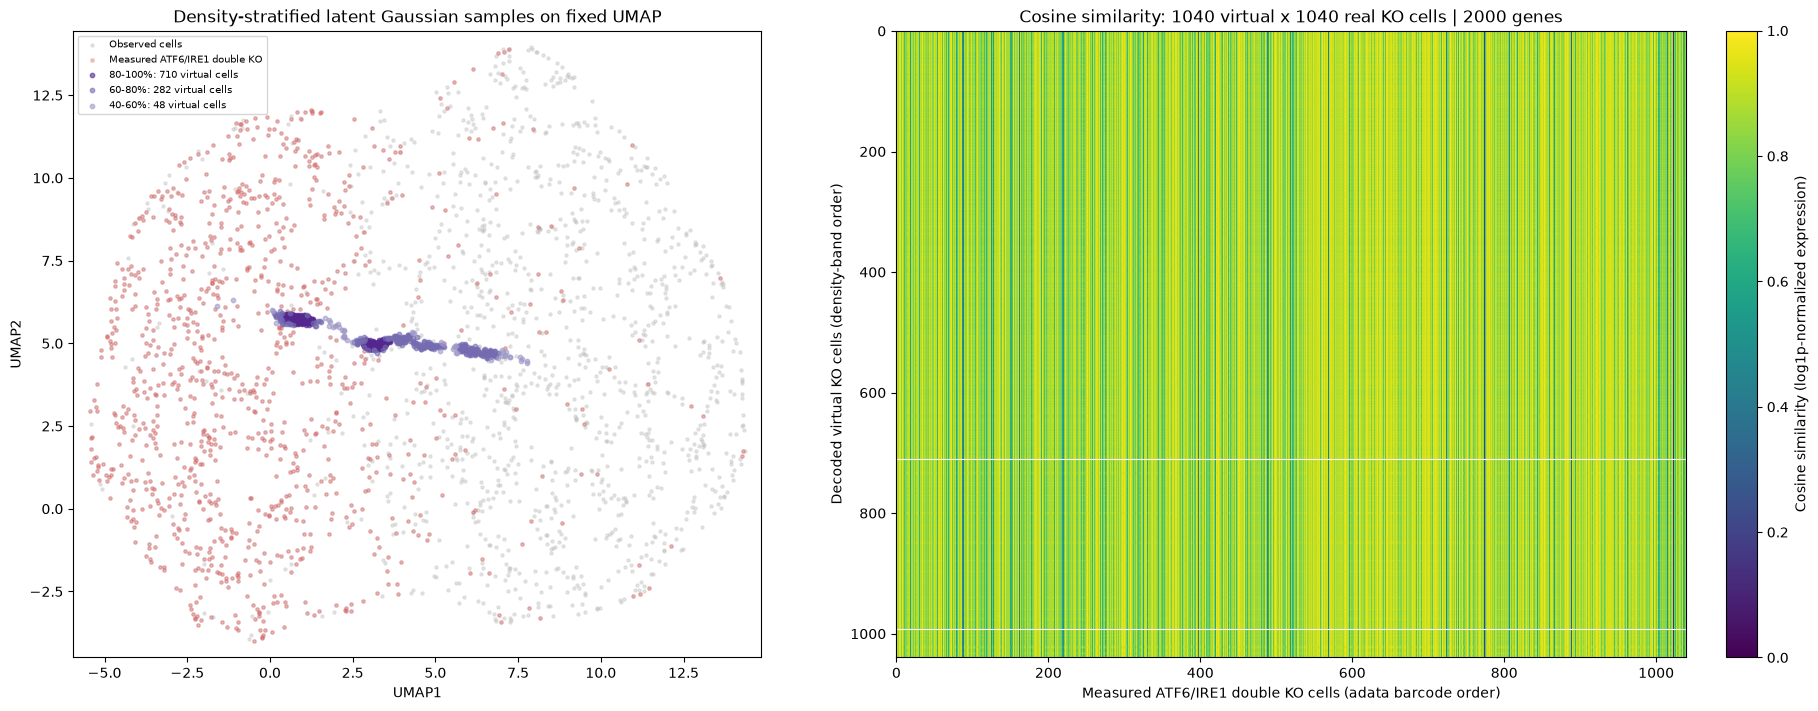

Saved decoded virtual cells, measured KO expression, 2000 genes and cosine heatmap: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/control_condition_double_ko_branch_dqn/gaussian_ko_comparison


Saved decoded virtual cells, measured KO expression, 2000 genes and cosine heatmap: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/control_condition_double_ko_branch_dqn/gaussian_ko_comparison


In [21]:
from scipy.interpolate import RegularGridInterpolator
from sklearn.metrics.pairwise import cosine_similarity
from scipy import sparse

gs_required_state = ['lg_sims', 'lg_density', 'lg_x_edges', 'lg_y_edges', 'lg_z', 'lg_symbols',
                     'lg_decoder', 'LG_DEVICE', 'LG_DIR', 'project_umap', 'lg_observed_xy']
gs_missing = [name for name in gs_required_state if name not in globals()]
if gs_missing:
    raise RuntimeError(f'Run section 14 first; missing: {gs_missing}')
GS_SEED, GS_SIGMA_SD = 20261031, 0.03
GS_BATCH_SIZE, GS_MAX_PROPOSALS = 2048, 200000
GS_DIR = LG_DIR / 'gaussian_ko_comparison'
gs_rng = np.random.default_rng(GS_SEED)
gs_real_mask = adata.obs['perturbation'].astype(str).to_numpy() == 'ATF6_IRE1_pMJ152'
gs_n = int(gs_real_mask.sum())
if gs_n < 1:
    raise ValueError('No measured ATF6/IRE1 double KO cells remain in adata.')
np.testing.assert_array_equal(lg_symbols, adata.var_names.to_numpy(dtype=str))
np.testing.assert_array_equal(lg_z, adata.obsm['X_z'])
np.testing.assert_array_equal(lg_observed_xy, adata.obsm['X_umap'])
gs_required_genes = ['ATF6', 'ERN1', 'HSPA5', 'HSP90B1', 'HERPUD1', 'PDIA4', 'CALR']
if not adata.var_names.is_unique or not set(gs_required_genes).issubset(adata.var_names):
    raise ValueError('Unique decoder gene symbols and all seven required genes are necessary.')
gs_ranked = adata.var.rename_axis(None).assign(gene_symbol=adata.var_names).sort_values(
    ['deg_log2fc', 'gene_symbol'], ascending=[False, True])
gs_genes = gs_ranked.loc[~gs_ranked.index.isin(gs_required_genes)].index[:1993].tolist() + gs_required_genes
if len(gs_genes) != 2000 or len(set(gs_genes)) != 2000:
    raise ValueError('Expected 1993 ranked non-required genes plus seven required genes, exactly 2000.')
gs_gene_indices = adata.var_names.get_indexer(gs_genes)
gs_panel_expression = adata[:, gs_genes].X
gs_panel_expression = (gs_panel_expression.toarray() if sparse.issparse(gs_panel_expression)
                       else np.asarray(gs_panel_expression)).astype(np.float32)
gs_nonzero_mask = nonzero_evaluation_mask(gs_panel_expression)
gs_excluded_mask = gs_real_mask & ~gs_nonzero_mask
gs_excluded_cells = adata.obs.loc[gs_excluded_mask, ['perturbation']].copy()
gs_excluded_cells['reason'] = 'zero_expression_in_fixed_2000_gene_evaluation_panel'
gs_excluded_cells.index.name = 'cell_barcode'
GS_DIR.mkdir(parents=True, exist_ok=True)
gs_excluded_cells.to_csv(GS_DIR / 'excluded_zero_panel_cells.csv')
if gs_excluded_mask.any():
    print(f'Evaluation-only exclusion: {int(gs_excluded_mask.sum())} double-KO zero-panel cells; training adata unchanged.')
    display(gs_excluded_cells)
gs_real_mask = gs_real_mask & gs_nonzero_mask
gs_n = int(gs_real_mask.sum())
if gs_n < 1:
    raise ValueError('No nonzero-panel double-KO evaluation cells remain.')
gs_bands = np.array([[0.8, 1.0], [0.6, 0.8], [0.4, 0.6]])
gs_labels = ['80-100%', '60-80%', '40-60%']
gs_fractions = np.array([0.683, 0.271, 0.046])
gs_raw_counts = gs_n * gs_fractions
gs_counts = np.floor(gs_raw_counts).astype(int)
gs_remainder_order = np.argsort(-(gs_raw_counts - gs_counts), kind='stable')
gs_counts[gs_remainder_order[:gs_n - gs_counts.sum()]] += 1
assert gs_counts.sum() == gs_n
gs_x_centers = (lg_x_edges[1:] + lg_x_edges[:-1]) / 2
gs_y_centers = (lg_y_edges[1:] + lg_y_edges[:-1]) / 2
if lg_density.shape != (len(gs_y_centers), len(gs_x_centers)) or not np.isfinite(lg_density).all():
    raise ValueError('Invalid section 14 density grid.')
if not np.isclose(lg_density.max(), 1) or lg_density.min() < 0:
    raise ValueError('Density must have a peak of one and nonnegative values.')
gs_density_at_xy = RegularGridInterpolator((gs_y_centers, gs_x_centers), lg_density,
                                         bounds_error=False, fill_value=0.0)
gs_anchors = np.concatenate([result['path'][1:] for result in lg_sims])
gs_sigma = GS_SIGMA_SD * lg_z.std(axis=0)
if not len(gs_anchors) or not np.isfinite(gs_anchors).all() or not np.isfinite(gs_sigma).all() or (gs_sigma <= 0).any():
    raise ValueError('Finite DQN arrival coordinates and positive latent-axis Gaussian SDs are required.')


def gs_in_band(values, band):
    lower, upper = gs_bands[band]
    return (values >= lower) & ((values <= upper) if band == 0 else (values < upper))


gs_z_chunks, gs_xy_chunks, gs_density_chunks = [[], [], []], [[], [], []], [[], [], []]
gs_accepted, gs_proposals = np.zeros(3, dtype=int), 0
while (gs_accepted < gs_counts).any() and gs_proposals < GS_MAX_PROPOSALS:
    batch_n = min(GS_BATCH_SIZE, GS_MAX_PROPOSALS - gs_proposals)
    anchor_indices = gs_rng.integers(len(gs_anchors), size=batch_n)
    candidates = (gs_anchors[anchor_indices] + gs_rng.normal(size=(batch_n, lg_z.shape[1])) * gs_sigma).astype(np.float32)
    candidate_xy = project_umap(candidates)
    candidate_density = gs_density_at_xy(candidate_xy[:, [1, 0]])
    if not np.isfinite(candidate_density).all():
        raise FloatingPointError('Non-finite candidate density.')
    for band in range(3):
        needed = gs_counts[band] - gs_accepted[band]
        selected = np.flatnonzero(gs_in_band(candidate_density, band))[:needed]
        if len(selected):
            gs_z_chunks[band].append(candidates[selected])
            gs_xy_chunks[band].append(candidate_xy[selected])
            gs_density_chunks[band].append(candidate_density[selected])
            gs_accepted[band] += len(selected)
    gs_proposals += batch_n
    print(f'Gaussian proposals {gs_proposals}: accepted {gs_accepted.tolist()} / {gs_counts.tolist()}', flush=True)
if not np.array_equal(gs_accepted, gs_counts):
    raise RuntimeError(f'Density quotas not reached after {gs_proposals} proposals: {gs_accepted.tolist()} / {gs_counts.tolist()}. No new result exported. Inspect density/bandwidth before adjusting GS_SIGMA_SD or GS_MAX_PROPOSALS; bands are never widened automatically.')
gs_virtual_z = np.concatenate([np.concatenate(chunks) for chunks in gs_z_chunks if chunks])
gs_virtual_xy = np.concatenate([np.concatenate(chunks) for chunks in gs_xy_chunks if chunks])
gs_sample_density = np.concatenate([np.concatenate(chunks) for chunks in gs_density_chunks if chunks])
gs_sample_band = np.repeat(np.arange(3), gs_counts)
assert len(gs_virtual_z) == len(gs_virtual_xy) == gs_n
for band in range(3):
    assert gs_in_band(gs_sample_density[gs_sample_band == band], band).all()
with torch.no_grad():
    gs_decoded = np.concatenate([
        lg_decoder(torch.tensor(gs_virtual_z[start:start + 256], device=LG_DEVICE)).clamp_min(0).cpu().numpy()
        for start in range(0, gs_n, 256)])
gs_virtual_expression = gs_decoded[:, gs_gene_indices]
gs_measured_x = adata[gs_real_mask, gs_genes].X
gs_real_expression = (gs_measured_x.toarray() if sparse.issparse(gs_measured_x) else np.asarray(gs_measured_x)).astype(np.float32)
for expression in [gs_virtual_expression, gs_real_expression]:
    if expression.shape != (gs_n, 2000) or not np.isfinite(expression).all() or (expression < 0).any():
        raise ValueError('Expected finite nonnegative log1p-normalized expression on exactly 2000 genes.')
    if (np.linalg.norm(expression, axis=1) == 0).any():
        raise ValueError('Cosine similarity is undefined for zero-expression cells.')
gs_cosine = cosine_similarity(gs_virtual_expression, gs_real_expression)
if gs_cosine.shape != (gs_n, gs_n) or not np.isfinite(gs_cosine).all() or gs_cosine.min() < -1e-6 or gs_cosine.max() > 1 + 1e-6:
    raise FloatingPointError('Invalid virtual-cell by measured-KO-cell cosine matrix.')
gs_cosine = np.clip(gs_cosine, 0, 1)
gs_virtual_ids = np.array([f'gaussian_KO_{i:05d}' for i in range(gs_n)])
gs_real_ids = adata.obs_names[gs_real_mask].to_numpy(dtype=str)
gs_samples = pd.DataFrame({'virtual_cell': gs_virtual_ids, 'density_band': np.array(gs_labels)[gs_sample_band],
                           'relative_density': gs_sample_density, 'UMAP1': gs_virtual_xy[:, 0], 'UMAP2': gs_virtual_xy[:, 1]})
gs_quotas = pd.DataFrame({'density_band': gs_labels, 'target_fraction': gs_fractions,
                         'samples': gs_counts, 'actual_fraction': gs_counts / gs_n})
display(gs_quotas)
fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
axes[0].scatter(*lg_observed_xy.T, s=5, c='#BBBBBB', alpha=0.35, label='Observed cells')
axes[0].scatter(*lg_observed_xy[gs_real_mask].T, s=6, c='#E45756', alpha=0.3, label='Measured ATF6/IRE1 double KO')
for band, color in enumerate(['#54278F', '#756BB1', '#9E9AC8']):
    axes[0].scatter(*gs_virtual_xy[gs_sample_band == band].T, s=10, c=color, alpha=0.6,
                    label=f'{gs_labels[band]}: {gs_counts[band]} virtual cells')
axes[0].set(xlabel='UMAP1', ylabel='UMAP2', title='Density-stratified latent Gaussian samples on fixed UMAP',
            xlim=(lg_x_edges[0], lg_x_edges[-1]), ylim=(lg_y_edges[0], lg_y_edges[-1]))
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend(fontsize=7)
gs_image = axes[1].imshow(gs_cosine, aspect='auto', interpolation='nearest', cmap='viridis', vmin=0, vmax=1)
for boundary in np.cumsum(gs_counts)[:-1]:
    axes[1].axhline(boundary - 0.5, c='white', lw=0.8)
axes[1].set(xlabel='Measured ATF6/IRE1 double KO cells (adata barcode order)', ylabel='Decoded virtual KO cells (density-band order)',
            title=f'Cosine similarity: {gs_n} virtual x {gs_n} real KO cells | 2000 genes')
fig.colorbar(gs_image, ax=axes[1], label='Cosine similarity (log1p-normalized expression)')
GS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(GS_DIR / 'gaussian_virtual_vs_real_KO_cosine_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()
gs_samples.to_csv(GS_DIR / 'virtual_samples.csv', index=False)
gs_quotas.to_csv(GS_DIR / 'density_sampling_quotas.csv', index=False)
pd.DataFrame({'gene': gs_genes, 'decoder_index': gs_gene_indices}).to_csv(GS_DIR / 'comparison_genes_2000.csv', index=False)
np.savez_compressed(GS_DIR / 'virtual_vs_real_KO.npz', virtual_z=gs_virtual_z, virtual_umap=gs_virtual_xy,
                    relative_density=gs_sample_density, density_band=gs_sample_band,
                    virtual_expression=gs_virtual_expression, real_expression=gs_real_expression,
                    cosine_similarity=gs_cosine, genes=np.asarray(gs_genes),
                    virtual_cell_ids=gs_virtual_ids, real_cell_barcodes=gs_real_ids)
(GS_DIR / 'sampling_metadata.json').write_text(json.dumps({
    'seed': GS_SEED, 'samples_per_group': gs_n, 'gene_count': 2000, 'sigma_observed_sd_fraction': GS_SIGMA_SD,
    'gaussian': 'Uniform mixture over DQN arrival latent coordinates; diagonal covariance (sigma_observed_sd_fraction * observed latent SD)^2',
    'density': 'Bilinear interpolation of section 14 peak-normalized Gaussian-smoothed UMAP visit density, not a density percentile',
    'band_boundaries': '[0.8,1], [0.6,0.8), [0.4,0.6)', 'fractions': gs_fractions.tolist(), 'counts': gs_counts.tolist(),
    'integer_allocation': 'largest remainder', 'proposals': gs_proposals,
    'expression': 'Full original VAE decoder output clamped at zero in log1p CP10K space; select 1993 ranked non-required + seven required genes. Actual KO uses measured adata.X, not VAE reconstruction.',
    'interpretation': 'Model-based sampled KO-like expression; not evidence of causal KO accuracy.'}, indent=2))
print(f'Saved decoded virtual cells, measured KO expression, 2000 genes and cosine heatmap: {GS_DIR}')


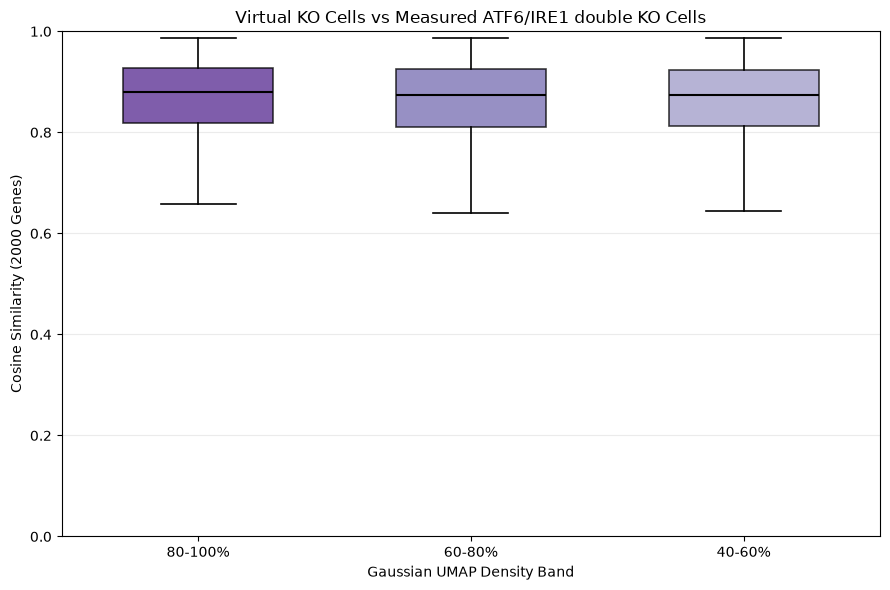

,density_band,n_virtual_cells,n_pairwise_comparisons,mean_cosine_similarity,median_cosine_similarity
0,80-100%,710,738400,0.856481,0.879891
1,60-80%,282,293280,0.851387,0.873475
2,40-60%,48,49920,0.852366,0.874765


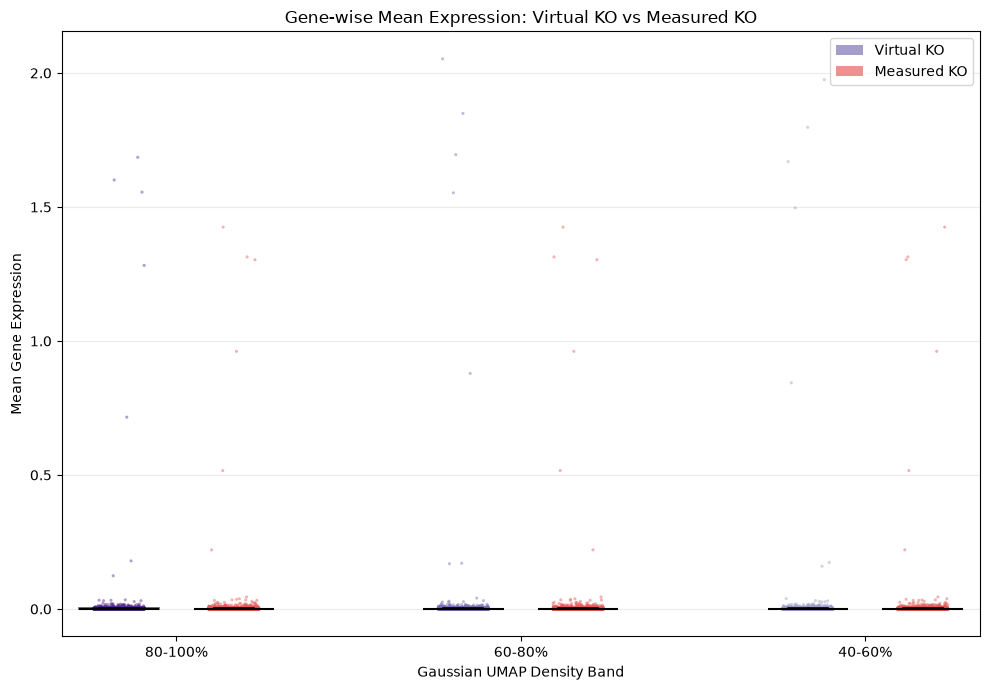

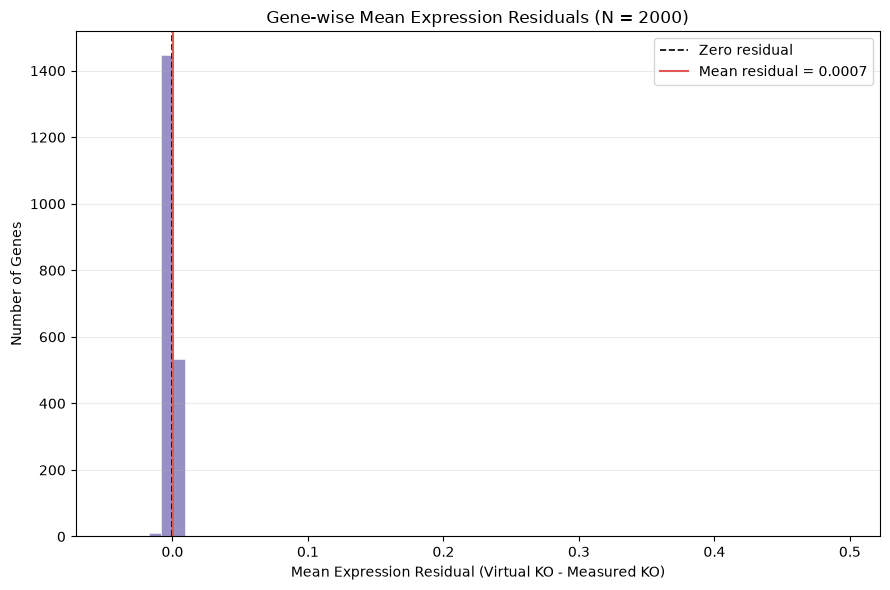

,gene,virtual_mean_expression,measured_mean_expression,residual
0,MTRNR2L4,0.000001,0.001371,-0.001370
1,AC004540.5,0.000228,0.001811,-0.001583
2,FCER2,0.001426,0.002154,-0.000729
3,RP11-65L3.4,0.000000,0.001181,-0.001181
4,RP11-54A4.2,0.000197,0.001960,-0.001763
...,...,...,...,...
1995,HSPA5,1.798564,1.303302,0.495263
1996,HSP90B1,1.677268,1.313646,0.363621
1997,HERPUD1,1.365429,0.961490,0.403939
1998,PDIA4,0.766044,0.516616,0.249428


In [22]:
gs_box_data = [
    gs_cosine[gs_sample_band == band].ravel()
    for band in range(3)
]

fig, ax = plt.subplots(figsize=(9, 6))

bp = ax.boxplot(
    gs_box_data,
    tick_labels=gs_labels,
    patch_artist=True,
    showfliers=False,
    widths=0.55,
    medianprops={'color': 'black', 'linewidth': 1.5},
    whiskerprops={'linewidth': 1.2},
    capprops={'linewidth': 1.2},
    boxprops={'linewidth': 1.2}
)

gs_colors = ['#54278F', '#756BB1', '#9E9AC8']

for patch, color in zip(bp['boxes'], gs_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xlabel('Gaussian UMAP Density Band')
ax.set_ylabel('Cosine Similarity (2000 Genes)')
ax.set_title('Virtual KO Cells vs Measured ATF6/IRE1 double KO Cells')
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()

fig.savefig(
    GS_DIR / 'virtual_vs_real_KO_cellwise_cosine_boxplot.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()

gs_similarity_summary = pd.DataFrame({
    'density_band': gs_labels,
    'n_virtual_cells': gs_counts,
    'n_pairwise_comparisons': [
        int((gs_sample_band == band).sum() * gs_n)
        for band in range(3)
    ],
    'mean_cosine_similarity': [
        gs_cosine[gs_sample_band == band].mean()
        for band in range(3)
    ],
    'median_cosine_similarity': [
        np.median(gs_cosine[gs_sample_band == band])
        for band in range(3)
    ]
})

display(gs_similarity_summary)

gs_similarity_summary.to_csv(
    GS_DIR / 'cellwise_cosine_similarity_summary.csv',
    index=False
)

gs_gene_mean_virtual = np.vstack([
    gs_virtual_expression[gs_sample_band == band].mean(axis=0)
    for band in range(3)
])

gs_gene_mean_real = gs_real_expression.mean(axis=0)

gs_box_data = []
gs_box_positions = []
gs_box_colors = []

gs_real_color = '#E45756'

for band in range(3):
    gs_box_data.extend([
        gs_gene_mean_virtual[band],
        gs_gene_mean_real
    ])
    gs_box_positions.extend([
        band * 3 + 1,
        band * 3 + 2
    ])
    gs_box_colors.extend([
        gs_colors[band],
        gs_real_color
    ])

fig, ax = plt.subplots(figsize=(10, 7))

bp = ax.boxplot(
    gs_box_data,
    positions=gs_box_positions,
    patch_artist=True,
    showfliers=False,
    widths=0.7,
    medianprops={'color': 'black', 'linewidth': 1.5},
    whiskerprops={'linewidth': 1.2},
    capprops={'linewidth': 1.2},
    boxprops={'linewidth': 1.2}
)

for patch, color in zip(bp['boxes'], gs_box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

gs_rng_plot = np.random.default_rng(GS_SEED)

for i, values in enumerate(gs_box_data):
    ax.scatter(
        gs_box_positions[i] + gs_rng_plot.uniform(-0.22, 0.22, len(values)),
        values,
        s=5,
        alpha=0.45,
        color=gs_box_colors[i],
        edgecolors='none',
        rasterized=True
    )

from matplotlib.patches import Patch

ax.set_xticks([1.5, 4.5, 7.5])
ax.set_xticklabels(gs_labels)
ax.set_xlabel('Gaussian UMAP Density Band')
ax.set_ylabel('Mean Gene Expression')
ax.set_title('Gene-wise Mean Expression: Virtual KO vs Measured KO')

ax.legend(
    handles=[
        Patch(facecolor='#756BB1', alpha=0.65, label='Virtual KO'),
        Patch(facecolor=gs_real_color, alpha=0.65, label='Measured KO')
    ],
    loc='upper right'
)

ax.grid(axis='y', alpha=0.25)

plt.tight_layout()

fig.savefig(
    GS_DIR / 'gene_set_expression_boxplot.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()

gs_gene_mean_virtual_all = gs_virtual_expression.mean(axis=0)
gs_gene_mean_real_all = gs_real_expression.mean(axis=0)

gs_gene_residual_all = (
    gs_gene_mean_virtual_all - gs_gene_mean_real_all
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    gs_gene_residual_all,
    bins=60,
    color='#756BB1',
    alpha=0.75,
    edgecolor='white',
    linewidth=0.5
)

ax.axvline(
    0,
    color='black',
    linestyle='--',
    linewidth=1.2,
    label='Zero residual'
)

ax.axvline(
    gs_gene_residual_all.mean(),
    color='#E45756',
    linewidth=1.5,
    label=f'Mean residual = {gs_gene_residual_all.mean():.4f}'
)

ax.set_xlabel('Mean Expression Residual (Virtual KO - Measured KO)')
ax.set_ylabel('Number of Genes')
ax.set_title('Gene-wise Mean Expression Residuals (N = 2000)')
ax.legend()
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()

fig.savefig(
    GS_DIR / 'overall_gene_mean_expression_residual_histogram.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()

gs_residual_summary = pd.DataFrame({
    'gene': gs_genes,
    'virtual_mean_expression': gs_gene_mean_virtual_all,
    'measured_mean_expression': gs_gene_mean_real_all,
    'residual': gs_gene_residual_all
})

display(gs_residual_summary)

gs_residual_summary.to_csv(
    GS_DIR / 'overall_gene_mean_expression_residuals.csv',
    index=False
)

## 15. Virtual double KO vs three measured perturbations: metrics 1, 6, 7, 8, 12

1. 모든 virtual × 실제 세포쌍 cosine boxplot.
2. 유전자별 `mean(virtual double KO) - mean(measured)` residual boxplot.
3. 2,000개 유전자 평균 벡터의 Pearson r.
4. 위 residual의 MAE / RMSE.
5. 1번 cosine의 50개 공통 bin histogram(독립 점수가 아님).

세 density band를 합친 동일 virtual population을 세 실제 비교군에 재사용합니다.
실제 비교군은 raw 전체 유전자 counts → CP10K → log1p 후 **고정 평가 패널**만 추출합니다.
비교군별 DEG/HVG 재선정·패널 재정규화·모델 재학습은 하지 않습니다.
Double-KO 비교는 학습에 사용한 population 비교이며, single-KO 비교는 다른 perturbation과의 분포 차이입니다.
Double-KO 실제 비교군은 현재 `adata`에서 남긴 유효 세포와 14-2의 `gs_real_ids`에 맞춰 선택·정렬합니다.
원본에서 다시 불러온 제외 세포는 평가에 복원하지 않으며, 제외 barcode·사유를 별도 CSV에 기록합니다.
Single-KO 비교군은 기존처럼 전체 원본에서 zero-panel 세포만 제외합니다.
세포쌍은 독립 표본이 아니므로 p-value를 계산하지 않습니다.


Evaluation-only zero-panel exclusions by condition:


,perturbation,reason
cell_barcode,,
CGTGCACTGGCGAA,ATF6_IRE1_pMJ152,zero_expression_in_fixed_2000_gene_evaluation_...
TCGGCACTAGAGAT,ATF6_IRE1_pMJ152,zero_expression_in_fixed_2000_gene_evaluation_...
ACGCCTTGCCCTAC,IRE1_only_pMJ148,zero_expression_in_fixed_2000_gene_evaluation_...
CATCATACGAATGA,ATF6_IRE1_pMJ152,zero_expression_in_fixed_2000_gene_evaluation_...


Preserving user cell selection: excluding 406 additional double-KO cells from evaluation.


,perturbation,reason
cell_barcode,,
AATCAAACGGACAG,ATF6_IRE1_pMJ152,excluded_from_current_adata_double_KO_population
AGCCGGTGTGCCAA,ATF6_IRE1_pMJ152,excluded_from_current_adata_double_KO_population
CAAGAAGATCTCGC,ATF6_IRE1_pMJ152,excluded_from_current_adata_double_KO_population
CCAGCGGAGCTAAC,ATF6_IRE1_pMJ152,excluded_from_current_adata_double_KO_population
CGGACTCTTGGAAA,ATF6_IRE1_pMJ152,excluded_from_current_adata_double_KO_population
...,...,...
TTCTCAGAGACGGA,ATF6_IRE1_pMJ152,excluded_from_current_adata_double_KO_population
TTGAACCTTCGACA,ATF6_IRE1_pMJ152,excluded_from_current_adata_double_KO_population
TTGACACTTCGTGA,ATF6_IRE1_pMJ152,excluded_from_current_adata_double_KO_population


,condition,n_predicted_cells,n_measured_cells,n_genes,n_cosine_pairs,cosine_mean,cosine_median,gene_MAE,gene_RMSE,gene_mean_residual,gene_Pearson_r
0,ATF6_IRE1_pMJ152,1040,1040,2000,1081600,0.854910,0.878027,0.002009,0.018062,0.000728,0.994146
1,ATF6_only_pMJ145,1040,1691,2000,1758640,0.866704,0.901269,0.001938,0.017647,0.001274,0.995681
2,IRE1_only_pMJ148,1040,1684,2000,1751360,0.900613,0.945122,0.001443,0.008464,0.000442,0.994150


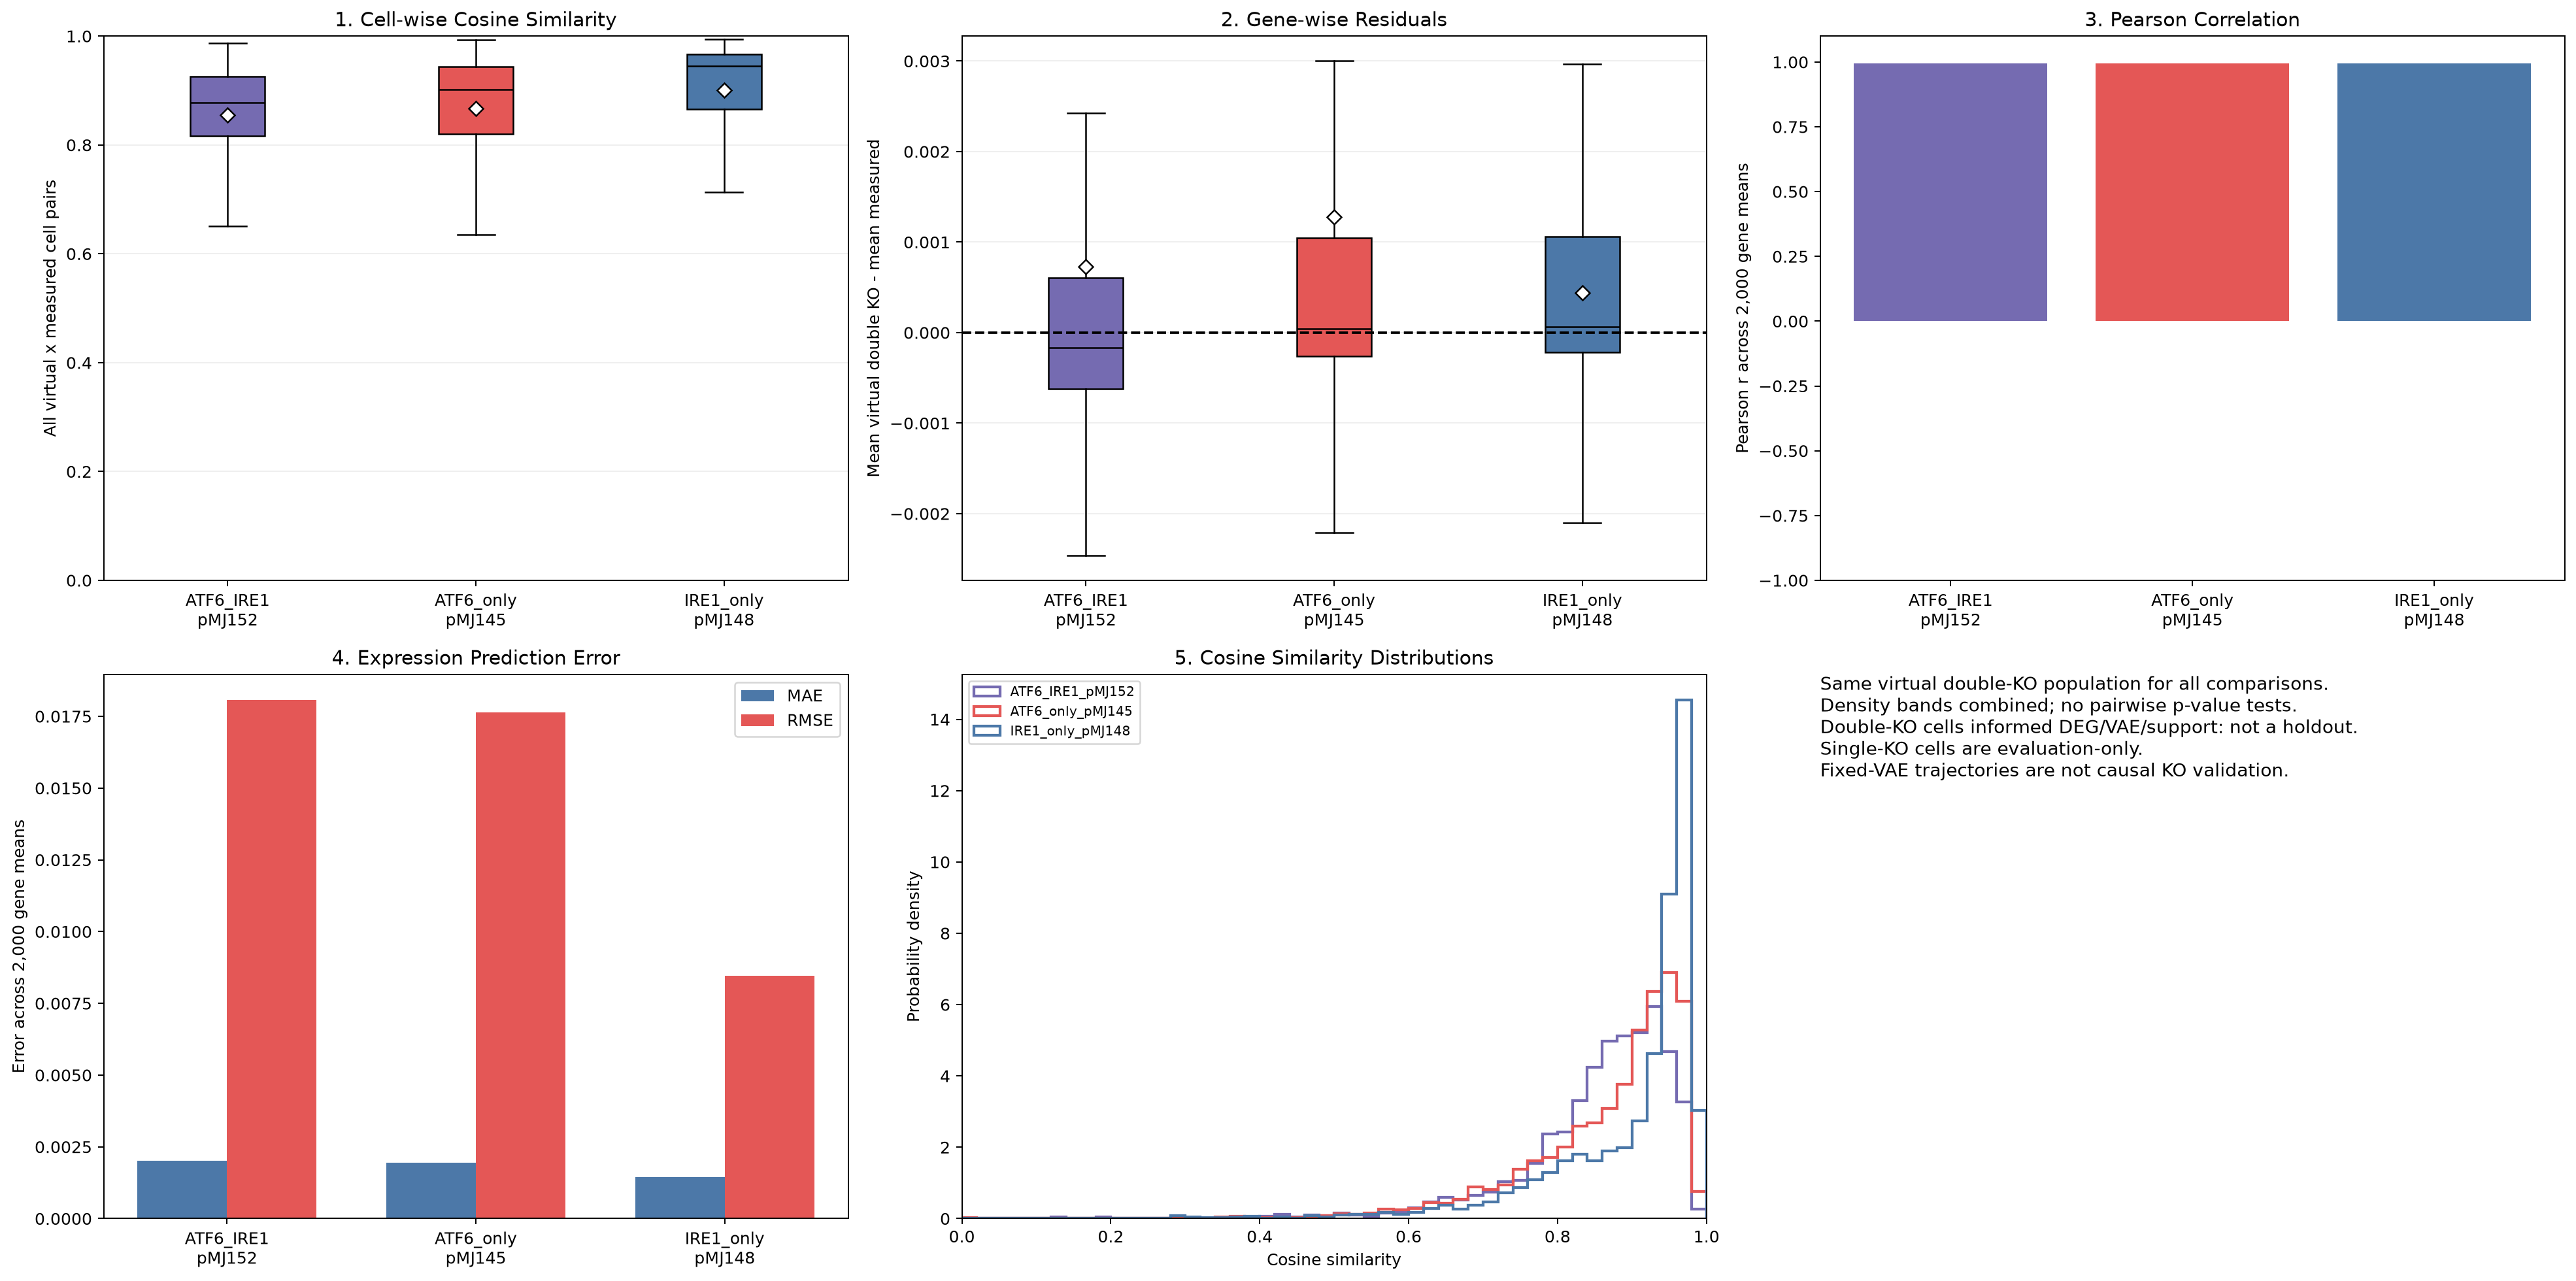

All three comparisons verified; saved to: /home/Data_Drive_8TB/kykim/0. Jupyter/RL/scDQN_results/double_ko/double_ko_deg2993_required7_fixed_umap_v1/control_condition_double_ko_branch_dqn/three_condition_five_metrics
Gaussian sample fraction with both targets below shared start: 1.0


In [24]:
import hashlib
from IPython.display import Image

evaluation_source = sc.read_h5ad(DATA_PATH, backed='r')
try:
    evaluation_mask = evaluation_source.obs['perturbation'].isin(COMPARISON_CONDITIONS).to_numpy()
    evaluation_adata = evaluation_source[evaluation_mask].to_memory()
finally:
    evaluation_source.file.close()
if not evaluation_adata.var_names.is_unique or not evaluation_adata.obs_names.is_unique:
    raise ValueError('Evaluation gene symbols and barcodes must be unique.')
evaluation_values = (evaluation_adata.X.data if sparse.issparse(evaluation_adata.X)
                     else np.asarray(evaluation_adata.X))
if not np.isfinite(evaluation_values).all() or (evaluation_values < 0).any():
    raise ValueError('Evaluation raw counts must be finite and nonnegative.')
if not np.allclose(evaluation_values, np.rint(evaluation_values), rtol=0, atol=1e-6):
    raise ValueError('Evaluation input must be raw integer counts.')
if (np.asarray(evaluation_adata.X.sum(axis=1)).ravel() <= 0).any():
    raise ValueError('Evaluation cells must have nonzero full-gene libraries.')
evaluation_adata.uns.pop('log1p', None)
sc.pp.normalize_total(evaluation_adata, target_sum=1e4)
sc.pp.log1p(evaluation_adata)
if not set(gs_genes).issubset(evaluation_adata.var_names):
    raise ValueError('Evaluation data are missing frozen panel genes.')
evaluation_adata = evaluation_adata[:, gs_genes].copy()
np.testing.assert_array_equal(evaluation_adata.var_names.to_numpy(), gs_genes)
evaluation_panel = (evaluation_adata.X.toarray() if sparse.issparse(evaluation_adata.X)
                    else np.asarray(evaluation_adata.X)).astype(np.float32)
evaluation_nonzero = nonzero_evaluation_mask(evaluation_panel)
excluded_evaluation_cells = evaluation_adata.obs.loc[~evaluation_nonzero, ['perturbation']].copy()
excluded_evaluation_cells['reason'] = 'zero_expression_in_fixed_2000_gene_evaluation_panel'
excluded_evaluation_cells.index.name = 'cell_barcode'
DOUBLE_EVAL_DIR = LG_DIR / 'three_condition_five_metrics'
DOUBLE_EVAL_DIR.mkdir(parents=True, exist_ok=True)
excluded_evaluation_cells.to_csv(DOUBLE_EVAL_DIR / 'excluded_zero_panel_cells.csv')
if (~evaluation_nonzero).any():
    print('Evaluation-only zero-panel exclusions by condition:')
    display(excluded_evaluation_cells)
evaluation_adata = evaluation_adata[evaluation_nonzero].copy()
current_double_mask = adata.obs['perturbation'].eq(ATF6_CONDITION).to_numpy()
current_double_panel = adata[current_double_mask, gs_genes].X
current_double_panel = (current_double_panel.toarray() if sparse.issparse(current_double_panel)
                        else np.asarray(current_double_panel)).astype(np.float32)
current_double_ids = adata.obs_names[current_double_mask][nonzero_evaluation_mask(current_double_panel)].to_numpy(dtype=str)
if not np.array_equal(gs_real_ids, current_double_ids):
    raise ValueError('Current retained double-KO cells differ from section 14-2. Rerun section 14 after changing cells, then 14-2 before this evaluation.')
double_positions = evaluation_adata.obs_names.get_indexer(gs_real_ids)
if len(np.unique(gs_real_ids)) != len(gs_real_ids) or (double_positions < 0).any():
    raise ValueError('Section 14-2 double-KO barcodes must be unique and present in the nonzero evaluation population.')
if not evaluation_adata.obs.iloc[double_positions]['perturbation'].eq(ATF6_CONDITION).all():
    raise ValueError('Section 14-2 evaluation barcodes include cells outside the double-KO condition.')
excluded_selection_mask = (evaluation_adata.obs['perturbation'].eq(ATF6_CONDITION)
                           & ~evaluation_adata.obs_names.isin(gs_real_ids))
excluded_selection_cells = evaluation_adata.obs.loc[excluded_selection_mask, ['perturbation']].copy()
excluded_selection_cells['reason'] = 'excluded_from_current_adata_double_KO_population'
excluded_selection_cells.index.name = 'cell_barcode'
excluded_selection_cells.to_csv(DOUBLE_EVAL_DIR / 'excluded_cell_selection.csv')
if len(excluded_selection_cells):
    print(f'Preserving user cell selection: excluding {len(excluded_selection_cells)} additional double-KO cells from evaluation.')
    display(excluded_selection_cells)
evaluation_adata = evaluation_adata[~excluded_selection_mask.to_numpy()].copy()
measured_by_condition, measured_ids = {}, {}
for condition in COMPARISON_CONDITIONS:
    selected = evaluation_adata.obs['perturbation'].eq(condition).to_numpy()
    if not selected.any():
        raise ValueError(f'Missing measured comparison condition: {condition}')
    condition_adata = (evaluation_adata[gs_real_ids.tolist()] if condition == ATF6_CONDITION
                       else evaluation_adata[selected])
    condition_expression = condition_adata.X
    measured_by_condition[condition] = (condition_expression.toarray() if sparse.issparse(condition_expression)
                                        else np.asarray(condition_expression)).astype(np.float32)
    measured_ids[condition] = condition_adata.obs_names.tolist()
    if condition != ATF6_CONDITION and set(measured_ids[condition]) & set(adata.obs_names):
        raise ValueError('Single-KO evaluation cells leaked into the training population.')
np.testing.assert_array_equal(measured_ids[ATF6_CONDITION], gs_real_ids.tolist())
np.testing.assert_allclose(measured_by_condition[ATF6_CONDITION], gs_real_expression, rtol=1e-6, atol=1e-6)
DOUBLE_EVAL_DIR = LG_DIR / 'three_condition_five_metrics'
double_ko_summary = compare_three_conditions(gs_virtual_expression, measured_by_condition, gs_genes, DOUBLE_EVAL_DIR)
display(double_ko_summary)
display(Image(filename=str(DOUBLE_EVAL_DIR / 'five_metric_comparison.png')))
target_panel_indices = [gs_genes.index(gene) for gene in KO_TARGETS]
sampled_targets = gs_virtual_expression[:, target_panel_indices]
shared_start_targets = lg_start_pair.cpu().numpy()
gs_samples['decoded_ATF6'] = sampled_targets[:, 0]
gs_samples['decoded_ERN1'] = sampled_targets[:, 1]
gs_samples['both_below_shared_start'] = (sampled_targets < shared_start_targets).all(axis=1)
gs_samples.to_csv(GS_DIR / 'virtual_samples.csv', index=False)
np.savez_compressed(
    DOUBLE_EVAL_DIR / 'evaluation_populations.npz', virtual_expression=gs_virtual_expression,
    virtual_ids=gs_virtual_ids, density_band=gs_sample_band, genes=np.array(gs_genes),
    **{f'measured_{i}': measured_by_condition[condition] for i, condition in enumerate(COMPARISON_CONDITIONS)},
    **{f'barcodes_{i}': np.array(measured_ids[condition]) for i, condition in enumerate(COMPARISON_CONDITIONS)},
)
provenance = {
    'source_notebook': 'Benchmark-DQN.ipynb', 'metric_source': 'Total_benchmark.ipynb / total_benchmark.evaluate_expression',
    'kernel': 'scrna', 'interpreter': sys.executable,
    'workflow_version': WORKFLOW_VERSION, 'reward_version': LG_REWARD_VERSION,
    'training_conditions': CONDITIONS, 'comparison_conditions': COMPARISON_CONDITIONS,
    'target_symbols': KO_TARGETS, 'IRE1_official_symbol': 'ERN1',
    'required_genes': REQUIRED_GENES, 'training_genes': adata.var_names.tolist(),
    'evaluation_genes': gs_genes,
    'gene_panel_sha256': hashlib.sha256('\n'.join(gs_genes).encode()).hexdigest(),
    'expression_space': 'full-gene counts -> CP10K -> log1p -> fixed 2000-gene panel',
    'metric_numbers': [1, 6, 7, 8, 12],
    'training_barcodes': adata.obs_names.tolist(), 'comparison_barcodes': measured_ids,
    'same_virtual_population_for_all_comparisons': True, 'density_bands_combined': True,
    'gaussian_seed': GS_SEED, 'gaussian_sigma_observed_sd': GS_SIGMA_SD,
    'density_band_samples': gs_counts.tolist(), 'shared_start_targets': shared_start_targets.tolist(),
    'gaussian_fraction_both_targets_below_shared_start': float(gs_samples['both_below_shared_start'].mean()),
    'double_KO_is_independent_holdout': False, 'single_KO_used_for_training': False,
    'zero_expression_policy': 'user-approved evaluation-only exclusion; no training cells removed',
    'excluded_evaluation_cells': excluded_evaluation_cells.reset_index().to_dict(orient='records'),
    'double_KO_selection': 'current retained adata cells; exact section 14-2 barcode order',
    'excluded_cell_selection': excluded_selection_cells.reset_index().to_dict(orient='records'),
    'interpretation': 'Model-based expression distribution comparison, not causal gene deletion validation.',
}
(DOUBLE_EVAL_DIR / 'benchmark_provenance.json').write_text(json.dumps(provenance, indent=2))
assert set(adata.obs['perturbation'].astype(str)) == set(CONDITIONS)
assert adata.obs_names.is_unique and adata.obs_names.isin(input_cell_names).all()
np.testing.assert_array_equal(adata.obs_names.to_numpy(dtype=str), lg_barcodes)
assert adata.var_names.equals(input_gene_names)
assert len(double_ko_summary) == 3 and len(gs_genes) == 2000
assert double_ko_summary['n_predicted_cells'].eq(gs_n).all()
assert double_ko_summary['n_genes'].eq(2000).all()
assert np.array_equal(gs_accepted, gs_counts)
print('All three comparisons verified; saved to:', DOUBLE_EVAL_DIR)
print('Gaussian sample fraction with both targets below shared start:',
      provenance['gaussian_fraction_both_targets_below_shared_start'])


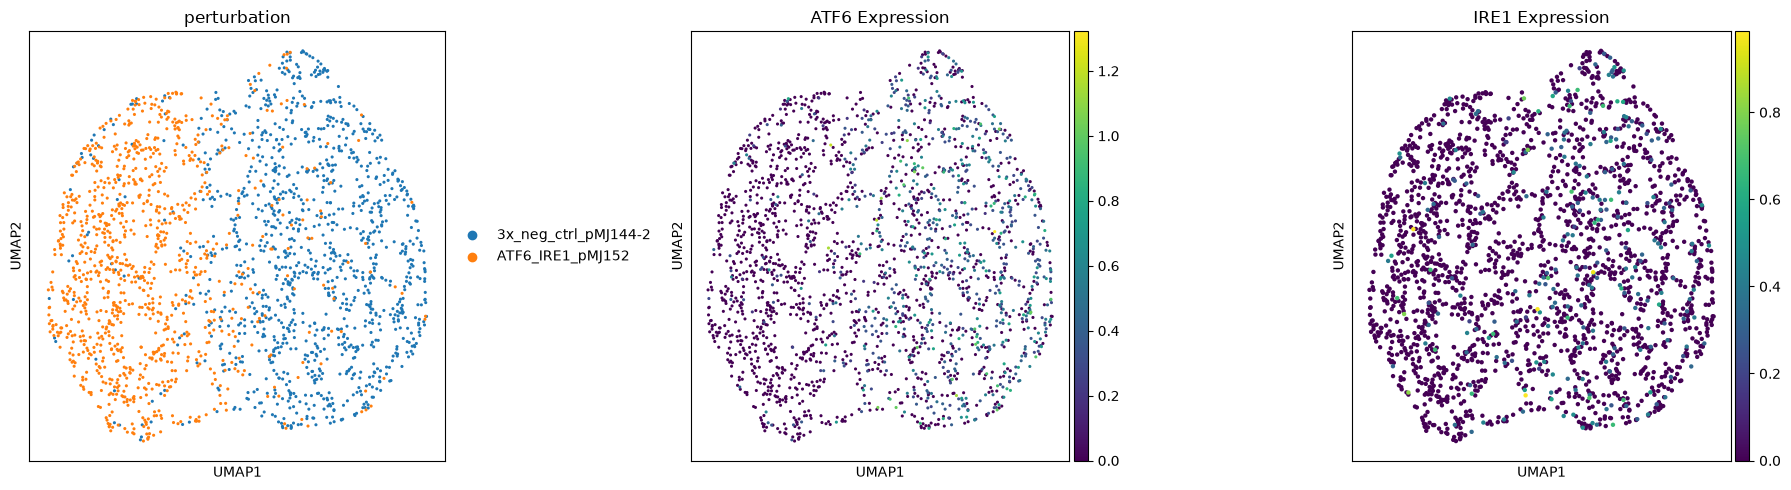

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sc.pl.umap(
    adata,
    color='perturbation',
    size=20,
    ax=axes[0],
    show=False
)

sc.pl.umap(
    adata,
    color='ATF6',
    size=20,
    title='ATF6 Expression',
    ax=axes[1],
    show=False
)

sc.pl.umap(
    adata,
    color='ERN1',
    size=40,
    title='IRE1 Expression',
    ax=axes[2],
    show=False
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1398368/3533477125.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_df = plot_df.groupby(group_col)[genes].mean()


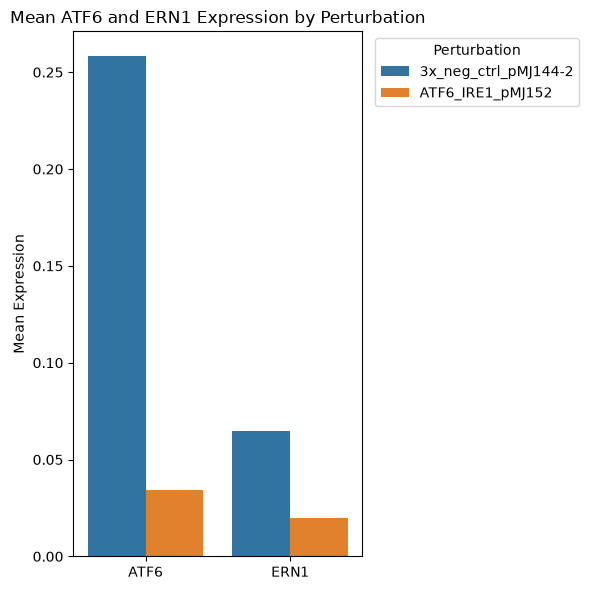

In [46]:
genes = ['ATF6', 'ERN1']
group_col = 'perturbation'

plot_df = adata[:, genes].to_df()
plot_df[group_col] = adata.obs[group_col].values

mean_df = plot_df.groupby(group_col)[genes].mean()

plot_long = mean_df.reset_index().melt(
    id_vars=group_col,
    var_name='Gene',
    value_name='Mean Expression'
)

group_order = mean_df.index.tolist()

fig, ax = plt.subplots(figsize=(6, 6))

sns.barplot(
    data=plot_long,
    x='Gene',
    y='Mean Expression',
    hue=group_col,
    hue_order=group_order,
    order=genes,
    errorbar=None,
    dodge=True,
    ax=ax
)

ax.set_xlabel('')
ax.set_ylabel('Mean Expression')
ax.set_title('Mean ATF6 and ERN1 Expression by Perturbation')
ax.legend(title='Perturbation', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()